# 24 · PyTorch en pratique 2 : améliorer, chercher, CNN et RNN — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookIA/blob/main/chapitres/ch24_pytorch_2/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wb.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | 24.Q1 à 24.Q12, 24.R1 à 24.R3, 24.1 à 24.5, 24.7 | vérifier tes réponses courtes | 🧠 🔁 ✏️ 🧮 | ★ à ★★ | |
| A | 24.11 | Changer un seul hyperparamètre : la taille de batch | 🔬 | ★★ | 30 |
|  | 24.12 | Prédire le classement de quatre MLP (784, 784 + 784, 64, 32 + 32) | 🔮 | ★★ | 25 |
|  | 24.13 | Dropout, max-norm et learning rate trop grand | 📦 | ★★ | 30 |
|  | 24.14 | Pourquoi la validation dépasse le train avec dropout | 📈 | ★ | 10 |
|  | 24.15 | Journal d'expériences : un run, une ligne | 🛠️ | ★★ | 20 |
| B | 24.16 | Un réseau PyTorch déguisé en estimateur scikit-learn | 📦 | ★★★ | 50 |
|  | 24.17 | Validation croisée stratifiée avec normalisation dans un Pipeline | 📦 | ★★ | 25 |
|  | 24.18 | Grille, hasard, puis zoom : chercher les hyperparamètres | 📦 | ★★★ | 45 |
| C | 24.19 | Un CNN traduit du Keras qui refuse de tourner | 🐛 | ★★ | 25 |
|  | 24.20 | Du CNN simple au CNN profond sur CIFAR-10 | 📦 | ★★★ | 45 |
|  | 24.21 | Batchnorm, dropout ou les deux : accuracy et écart entre train et validation d'un CNN | 🔬 | ★★★ | 40 |
|  | 24.22 | Prédire l'accuracy d'un CNN sur des images retournées, décalées, tournées ou en gris | 🔮 | ★ | 10 |
|  | 24.23 | Augmentation de données avec torchvision.transforms.v2 | 📦 | ★★★ | 45 |
|  | 24.24 | Des images synthétiques générées à la volée | 📦 | ★★ | 30 |
| D | 24.25 | Sommes de sinus et LSTM minuscule : fenêtres, scaler, RMSE | 📦 | ★★★ | 45 |
|  | 24.26 | Fenêtre, profondeur ou données : qu'est-ce qui aide vraiment ? | 🔬 | ★★★ | 45 |
|  | 24.27 | Séquences retournées, état porté entre batches, couche par pas de temps | 📦 | ★★★ | 40 |
| E | 24.28 | Au-delà de nn.Sequential : branches, addition, couches partagées, gel | 📦 | ★★★ | 45 |
|  | 24.29 | Précision mixte et torch.compile : mesurer avant de croire | 📦 | ★★ | 25 |
|  | 24.30 | Générer du texte : embeddings, séquences décalées, mots contre caractères | 📦 | ★★★★ | 100 |
|  | 24.31 | Défi CIFAR-10 frugal : au moins 80 % de test accuracy avec moins de 100 000 paramètres | 🏆 | ★★★★ | 180 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (CPU, a few minutes); False = full version
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookIA.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookIA")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WB_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wb").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wb").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier du workbook.")

os.environ["WB_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wb  # noqa: E402

cfg = wb.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mylearn = wb.load_mylearn("ref")  # reference implementation

🧪 Deep Learning Workbook : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.13 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | scikit-learn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cpu | torchvision 0.26.0+cpu
   Device : cpu | Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Améliorer un réseau par expériences : un hyperparamètre à la fois, dropout et max-norm, un journal de chaque run.
- Régler un réseau PyTorch avec scikit-learn : estimateur maison, `Pipeline`, validation croisée, recherches en grille et au hasard.
- Construire des CNN sur CIFAR-10 (stride, batchnorm, augmentation, blocs résiduels), préparer une série pour un LSTM, lire les sorties de `nn.LSTM`, générer du texte.

**Rappel express.** Mises à jour par epoch : $\lceil N/B \rceil$ ; bruit d'un mini-batch en $1/\sqrt{B}$. Dropout inversé : $\tilde h = m\,h/(1-p)$. Max-norm : $\mathbf{w} \leftarrow \mathbf{w}\min(1, c/\lVert\mathbf{w}\rVert)$. Coût d'une grille : $K \times \prod_j |V_j|$. Convolution : $C_{out}(C_{in}k^2 + 1)$ paramètres, $H_{out}W_{out}C_{out}C_{in}k^2$ MAC. `nn.LSTM(batch_first=True)` : `output` $(N, T, H)$, `h_n` $(L, N, H)$. Bloc résiduel : $y = F(x) + x$.

## Partie 0 · Vérifier tes réponses courtes (quiz, rappels, ✏️ 24.1 à 24.5 et 🧮 24.7)

Fais d'abord les quiz, les rappels et les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse courte ici : **la valeur** que tu as trouvée, pas l'expression Python, sinon tu ne vérifies rien. Un nombre : `42` ou `0.3` (en Python, le séparateur décimal est un **point** ; `0,3` sans guillemets serait un couple de deux nombres) ; un vrai ou faux : `True` ou `False` ; un choix : la lettre seule, entre guillemets (`"F"`) ; plusieurs lettres : entre guillemets (`"AF"`) ; une forme : entre guillemets (`"(3, 5, 1)"`). Arrondis comme l'énoncé le demande, et seulement à la fin du calcul. Les réponses pas encore remplies affichent ⏳. Les questions « dans ta copie », la dérivation ∂ 24.6, la réflexion (🗣️ 24.8, ⚖️ 24.9, 📄 24.10) et l'entretien se corrigent avec `05_solutions.md`.

In [2]:
# The short answers only use the numbers of their statements (02_exercices.md)
import math

import numpy as np


def softmax(z):
    z = np.asarray(z, dtype=float)
    e = np.exp(z - z.max())
    return e / e.sum()


def conv_params(c_in, c_out, k):
    """Parameters of nn.Conv2d(c_in, c_out, k): weights and biases."""
    return c_out * (c_in * k * k + 1)


def dense(n_in, n_out):
    """Parameters of nn.Linear(n_in, n_out): weights and biases."""
    return (n_in + 1) * n_out


def conv_mac(h_out, w_out, c_out, c_in, k):
    """Multiply-accumulates of one convolution, for one image."""
    return h_out * w_out * c_out * c_in * k * k


def lstm_layer_params(d_in, h):
    """Parameters of one PyTorch LSTM layer: 4 blocks of weights, two bias vectors."""
    return 4 * h * (d_in + h) + 2 * 4 * h


# Recall 24.R3: logits of three tokens
Z_R3 = np.array([2.0, 1.0, 0.0])

# Ex 24.2: the book's pooling CNN on MNIST (fig. 24.31), in PyTorch
P_CONV1, P_CONV2 = conv_params(1, 30, 5), conv_params(30, 16, 3)
N_FLAT = 16 * 7 * 7
P_DENSE = dense(N_FLAT, 128) + dense(128, 64) + dense(64, 10)
P_TOTAL = P_CONV1 + P_CONV2 + P_DENSE

# Ex 24.3: multiply-accumulates of one image, pooling version and stride version
MAC_POOL = conv_mac(28, 28, 30, 1, 5) + conv_mac(14, 14, 16, 30, 3)
MAC_STRIDE = conv_mac(14, 14, 30, 1, 5) + conv_mac(7, 7, 16, 30, 3)
MAC_DENSE = 784 * 128 + 128 * 64 + 64 * 10

# Ex 24.7: a small CNN, 25 million MAC per image, 20 epochs on 50 000 images
OPS_247 = 25e6 * 2 * 3 * 50_000 * 20
CPU_MIN_247 = OPS_247 / 50e9 / 60

**24.Q1 — Compter les hyperparamètres et n'en changer qu'un**

In [3]:
wb.record("24.Q1a", "BCE", mistakes={"les poids de la première couche sont calculés par l'entraînement, pas choisis": "ABCE",
          "les biais sont appris comme les poids": "BCDE",
          "l'état d'Adam est calculé pendant l'entraînement, pas choisi": "BCEF",
          "le taux de dropout se choisit avant l'entraînement": "BC",
          "le learning rate se choisit avant l'entraînement": "BE"})
wb.record("24.Q1b", 3 ** 6, mistakes={"chaque hyperparamètre multiplie le nombre de combinaisons, il ne l'additionne pas": 18,
          "3 valeurs pour chacun des 6 : 3 puissance 6, pas 6 puissance 3": 6 ** 3})
wb.record("24.Q1c", False, mistakes={"garder la valeur par défaut, est-ce un choix ou non ?": True})
wb.record("24.Q1d", False, mistakes={"si le meilleur réglage de A dépend de B, régler A une seule fois suffit-il ?": True})
wb.record("24.Q1e", "C", mistakes={"les objectifs se contredisent souvent : on ne peut pas tous les servir à la fois": "A",
          "le livre cherche un réglage assez bon, pas le meilleur exact": "B",
          "changer plusieurs choses à la fois empêche de savoir laquelle a agi": "D"})

WB_ANSWER {"hash": "7535440018c570516dc1bd2d665b20129a6cf67f971c2627edfa80442269bb91", "id": "24.Q1a", "kind": "str", "mistakes": {"03d9a9437cd14de6a9c199df4accda5bc694a8b0b4c37f31d2cd4c290a1b9f85": "les poids de la première couche sont calculés par l'entraînement, pas choisis", "2e16ebd3eec8d21018013bbab41f6f0962c529ebaea29f9d8923b715280fcebe": "le learning rate se choisit avant l'entraînement", "31b8b73e7d2896d332bb257b650c3642de20de06d25fa3a49679424ea1bc3ee8": "les biais sont appris comme les poids", "4db1c0c81cd5b12d7e2d0795a66eae365d94ba5aa67f76f61fe90d256394885e": "l'état d'Adam est calculé pendant l'entraînement, pas choisi", "f8fdba40f270717aa218f2bf8011d9024a48bca8f8d3ed1a5fc2f780f9b80e08": "le taux de dropout se choisit avant l'entraînement"}}
📝 Ex 24.Q1a : réponse enregistrée (str).
WB_ANSWER {"hash": "cfe8bddf6c44e3a5cb000218c600406188d31b646c6d7acb3acc570d947f2cf3", "id": "24.Q1b", "kind": "int", "magnitude": 2, "mistakes": {"8f0b963916da1094bfafaf59e8b265a5be66b53ec1a11d0

**24.Q2 — Taille de batch : bruit, overfitting et temps**

In [4]:
wb.record("24.Q2a", math.ceil(50_000 / 64), fractional="un nombre de mises à jour est entier : le dernier mini-batch, incomplet, compte aussi",
          mistakes={"arrondis au-dessus : le dernier mini-batch, incomplet, compte aussi": 50_000 // 64,
          "une mise à jour par mini-batch : divise N par la taille du mini-batch": 50_000})
wb.record("24.Q2b", math.ceil(50_000 / 256), fractional="un nombre de mises à jour est entier : le dernier mini-batch, incomplet, compte aussi",
          mistakes={"arrondis au-dessus : le dernier mini-batch, incomplet, compte aussi": 50_000 // 256,
          "une mise à jour par mini-batch : divise N par la taille du mini-batch": 50_000})
wb.record("24.Q2c", math.sqrt(400) / math.sqrt(16), decimals=1, mistakes={"l'écart-type varie comme 1/√B, pas comme 1/B": 25, "dans quel sens varie le bruit quand le batch rapetisse ?": 0.2})
wb.record("24.Q2d", False, mistakes={"compare le nombre de pas par epoch et le bruit de chaque pas dans les deux cas": True})
wb.record("24.Q2e", "A", mistakes={"plus de mini-batches par epoch, c'est plus de pas, chacun avec son coût fixe": "B",
          "relis la fig. 24.5 : la durée dépend bien de la taille de batch": "C"})

WB_ANSWER {"fractional": "un nombre de mises à jour est entier : le dernier mini-batch, incomplet, compte aussi", "hash": "f36d54ac5ebdc0f24e01b359b7c108befc6205b5a0d681c70d51a194fc1f0144", "id": "24.Q2a", "kind": "int", "magnitude": 2, "mistakes": {"2f5cf3d3ce2fccc922438ce0b65558c5dba93f0ea1bb4a47bb14bd919df9bfc2": "arrondis au-dessus : le dernier mini-batch, incomplet, compte aussi", "4c85b22a0ca8a78ef1822be236a624f77d5a32c279c0b655ea371b92d8ea1dc4": "une mise à jour par mini-batch : divise N par la taille du mini-batch"}, "sign": 1}
📝 Ex 24.Q2a : réponse enregistrée (int).
WB_ANSWER {"fractional": "un nombre de mises à jour est entier : le dernier mini-batch, incomplet, compte aussi", "hash": "daccf03da18216b2db23129333e604f6fa387883e8c95b4857bce32270584b69", "id": "24.Q2b", "kind": "int", "magnitude": 2, "mistakes": {"1047300144c433efc1e12723377537cf46e61a197f1a60852923d8c654c8457c": "arrondis au-dessus : le dernier mini-batch, incomplet, compte aussi", "86b618f51b64a6360d4accdbd68

**24.Q3 — Plus de neurones, moins de neurones, dropout**

In [5]:
wb.record("24.Q3a", "D", mistakes={"plus de neurones, c'est plus de capacité, pas moins": "A",
          "relis ce que montre la fig. 24.7 sur la loss de validation": "B",
          "un réseau plus grand apprend le train au moins aussi bien": "C"})
wb.record("24.Q3b", 0.3, decimals=1, mistakes={"p est la probabilité de mettre à zéro, pas de garder": 0.7, "une fraction entre 0 et 1, pas un pourcentage": 30})
wb.record("24.Q3c", "C", mistakes={"relis l'encadré « Le livre, corrigé » : le masque ne dure pas une epoch": "A",
          "chaque exemple du mini-batch a son propre masque": "B",
          "un masque fixe éteindrait toujours les mêmes neurones : ce serait un réseau plus petit": "D"})
wb.record("24.Q3d", 2.0 / (1 - 0.2), decimals=1, mistakes={"le dropout inversé divise les valeurs gardées par 1 − p : il ne les laisse pas telles quelles": 2.0,
          "on divise par 1 − p, on ne multiplie pas": 1.6, "on divise par 1 − p, pas par p": 10.0})
wb.record("24.Q3e", False, mistakes={"c'est le dropout d'origine qui multipliait par 1 − p en évaluation ; que fait le dropout inversé ?": True})

WB_ANSWER {"hash": "5534a8ecc770304a12a6d54502633ca979e563824cd8000348be1d74ff7b01fd", "id": "24.Q3a", "kind": "str", "mistakes": {"8a6d788ed8c86a40cc815ab864e5d3e03713c0df51a3d18388001957a27c1073": "un réseau plus grand apprend le train au moins aussi bien", "b6755eb63a1106d0d6e26bb5775bef9a1e157267df730efb97329d7c5213961e": "plus de neurones, c'est plus de capacité, pas moins", "c34a38ebe83cd11b46710d1b769a380e66582f1fd1295d76ea0a69bd17c68fce": "relis ce que montre la fig. 24.7 sur la loss de validation"}}
📝 Ex 24.Q3a : réponse enregistrée (str).
WB_ANSWER {"decimals": 1, "hash": "1168c2a3d51c97cf3da38d69f398e11f9d0e897321fb1e56a03ee26203119638", "hash_coarse": "335770dcbca8656f3015f3ebdda0b64269768606dd7c865893924b1e05602e5a", "id": "24.Q3b", "kind": "float", "magnitude": -1, "mistakes": {"b6f7e01c95f4fa7e81af51fe0f6d273975ee389288143c6dc85382d99581c298": "une fraction entre 0 et 1, pas un pourcentage", "fa36ba27e2989adcbf5e7fe0d9863fdd084bd506212cb4ba8918357477c29319": "p est la pr

**24.Q4 — Valider un réseau : coût, jeu non représentatif, normalisation dans chaque fold**

In [6]:
wb.record("24.Q4a", 5 * 40, mistakes={"chaque fold est un entraînement complet": 40,
          "la validation croisée seule, sans réentraînement final sur toutes les données": 6 * 40})
wb.record("24.Q4b", "A", mistakes={"2 000 radios sur 10 000, la taille n'est pas le problème : regarde leur provenance": "B",
          "rien ne fait passer les labels dans les données : regarde de quel hôpital viennent ces radios": "C",
          "regarde de quel hôpital viennent les 2 000 dernières radios": "D"})
wb.record("24.Q4c", "D", mistakes={"le pipeline ne fait rien gagner en vitesse": "A",
          "cross_val_score accepte n'importe quelles données": "B",
          "le scaler s'applique aux features, pas aux labels": "C"})
wb.record("24.Q4d", True, mistakes={"relis ce que scikit-learn fait d'un cv entier quand l'estimateur est un classifieur (ch. 15)": False})
wb.record("24.Q4e", "C", mistakes={"relis les scores du livre aux §24.3.2 et §24.3.3 de la fiche": "A",
          "compare les deux scores du livre, avec et sans normalisation": "B"})

WB_ANSWER {"hash": "a0fa4700d33f7434034892b49cc94b46b1ec08e09c6beb707cf4479b90512ef9", "id": "24.Q4a", "kind": "int", "magnitude": 2, "mistakes": {"85a75c9b192e8df0ca09ca6474f5376e54ad6fd49b0172478c506c36384aa1e0": "la validation croisée seule, sans réentraînement final sur toutes les données", "8d42e255554e043c5027c90c956f6d330a151a34227091f072adbca6053de070": "chaque fold est un entraînement complet"}, "sign": 1}
📝 Ex 24.Q4a : réponse enregistrée (int).
WB_ANSWER {"hash": "1ec9f848ab537260df9e7ee1fc4315105803b841f3877cbd6d047668b7d01839", "id": "24.Q4b", "kind": "str", "mistakes": {"45b7325fdef7e9bfc2a9e99fe58cb5a416189c6e384c4beec52572bc397f3215": "rien ne fait passer les labels dans les données : regarde de quel hôpital viennent ces radios", "8e82c92003c0b1dc2928bbce36732fa41544aaaf1cba5530fe9cf87cab28fe88": "2 000 radios sur 10 000, la taille n'est pas le problème : regarde leur provenance", "a6891d4766da68f29a7adabf18491024a39b33caea4764b007dc668f3c3b0334": "regarde de quel hôpit

**24.Q5 — 🕰️ KerasClassifier, grille, hasard ou zoom : chercher des hyperparamètres**

In [7]:
wb.record("24.Q5a", "C", mistakes={"KerasClassifier a été retiré de Keras et n'a jamais enveloppé de réseau PyTorch": "A",
          "MLPClassifier est le réseau de scikit-learn, pas ton nn.Module": "B",
          "un estimateur n'est qu'un objet qui suit quelques conventions": "D"})
wb.record("24.Q5b", 5, mistakes={"c'était la valeur par défaut en 2017, dans le livre ; relis l'encadré 🕰️": 3,
          "pense à la valeur par défaut, pas à un choix courant": 10,
          "c'est un réglage par défaut de scikit-learn, pas un calcul : relis l'encadré 🕰️ de la recherche": 4})
wb.record("24.Q5c", 2 * 3 * 2 * 4, mistakes={"chaque candidat est entraîné une fois par fold": 2 * 3 * 2,
          "multiplie les nombres de valeurs, ne les additionne pas": (2 + 3 + 2) * 4,
          "relis la question : on demande les entraînements de la validation croisée seulement": 2 * 3 * 2 * 4 + 1})
wb.record("24.Q5d", 2 * 3 * 2 * 4 + 1, mistakes={"relis la question : on demande le total, réentraînement final compris": 2 * 3 * 2 * 4,
          "un seul réentraînement final, pas un par candidat": 2 * 3 * 2 * 5})
wb.record("24.Q5e", "D", mistakes={"il s'agit de la finesse de la recherche, pas de la taille des images": "A",
          "le hasard est une autre méthode de recherche": "B",
          "il s'agit de la finesse de la recherche, pas du matériel": "C"})

WB_ANSWER {"hash": "5e7ab869e8be8f0593b2ee417807bce05ecb5a4536dd75d48ba85be632021294", "id": "24.Q5a", "kind": "str", "mistakes": {"27e5eae3b8a1ffa10ae390994cba975d61f5f9e1cdf195755f2fbe84b0e9847d": "KerasClassifier a été retiré de Keras et n'a jamais enveloppé de réseau PyTorch", "999c51a00968216436ba665bf3a069349b3f7bd8b46b3827b4adf0dfaddfe382": "MLPClassifier est le réseau de scikit-learn, pas ton nn.Module", "dba051a63e7bc2bffdf3e07ecadef54b33922a90cd870942ef8c0233fbb2dc1f": "un estimateur n'est qu'un objet qui suit quelques conventions"}}
📝 Ex 24.Q5a : réponse enregistrée (str).
WB_ANSWER {"hash": "36ba8da1d983443969c0892a75b6e23a4f2edaab7aca5c621760f0212fe3bbb6", "id": "24.Q5b", "kind": "int", "magnitude": 0, "mistakes": {"100fcf20a5a57e94c7692a1d116034205a6c36da93cb6dc3f360675e312faa44": "pense à la valeur par défaut, pas à un choix courant", "c874455b06bfe62250461e5b1525af243026a551b45052c68bce26bc407a7225": "c'est un réglage par défaut de scikit-learn, pas un calcul : relis l'

**24.Q6 — 🕰️ Couches utilitaires de Keras et leurs équivalents PyTorch**

In [8]:
wb.record("24.Q6a", "C", mistakes={"cette couche agrandit l'image : elle ne retire rien": "A",
          "elle répète des valeurs existantes ; elle n'ajoute pas de zéros": "B",
          "elle agrandit l'image ; un pooling la rétrécit": "D",
          "elle garde la forme d'une image": "E"})
wb.record("24.Q6b", "A", mistakes={"le recadrage retire des bords, il n'en ajoute pas": "B",
          "le recadrage rétrécit l'image": "C",
          "le recadrage garde les valeurs telles quelles, sans les résumer": "D",
          "le recadrage garde la forme d'une image": "E"})
wb.record("24.Q6c", "B", mistakes={"ZeroPadding2D ajoute des bords": "A",
          "ZeroPadding2D ajoute des zéros, il ne répète pas les valeurs": "C",
          "ZeroPadding2D agrandit l'image": "D",
          "ZeroPadding2D garde la forme d'une image": "E"})
wb.record("24.Q6d", "D", mistakes={"un pooling résume des blocs, il ne retire pas seulement les bords": "A",
          "un pooling rétrécit l'image": "B", "un pooling rétrécit l'image, il ne l'agrandit pas": "C",
          "un pooling garde la forme d'une image": "E"})
wb.record("24.Q6e", False, mistakes={"relis quand ce bruit est actif dans le tableau du §24.4.1": True})
wb.record("24.Q6f", "C", mistakes={"relis l'encadré « Le livre, corrigé » : ce ne sont pas les poids": "A",
          "la batchnorm agit pendant la passe avant, pas sur les gradients": "B",
          "la batchnorm agit dans le réseau, sur les sorties d'une couche": "D"})

WB_ANSWER {"hash": "1b38ca10065e46e32785cf96f27ac250941907cb960c8a2c242658a2347672b1", "id": "24.Q6a", "kind": "str", "mistakes": {"4bd3cc68cee70e6a4663dc22543d75ab6fdcf76629d35a1593c02b1e157188ca": "elle agrandit l'image ; un pooling la rétrécit", "d5653126b2333737d1243c64e8003c1029b815b918965a95e3221abb5752c36a": "elle répète des valeurs existantes ; elle n'ajoute pas de zéros", "f66402f7b893ee112d63386cdfa1fa0271c356d3bf84742b2b8ef071720d2206": "cette couche agrandit l'image : elle ne retire rien", "fc59435a310abe9169dcfecdf4c9897693758d08654ee29b4a2b31d03450c20b": "elle garde la forme d'une image"}}
📝 Ex 24.Q6a : réponse enregistrée (str).
WB_ANSWER {"hash": "545e0dca3b2d392a31c3939b2889156ff187ab9398fdb746e5d94a957d972530", "id": "24.Q6b", "kind": "str", "mistakes": {"288a7c8dadf64a3398bf7df6b65c1d977c745b496046e0a7a08894bc6f30371d": "le recadrage retire des bords, il n'en ajoute pas", "28ea71de789f65f40244559ed93e0b0226ed9876e0e19e1baf50bc2951e4a6da": "le recadrage garde la forme

**24.Q7 — Préparer des images pour nn.Conv2d**

In [9]:
wb.record("24.Q7a", "(16, 3, 32, 32)", mistakes={"PyTorch veut les canaux juste après l'axe des exemples": "(16, 32, 32, 3)",
          "n'oublie pas l'axe des exemples": "(3, 32, 32)"})
wb.record("24.Q7b", "D", mistakes={"reshape garde l'ordre de lecture : il mélangerait les pixels et les canaux": "A",
          "la forme est bonne, mais transpose(1, 3) échange aussi la hauteur et la largeur": "B",
          "écris la forme obtenue axe par axe : l'axe des canaux n'arrive pas en position 1": "C"})
wb.record("24.Q7c", "(16, 12, 32, 32)", mistakes={"padding=\"same\" garde la hauteur et la largeur": "(16, 12, 28, 28)",
          "relis la question : on demande la forme de la sortie de la convolution, pas celle de son entrée": "(16, 3, 32, 32)"})
wb.record("24.Q7d", False, mistakes={"relis la première des trois différences avec Keras au §24.4.3": True})
wb.record("24.Q7e", 51 / 127.5 - 1, decimals=1, mistakes={"x / 127,5 − 1 : n'oublie pas de retrancher 1": 0.4, "x / 127,5 − 1, pas x / 255": 0.2})
wb.record("24.Q7f", False, mistakes={"relis la deuxième des trois différences avec Keras au §24.4.3": True})

WB_ANSWER {"hash": "d7667eceef71615e09d0a17a03d7e36d54f71dd4ffed6b220a0d791d0829d8db", "id": "24.Q7a", "kind": "str", "mistakes": {"bf6f4fc11c27fac4312d734094b8f2de8110cbdb9292159e6afab8a5dd6f65de": "n'oublie pas l'axe des exemples", "eda772f4cfcd13ccaa0cc2f1fce352cf2b225b25b6ec8e0cd17226d90d6bd8ec": "PyTorch veut les canaux juste après l'axe des exemples"}}
📝 Ex 24.Q7a : réponse enregistrée (str).
WB_ANSWER {"hash": "0144b558a93711fd0494bed3e3e604793a966f5e802d0ce8144311f1a316de66", "id": "24.Q7b", "kind": "str", "mistakes": {"00ad01a6913171be1161c46c3cdf5821ee144df74599e063a18cc728209ef8ef": "écris la forme obtenue axe par axe : l'axe des canaux n'arrive pas en position 1", "0964626ad6f577dcd669d5b2b327a0b85fafe5bc5c6be3529c1849280b8b5dc0": "reshape garde l'ordre de lecture : il mélangerait les pixels et les canaux", "c0288261ec28024058a35b3a9135b1262584ea3beb1e7e3c0be3cd8b190e7fde": "la forme est bonne, mais transpose(1, 3) échange aussi la hauteur et la largeur"}}
📝 Ex 24.Q7b : rép

**24.Q8 — Augmentation et données synthétiques : quelles transformations sont plausibles ?**

In [10]:
wb.record("24.Q8a", "B", mistakes={"la validation doit ressembler aux données réelles : on ne l'augmente pas": "A",
          "le test doit ressembler aux données réelles": "C",
          "l'augmentation fabrique des exemples d'entraînement": "D"})
wb.record("24.Q8b", False, mistakes={"quand le Dataset tire-t-il ses transformations ?": True})
wb.record("24.Q8c", "C", mistakes={"trop forte, une augmentation empêche le modèle d'apprendre": "A",
          "une augmentation garde le label de l'image": "B",
          "on n'augmente jamais le test": "D"})
wb.record("24.Q8d", "D", mistakes={"le générateur fabrique les batches à la demande : la mémoire n'est pas en jeu": "A",
          "le learning rate est un réglage de l'optimiseur": "B",
          "le mélange n'a rien à voir avec la fin d'une epoch": "C"})
wb.record("24.Q8e", "B", mistakes={"un IterableDataset fabrique ses exemples à la demande : peut-il savoir d'avance combien il en a ?": "A", "la taille du batch est un réglage du DataLoader": "C"})
wb.record("24.Q8f", True, mistakes={"le modèle revoit-il deux fois le même exemple ?": False})

WB_ANSWER {"hash": "37a134ab97de18309323e1b8063fb349bb05cc3e582d341763e0cd3c44179e0e", "id": "24.Q8a", "kind": "str", "mistakes": {"38c0bb5c71130575d7e8b905307bccc1c4c604ddcfb7736d16fe4425dd72d754": "le test doit ressembler aux données réelles", "a1f75f75ffffca54faed35827191e1baaf1e609e781a8d8b00cac5ab4e23431a": "la validation doit ressembler aux données réelles : on ne l'augmente pas", "d18f42494ad6ca6f4bb66948f223df94e09ff7af4e5482b663870384deaf530f": "l'augmentation fabrique des exemples d'entraînement"}}
📝 Ex 24.Q8a : réponse enregistrée (str).
WB_ANSWER {"hash": "c3cb44add84a7a7f34be810227a2f4aad2e6787676920f828b1a6b18aa62096b", "id": "24.Q8b", "kind": "bool", "mistakes": {"811101af675316e34b68fb4b80611bdbb9b55f4cebe4d7e169578b4e1a3434f2": "quand le Dataset tire-t-il ses transformations ?"}}
📝 Ex 24.Q8b : réponse enregistrée (bool).
WB_ANSWER {"hash": "bc1babcd277d7e6213a4cc6a260ab6569b8eb79e3dc7fa5dc77dd20171a17395", "id": "24.Q8c", "kind": "str", "mistakes": {"33c03669a4708aa5e6

**24.Q9 — Motifs conv-conv-pool, stride contre pooling, batchnorm contre dropout**

In [11]:
wb.record("24.Q9a", "C", mistakes={"relis le listing 24.44 : la convolution est écrite sans activation": "A",
          "la batchnorm normalise la sortie de la convolution": "B"})
wb.record("24.Q9b", True, mistakes={"que devient un biais constant après la soustraction de la moyenne du canal ?": False})
wb.record("24.Q9c", 9 / 4, decimals=2, mistakes={"la surface est divisée par 4 : écris aussi le facteur des canaux": 0.25,
          "les canaux d'entrée et de sortie sont multipliés par 3 tous les deux : C_in × C_out est multiplié par 9": 0.75,
          "la hauteur et la largeur sont divisées par 2 : la surface est divisée par 4": 9,
          "relis l'énoncé : les canaux sont multipliés par 3": 1.0})
wb.record("24.Q9d", "A", mistakes={"compare les accuracies de validation du tableau du §24.4.4": "B",
          "compare les temps par epoch du tableau du §24.4.4": "C"})
wb.record("24.Q9e", "C", mistakes={"relis la fin du §24.4.5 : les grosses couches denses portent l'essentiel des paramètres": "A",
          "relis la fin du §24.4.5 : combien de valeurs un Flatten envoie-t-il à la couche dense ?": "B"})

WB_ANSWER {"hash": "44a71c2ab7a55263bd11a9234a726ebb378d7d54a04eb6bcc0b49fa5ddc6cdf6", "id": "24.Q9a", "kind": "str", "mistakes": {"793c6bc82cb42b1153fd805d84c698fe0cfcd25877dcbc8814810b6e0ef3d0c3": "la batchnorm normalise la sortie de la convolution", "ee382d70a86563384b6cb055895c95f4e7c7541fc993f2a6d86489c7087fa923": "relis le listing 24.44 : la convolution est écrite sans activation"}}
📝 Ex 24.Q9a : réponse enregistrée (str).
WB_ANSWER {"hash": "158cc385dc50b041da85cd6de8bcd28c836f20bb2b8330a34b61d87da4c9402b", "id": "24.Q9b", "kind": "bool", "mistakes": {"e1af28e95e89a5107a41344ee5c7988c961ba402e54ea3c0bc2c1f6abc27efff": "que devient un biais constant après la soustraction de la moyenne du canal ?"}}
📝 Ex 24.Q9b : réponse enregistrée (bool).
WB_ANSWER {"alt_coarse": ["c93942cac481c84f10e685af81f5bf08325937332d975aa7653e3f185f612998"], "decimals": 2, "hash": "e9c4704137e20e5ba021a73a895d1b26ce0ce89f3b3965795cfa6cdb4fc63966", "hash_coarse": "5ca2302f11185dda68a84033720ba9376522b04567

**24.Q10 — Séries pour un RNN : fenêtres, scaler, inverse_transform, RMSE**

In [12]:
wb.record("24.Q10a", "D", mistakes={"le scaler ne doit pas voir le test": "A", "un scaler par fenêtre changerait l'échelle d'un exemple à l'autre": "B",
          "le scaler s'ajuste sur les données d'entraînement": "C"})
wb.record("24.Q10b", "(500, 12, 1)", mistakes={"avec batch_first=True, l'axe des exemples vient en premier": "(12, 500, 1)",
          "n'oublie pas l'axe des features, même pour une seule variable": "(500, 12)"})
wb.record("24.Q10c", "A", mistakes={"une erreur se lit dans l'unité de ce qu'on prédit": "B"})
wb.record("24.Q10d", False, mistakes={"un scaler ajusté sur le test, c'est une fuite, et une autre échelle que celle apprise par le réseau": True})
wb.record("24.Q10e", "C", mistakes={"une sigmoïde écraserait la prédiction dans un intervalle": "A", "une softmax sert à des classes, pas à une valeur": "B"})
wb.record("24.Q10f", "B", mistakes={"un réseau plus gros n'est pas une référence simple": "A", "la RMSE du train ne dit rien de la prévision": "C"})

WB_ANSWER {"hash": "d1fbb22000b1c1874669bc08dac4809d3e48e9c8c0897dec0e859d2762d581e2", "id": "24.Q10a", "kind": "str", "mistakes": {"00ca648877786ddbde127857e5b1a07c57cbbf39d693bc04112d0921eda013cd": "un scaler par fenêtre changerait l'échelle d'un exemple à l'autre", "2d1fd2cba0921371d579ab9010b11f4ede8bdc0b0300afec156409d315631089": "le scaler s'ajuste sur les données d'entraînement", "9a2041c3f810ae4fcd21dcc52469d97e1e583ad50befa7df0fcbc38520fec55d": "le scaler ne doit pas voir le test"}}
📝 Ex 24.Q10a : réponse enregistrée (str).
WB_ANSWER {"hash": "ac2269e3208e93aad4ad83d32d52ea7f815ac637555966173108258e07a427d7", "id": "24.Q10b", "kind": "str", "mistakes": {"1366c94cfdad7d80bb896d6823be7c3d2deb9b9d0a3981cd1f567f65a62dbc85": "n'oublie pas l'axe des features, même pour une seule variable", "ffa4d48634bd336249c8db77c4083316cecedfe4fc0ba656a9ff25e982812e5d": "avec batch_first=True, l'axe des exemples vient en premier"}}
📝 Ex 24.Q10b : réponse enregistrée (str).
WB_ANSWER {"hash": "90f

**24.Q11 — 🕰️ return_sequences, stateful, TimeDistributed : que devient chaque option en PyTorch ?**

In [13]:
wb.record("24.Q11a", "D", mistakes={"h_n ne garde que le dernier pas": "A", "c_n est la mémoire du dernier pas": "B",
          "output[:, -1] ne garde que le dernier pas": "C"})
wb.record("24.Q11b", "A", mistakes={"h_n[0] est l'état de la première couche": "B", "c_n est la mémoire de la cellule, pas sa sortie": "C",
          "output[0] est la séquence du premier exemple": "D"})
wb.record("24.Q11c", "B", mistakes={"aplatir mélangerait tous les pas dans une seule couche dense": "A",
          "relis ce que fait nn.Linear sur un tenseur à trois dimensions": "C"})
wb.record("24.Q11d", "C", mistakes={"relis l'encadré « Le livre, corrigé » du §24.5.9 : deux exemples consécutifs d'un batch sont indépendants": "A",
          "chaque ligne a son propre état": "B"})
wb.record("24.Q11e", True, mistakes={"que devient le graphe du batch précédent après son backward() ?": False})
wb.record("24.Q11f", False, mistakes={"relis le début du §24.5.9 : de quel état part chaque séquence ?": True})

WB_ANSWER {"hash": "3fc5f467ecff5bd80562323ce3717924f8172f4fbc14671d24d1ac6a814e5907", "id": "24.Q11a", "kind": "str", "mistakes": {"59f3debe42dc3c976dc5b1b829d834ca3646bfc4a14efe5932354a901955eea0": "c_n est la mémoire du dernier pas", "a043b1008b5d824af031247d83d033885b3e7e3fc190b7ec2233bdd556949a88": "output[:, -1] ne garde que le dernier pas", "a21572d345c8061beb029a693690beab872b5402222594f1ae748957bc350f20": "h_n ne garde que le dernier pas"}}
📝 Ex 24.Q11a : réponse enregistrée (str).
WB_ANSWER {"hash": "001d8658f43eb1f249065499dedd64188bb33381b55a5da52f979a4f6f76a4b0", "id": "24.Q11b", "kind": "str", "mistakes": {"6d22d368907414b1e46155e5060b06577c70dd7fc36a11946ab0ede532d7c552": "c_n est la mémoire de la cellule, pas sa sortie", "8de0263a05cfebe3336b84db3ae4380247bacc7dbcc574894181d78c8b17a56d": "output[0] est la séquence du premier exemple", "e00013df684afda95884071c7bcb7162efe2e68692e6cdae70748960c3d69644": "h_n[0] est l'état de la première couche"}}
📝 Ex 24.Q11b : réponse en

**24.Q12 — 🕰️ API fonctionnelle de Keras 3 et forward() de PyTorch : branches, partage, gel**

In [14]:
wb.record("24.Q12a", "C", mistakes={"un module est un seul objet, avec un seul jeu de poids": "A",
          "appeler deux fois un module est permis": "B"})
wb.record("24.Q12b", "B", mistakes={"torch.cat met bout à bout, il n'additionne pas": "A", "torch.stack crée un nouvel axe": "C"})
wb.record("24.Q12c", "(4, 32, 8, 8)", mistakes={"dim=1 est l'axe des canaux": "(8, 16, 8, 8)", "torch.cat ne crée pas d'axe": "(4, 2, 16, 8, 8)",
          "torch.cat met bout à bout ; il n'additionne pas les valeurs": "(4, 16, 8, 8)"})
wb.record("24.Q12d", False, mistakes={"relis le piège classique du §24.6 : qu'est-ce qui change encore en mode train() ?": True})
wb.record("24.Q12e", "A", mistakes={"relis l'encadré « Le livre, corrigé » du §24.6.2 : le modèle se construit-il ?": "B",
          "qu'attend une convolution 2D en entrée ?": "C"})
wb.record("24.Q12f", True, mistakes={"relis l'encadré 🕰️ du §24.6": False})

WB_ANSWER {"hash": "b3296ecf1c8bb0b077590f31ab5f84e22b77a9ce12bdd2158a347f72556d0efc", "id": "24.Q12a", "kind": "str", "mistakes": {"77ff33e14d74c37fd305a1865977583f4ecde3ed18ae3395fca7cbfe6711133d": "appeler deux fois un module est permis", "f3ef1ee3083413e4ecb71205c42c45ad7eb27277bb6b525d7d44af8ba0831266": "un module est un seul objet, avec un seul jeu de poids"}}
📝 Ex 24.Q12a : réponse enregistrée (str).
WB_ANSWER {"hash": "fcf85688f22dbaea2458de910a55263031f43314f1e81e4fd8cbafbf95af527e", "id": "24.Q12b", "kind": "str", "mistakes": {"756c892bed23961736003fec427ab1918c9faf974333273c92a743eafdb56e77": "torch.cat met bout à bout, il n'additionne pas", "8c239a58d6b8933f6b70fd0c3109fab7f2e22f180b14ac810ab60406c9c26b1a": "torch.stack crée un nouvel axe"}}
📝 Ex 24.Q12b : réponse enregistrée (str).
WB_ANSWER {"hash": "d93b10acfefff99a760c9af381402e40b855552ab95794d164c69da3fff67443", "id": "24.Q12c", "kind": "str", "mistakes": {"625096111dde31ceac1303ace381845865b05364f35909b982ec5b1eacb9c

**24.R1 — Ch. 23 : Ce qu'un historique d'entraînement doit contenir pour comparer deux runs**

In [15]:
wb.record("24.R1a", "ABD", mistakes={"le test ne se regarde qu'une fois, à la fin : pas à chaque epoch": "ABDE",
          "une copie des poids à chaque epoch coûte trop de mémoire ; on garde le meilleur checkpoint": "ABCD",
          "le learning rate de chaque epoch aide à lire les courbes": "AB",
          "la loss d'entraînement fait partie de l'historique": "BD"})
wb.record("24.R1b", "BCD", mistakes={"la couleur des courbes ne distingue pas deux runs": "ABCD",
          "sans la graine, peux-tu refaire le run ?": "CD",
          "deux runs peuvent différer par un réglage laissé par défaut": "BD",
          "la durée et la machine comptent pour comparer des coûts": "BC"})
wb.record("24.R1c", False, mistakes={"relis comment train_one_epoch moyenne sa loss pendant que les poids changent": True})
wb.record("24.R1d", 5, mistakes={"relis comment les epochs sont numérotées dans l'énoncé": 4, "la meilleure epoch a la plus petite loss": 1,
          "cherche la plus petite des six valeurs": 3})

WB_ANSWER {"hash": "c04ab6c47a59bbbff10b36c81a6b5566c27c0781cfa99879214a91edbc9507ca", "id": "24.R1a", "kind": "str", "mistakes": {"231c748bcc7f1da8de343eb6b3905fcc8dcc8df05b7662d07a973c2f2197dddd": "le test ne se regarde qu'une fois, à la fin : pas à chaque epoch", "53327be919d0d000c6190e956332d779071b9073794e4db245df14637048110b": "une copie des poids à chaque epoch coûte trop de mémoire ; on garde le meilleur checkpoint", "7a72619d88c3343b47ff73e39aaec880df85d771c2bdd2d910afe695e6e91288": "le learning rate de chaque epoch aide à lire les courbes", "90c78ff0e760421c6d422a1e9b6731147a5126ce00c27ec71a74628183da4bcd": "la loss d'entraînement fait partie de l'historique"}}
📝 Ex 24.R1a : réponse enregistrée (str).
WB_ANSWER {"hash": "97cddf0c7706c26133418720b3bb8dd2ad500281b758b9790258d870a5635be0", "id": "24.R1b", "kind": "str", "mistakes": {"4f1afaaefb65ded7e3b8d2fe5f303a162ef12bf76393fb0cd9198fc8bf951866": "la durée et la machine comptent pour comparer des coûts", "6603c85ad8e838c8f18c

**24.R2 — Ch. 21 : Taille de sortie d'une convolution à padding 'same' et stride 2**

In [16]:
wb.record("24.R2a", math.ceil(28 / 2), mistakes={"avec un stride de 2, la taille est divisée par 2": 28,
          "« same » complète de zéros : la convolution ne perd pas les bords": (28 - 5) // 2 + 1})
wb.record("24.R2b", math.ceil(15 / 2), fractional="une hauteur est un nombre entier de lignes : arrondis au-dessus", mistakes={"Keras arrondit H/s au-dessus, pas au-dessous": 7})
wb.record("24.R2c", 5 // 2, mistakes={"le padding n'est pas la taille du noyau : combien de lignes faut-il ajouter de chaque côté ?": 5})
wb.record("24.R2d", (32 + 2 * 2 - 5) // 2 + 1, mistakes={"n'oublie pas le + 1 de la formule": 15,
          "avec un stride de 2, la sortie est deux fois plus petite": 32,
          "applique la formule avec le padding de c)": (32 - 5) // 2 + 1})
wb.record("24.R2e", (15 - 3) // 2 + 1, mistakes={"relis la question : on demande la sortie de nn.Conv2d sans padding, pas le « same » de Keras": 8, "n'oublie pas le + 1 de la formule": 6,
          "le stride vaut 2 : divise par 2": 13})
wb.record("24.R2f", True, mistakes={"relis le ch. 21 : PyTorch accepte-t-il un noyau pair avec padding=\"same\" ?": False})

WB_ANSWER {"hash": "e71ffba34cbf0d197a09298b44d72b0336a32f660475b81d857294cb20e3654b", "id": "24.R2a", "kind": "int", "magnitude": 1, "mistakes": {"5d6866e5ffd42a5f5007657cd548ba1c408776f720fee0e7eb7341a981e8ec65": "avec un stride de 2, la taille est divisée par 2", "843f07f2ee836b149bc20a7b3bff4de23412ca430f50fddf7cb47d496230b06a": "« same » complète de zéros : la convolution ne perd pas les bords"}, "sign": 1}
📝 Ex 24.R2a : réponse enregistrée (int).
WB_ANSWER {"fractional": "une hauteur est un nombre entier de lignes : arrondis au-dessus", "hash": "fa31566afd527a9b6245ceee406727590201da2ef2ffae78bb3ab4cb56d8400b", "id": "24.R2b", "kind": "int", "magnitude": 0, "mistakes": {"aad8ea55e191370ce95a889e4f12d38c334d716e5368ad1988518bd962c3f5ee": "Keras arrondit H/s au-dessus, pas au-dessous"}, "sign": 1}
📝 Ex 24.R2b : réponse enregistrée (int).
WB_ANSWER {"hash": "aec7fb9c81fae9b8e86de541b4dc0482473bda2aac32ead4168f87d7db3c5448", "id": "24.R2c", "kind": "int", "magnitude": 0, "mistakes": 

**24.R3 — Ch. 17 : Ce que change la division des logits avant le softmax**

In [17]:
wb.record("24.R3a", softmax(Z_R3).max(), decimals=3, mistakes={"la softmax prend des exponentielles, pas les logits eux-mêmes": 2 / 3,
          "c'est la plus grande probabilité qu'on demande": softmax(Z_R3).min()})
wb.record("24.R3b", softmax(Z_R3 / 0.5).max(), decimals=3, mistakes={"relis la question : on demande la probabilité pour T = 0,5": softmax(Z_R3 * 0.5).max(),
          "relis la question : c'est T = 0,5 qu'on demande": softmax(Z_R3).max()})
wb.record("24.R3c", softmax(Z_R3 / 2).max(), decimals=2, mistakes={"relis la question : on demande la probabilité pour T = 2": softmax(Z_R3 * 2).max(),
          "relis la question : c'est T = 2 qu'on demande": softmax(Z_R3).max()})
wb.record("24.R3d", "B", mistakes={"c'est quand T grandit que la distribution s'aplatit": "A",
          "regarde ce que deviennent les écarts entre logits divisés par un T minuscule": "C"})
wb.record("24.R3e", True, mistakes={"diviser par un nombre positif change-t-il l'ordre des logits ?": False})

WB_ANSWER {"decimals": 3, "hash": "abde04c127e90193cba3d87bee4324d6cdadc188f896256134314ba479653153", "hash_coarse": "9679bd026352abfa8c0d348ebb279990ebe39450bf56f9508ad1d501ad092838", "id": "24.R3a", "kind": "float", "magnitude": -1, "mistakes": {"e5d9ba73b178ec762ff4ed6d7a735f6d4f15bec9dc2e2cc2125376aac57b1a5f": "c'est la plus grande probabilité qu'on demande", "ed9e29e4eca38eebb2fd18ae9b7db59036986b5199fbe41a14bdc76ccac29015": "la softmax prend des exponentielles, pas les logits eux-mêmes"}, "sign": 1}
📝 Ex 24.R3a : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "972edbf49469eeef913a1f08a9c66a66e8be8811184064eb7a8bd6faf3b1b232", "hash_coarse": "c582e796b55c8dc662d43677316e5ee13e08728a050139bc9bce9da9fce2a7e7", "id": "24.R3b", "kind": "float", "magnitude": -1, "mistakes": {"3eb7e68c130b95cdf9080d76dd4c884d1bb0909711a71927aa644fd2ef0191a8": "relis la question : c'est T = 0,5 qu'on demande", "e9d7cc5ed262f9bbcf417bb29bd0fea04acefabf1aa9f3f5bf91bbf02c372f6

**Ex 24.1 — Le coût d'une grille (27 hyperparamètres, 54 entraînements) contre une recherche aléatoire : probabilité de tomber dans les 5 % meilleurs réglages en n essais**

In [18]:
wb.record("24.1a", 2 ** 27, mistakes={"2 valeurs pour chacun des 27 : 2 puissance 27, pas 27 au carré": 27 ** 2,
          "les nombres de valeurs se multiplient, ils ne s'additionnent pas": 54})
wb.record("24.1b", 2 ** 27 / (3600 * 24 * 365), decimals=1, mistakes={"tu as obtenu des jours : convertis-les en années": 2 ** 27 / (3600 * 24)})
wb.record("24.1c", 3 * (3 * 3 * 2), mistakes={"chaque candidat est entraîné une fois par fold": 18, "multiplie les nombres de valeurs": 3 * (3 + 3 + 2)})
wb.record("24.1d", 54 * 70 // 60, mistakes={"en minutes, pas en secondes": 54 * 70, "chaque candidat est entraîné une fois par fold": 18 * 70 // 60})
wb.record("24.1e", 1 - 0.95 ** 20, decimals=2, mistakes={"c'est la probabilité de tout rater ; on demande celle d'en trouver au moins un": 0.95 ** 20,
          "0,05 × 20 compterait deux fois les tirages qui réussissent ensemble": 1.0})
wb.record("24.1f", math.ceil(math.log(0.05) / math.log(0.95)), mistakes={"tu as arrondi au plus proche : un nombre de tirages doit suffire, vérifie 0,95ⁿ ≤ 0,05 pour ton n": 58,
          "0,05 × n ≥ 1 additionne les chances des tirages : des tirages indépendants ne s'additionnent pas": 20},
          fractional="un nombre de tirages est entier : prends le premier entier qui suffit")
wb.record("24.1g", 1 - 0.95 ** 18, decimals=3, mistakes={"c'est la probabilité de tout rater ; on demande celle d'en trouver au moins un": 0.95 ** 18,
          "tu as pris le mauvais nombre de tirages": 1 - 0.95 ** 20})

WB_ANSWER {"hash": "16dd041cce398fc13053510d4062ecb76b1bab394dcac5da2c95455b87be3048", "id": "24.1a", "kind": "int", "magnitude": 8, "mistakes": {"906b38815db239f635808ca717e3c1eb4d93582486da63068d128c1b0adc4109": "les nombres de valeurs se multiplient, ils ne s'additionnent pas", "f8aa13d4ea9a289bfc7c402d79cf21fc3c856a9073977bf2867a9d03c4d0d321": "2 valeurs pour chacun des 27 : 2 puissance 27, pas 27 au carré"}, "sign": 1}
📝 Ex 24.1a : réponse enregistrée (int).
WB_ANSWER {"decimals": 1, "hash": "1de2873c6f787d2ec39e7a6beeae5be34487479340415a7597ab3bc5f479ba7f", "hash_coarse": "6294d97206194244d3bfd7eb91ff8e7951df039dda88e4c560fee4fd66de4168", "id": "24.1b", "kind": "float", "magnitude": 0, "mistakes": {"efce45d74a1777858e4f7f4400b97fc7d975613f23045574e2a1d559e1b49835": "tu as obtenu des jours : convertis-les en années"}, "sign": 1}
📝 Ex 24.1b : réponse enregistrée (float, 1 décimale(s)).
WB_ANSWER {"hash": "4c3c4190240c35baf17bc7174b19c6059e18303c2f5e68d37e804f04d3529736", "id": "24.

**Ex 24.2 — Formes et paramètres du CNN à pooling du livre**

In [19]:
wb.record("24.2a", "(256, 30, 28, 28)", mistakes={"avec padding=2, un noyau de 5 garde la taille": "(256, 30, 24, 24)",
          "PyTorch range les canaux juste après l'axe des exemples": "(256, 28, 28, 30)",
          "n'oublie pas l'axe des exemples": "(30, 28, 28)"})
wb.record("24.2b", "(256, 30, 14, 14)", mistakes={"relis la question : on demande la forme après le premier pooling": "(256, 30, 28, 28)",
          "le pooling ne change pas le nombre de canaux": "(256, 15, 14, 14)",
          "n'oublie pas l'axe des exemples": "(30, 14, 14)"})
wb.record("24.2c", P_CONV1, mistakes={"n'oublie pas les 30 biais": 30 * 25, "un filtre 5 × 5 a 25 poids, pas 5": 30 * (5 + 1)})
wb.record("24.2d", P_CONV2, mistakes={"n'oublie pas les 16 biais": 16 * 30 * 9, "chaque filtre a autant de canaux que l'entrée (30)": 16 * (9 + 1),
          "un filtre 3 × 3 a 9 poids par canal": 16 * (30 * 3 + 1)})
wb.record("24.2e", N_FLAT, mistakes={"compte aussi les canaux : 16 valeurs par position": 49,
          "la sortie du second pooling est en 7 × 7, pas en 14 × 14": 16 * 14 * 14, "la seconde convolution a 16 filtres, pas 30": 30 * 7 * 7})
wb.record("24.2f", dense(N_FLAT, 128), mistakes={"n'oublie pas les 128 biais": N_FLAT * 128, "la couche reçoit 16 × 7 × 7 valeurs": dense(49, 128)})
wb.record("24.2g", P_TOTAL, mistakes={"n'oublie pas les deux dernières couches denses": P_CONV1 + P_CONV2 + dense(N_FLAT, 128),
          "n'oublie pas les deux convolutions": P_DENSE,
          "la première couche dense reçoit 16 × 7 × 7 valeurs": P_CONV1 + P_CONV2 + dense(49, 128) + dense(128, 64) + dense(64, 10)})
wb.record("24.2h", P_DENSE / P_TOTAL, decimals=3, mistakes={"relis quelle part est demandée": (P_CONV1 + P_CONV2) / P_TOTAL,
          "une fraction entre 0 et 1, pas un pourcentage": 100 * P_DENSE / P_TOTAL,
          "les trois couches denses, pas seulement la première": dense(N_FLAT, 128) / P_TOTAL})

WB_ANSWER {"hash": "8d613b9427778519f677795cb45a6826ecfae2f7c350e23d4295880a7026bd03", "id": "24.2a", "kind": "str", "mistakes": {"2e94e95950a4432ea373e7fe5510d3f3cc66c784298b29e6b0024ff4f704fa59": "n'oublie pas l'axe des exemples", "4771ebec9131f58c3c0253c6733808ca407b828138b3017a10afb92c7872c225": "PyTorch range les canaux juste après l'axe des exemples", "91681555fcd0e577cc62b24dbd3ada0c4487d86ae7caca9cc88d391353c5b581": "avec padding=2, un noyau de 5 garde la taille"}}
📝 Ex 24.2a : réponse enregistrée (str).
WB_ANSWER {"hash": "d9dbc8cbc95985da7448de027e4c2d966f8c567b41f9f0b4d11c63c3520587fe", "id": "24.2b", "kind": "str", "mistakes": {"99af80c5d99136174eb1b2ec5afb18e6f1ee2ba91a3b519bf83355f0d4b960ae": "relis la question : on demande la forme après le premier pooling", "b40565d738ea8a2b5f38bc6ce7184f40ffaf87f079827db46a6c89cdfd057d07": "n'oublie pas l'axe des exemples", "dee76760c97696b82ad356dc69bf2517f9c531cbce9f8737efaa11bfb6fce029": "le pooling ne change pas le nombre de canaux

**Ex 24.3 — Stride ou pooling : compter les multiplications**

In [20]:
wb.record("24.3a", conv_mac(28, 28, 30, 1, 5), mistakes={"un noyau 5 × 5 compte 25 multiplications par position": conv_mac(28, 28, 30, 1, 1) * 5,
          "avec padding=2, la sortie est en 28 × 28": conv_mac(24, 24, 30, 1, 5)})
wb.record("24.3b", conv_mac(14, 14, 16, 30, 3), mistakes={"la seconde convolution travaille sur la sortie du premier pooling, en 14 × 14": conv_mac(28, 28, 16, 30, 3),
          "chaque filtre a 30 canaux d'entrée": conv_mac(14, 14, 16, 1, 3),
          "le pooling vient après la convolution : sa sortie est en 14 × 14, pas en 7 × 7": conv_mac(7, 7, 16, 30, 3)})
wb.record("24.3c", MAC_DENSE, mistakes={"les trois couches denses : 784 → 128 → 64 → 10": 784 * 128,
          "l'énoncé néglige les biais": 784 * 128 + 128 + 128 * 64 + 64 + 64 * 10 + 10,
          "la première couche dense reçoit 784 valeurs": 49 * 128 + 128 * 64 + 64 * 10})
wb.record("24.3d", MAC_STRIDE, mistakes={"avec un stride de 2, la seconde convolution sort en 7 × 7": conv_mac(14, 14, 30, 1, 5) + conv_mac(14, 14, 16, 30, 3),
          "les deux convolutions ensemble": conv_mac(14, 14, 30, 1, 5),
          "additionne les deux convolutions": conv_mac(7, 7, 16, 30, 3),
          "avec un stride de 2, la première convolution sort en 14 × 14": conv_mac(28, 28, 30, 1, 5) + conv_mac(7, 7, 16, 30, 3)})
wb.record("24.3e", (MAC_POOL + MAC_DENSE) / (MAC_STRIDE + MAC_DENSE), decimals=2, mistakes={"ajoute les couches denses aux deux versions": MAC_POOL / MAC_STRIDE,
          "la version à pooling au numérateur": (MAC_STRIDE + MAC_DENSE) / (MAC_POOL + MAC_DENSE)})
wb.record("24.3f", 30 * 14 * 14 * 3, mistakes={"3 comparaisons par valeur de sortie, pas par valeur d'entrée": 30 * 28 * 28 * 3,
          "compte les comparaisons, pas seulement les valeurs de sortie": 30 * 14 * 14,
          "n'oublie pas les 30 canaux": 14 * 14 * 3})
wb.record("24.3g", 147 / 36, decimals=1, mistakes={"le rapport de la version à pooling à la version à stride": 36 / 147})

WB_ANSWER {"hash": "fe9a37b1d302fb940fdc04e66a0920b51ca301e359d280af064d0cbf0da97daa", "id": "24.3a", "kind": "int", "magnitude": 5, "mistakes": {"4636068a727fc06c3a57517d93f68f1a7f0f17542ac00f50f6edb80f4205f183": "avec padding=2, la sortie est en 28 × 28", "46a283701fe5e8398065d090385be2c3080f6d7b7c61635e80b3fe6c7a5679f0": "un noyau 5 × 5 compte 25 multiplications par position"}, "sign": 1}
📝 Ex 24.3a : réponse enregistrée (int).
WB_ANSWER {"hash": "457330169657ac65baff7dbd65c44619f8fbf6ee698ec6a8a23045cfb4d316cd", "id": "24.3b", "kind": "int", "magnitude": 5, "mistakes": {"711932a0a363a4812c39052eb7cee3f8061b16633139fb8f36158a9493e1477a": "chaque filtre a 30 canaux d'entrée", "9b0af7b02dc044c1978f1fc69169d8c635eca9dc103e2df1170e588d4e8694e1": "la seconde convolution travaille sur la sortie du premier pooling, en 14 × 14", "e6e72e804df8551a20b1ecf5b5049e926d84d2a617435e20d4a9a1646df099dc": "le pooling vient après la convolution : sa sortie est en 14 × 14, pas en 7 × 7"}, "sign": 1}
📝 

**Ex 24.4 — Ce que renvoie nn.LSTM : output, h_n et c_n**

In [21]:
wb.record("24.4a", "(8, 5, 4)", mistakes={"output a H valeurs par pas, pas D": "(8, 5, 3)", "avec batch_first=True, l'axe des exemples vient en premier": "(5, 8, 4)",
          "output garde tous les pas de temps": "(8, 4)"})
wb.record("24.4b", "(2, 8, 4)", mistakes={"batch_first ne change pas la forme de h_n": "(8, 2, 4)", "h_n a une ligne par couche": "(1, 8, 4)",
          "h_n a H valeurs par exemple": "(2, 8, 3)"})
wb.record("24.4c", "A", mistakes={"output[0] est la séquence du premier exemple : écris sa forme": "B",
          "c_n a la forme de h_n tout entier, pas celle d'une de ses lignes": "C",
          "output[:, :, 0] garde tous les pas de temps : écris sa forme": "D"})
wb.record("24.4d", "(8, 5, 8)", mistakes={"les deux sens sont côte à côte sur la dernière dimension": "(8, 10, 4)",
          "relis la question : on demande la forme avec bidirectional=True": "(8, 5, 4)"})
wb.record("24.4e", "(4, 8, 4)", mistakes={"relis la question : on demande h_n du LSTM bidirectionnel": "(2, 8, 4)", "les sens multiplient le nombre de lignes, pas H": "(2, 8, 8)"})
wb.record("24.4f", lstm_layer_params(3, 4) + lstm_layer_params(4, 4), mistakes={"PyTorch range deux vecteurs de biais par couche": 4 * 4 * (3 + 4) + 16 + 4 * 4 * (4 + 4) + 16,
          "la seconde couche reçoit H = 4 valeurs, pas D = 3": 2 * lstm_layer_params(3, 4),
          "un LSTM a quatre blocs de poids (les trois portes et le candidat)": (4 * (3 + 4) + 8) + (4 * (4 + 4) + 8),
          "n'oublie pas la seconde couche": lstm_layer_params(3, 4),
          "n'oublie pas la première couche": lstm_layer_params(4, 4)})
wb.record("24.4g", "(8, 5, 1)", mistakes={"nn.Linear remplace la dernière dimension seulement": "(8, 1)", "relis la question : on demande la sortie de nn.Linear(4, 1), pas celle du LSTM": "(8, 5, 4)"})
wb.record("24.4h", "(5, 8, 3)", mistakes={"sans batch_first, le temps vient en premier": "(8, 5, 3)", "les features restent sur la dernière dimension": "(3, 5, 8)"})

WB_ANSWER {"hash": "f7907cc11c64ca650dd88a086b5cf447ba3b315477310447a337c7a9b2f4f28d", "id": "24.4a", "kind": "str", "mistakes": {"4c2ef37cc919a6a92c018a35c391fe7d13776679cebbb19005814ff1ec7a0e34": "output a H valeurs par pas, pas D", "ac3d75493f6d4264bda617062b5ac5ec5faf5f1edc1cf2e54f06f77fe77dc312": "avec batch_first=True, l'axe des exemples vient en premier", "f17558945f7ba5818a9116cae536afaf7a76d636a85eb45d6b431f41a835ca18": "output garde tous les pas de temps"}}
📝 Ex 24.4a : réponse enregistrée (str).
WB_ANSWER {"hash": "51ac475becc4ff41429772ded7ae329a8076a8f7633bbbd4a1d3e561de765a2a", "id": "24.4b", "kind": "str", "mistakes": {"1d3cf548bb15cc7d6023beea2f00f99bdfe9a3e0941bad18f0edbc97931dd4fa": "h_n a H valeurs par exemple", "2f07a14e3cc1a4bcc939533300c13b1343dd7f44eca8346c0114423912a57015": "batch_first ne change pas la forme de h_n", "60c40fb78ab4fe7ad75738a8ddf6758228b5acea7fbeb5b6b053c6fd4d6ea5fa": "h_n a une ligne par couche"}}
📝 Ex 24.4b : réponse enregistrée (str).
WB_ANSW

**Ex 24.5 — Fenêtres, pas d'optimisation et durée : de 200 à 20 000 points**

In [22]:
wb.record("24.5a", 200 - 13, mistakes={"la dernière fenêtre doit laisser une valeur pour sa cible": 200 - 13 + 1,
          "les fenêtres commencent à chaque pas : elles se chevauchent": 200 // 13})
wb.record("24.5b", 20_000 - 13, mistakes={"la dernière fenêtre doit laisser une valeur pour sa cible": 20_000 - 13 + 1,
          "les fenêtres commencent à chaque pas : elles se chevauchent": 20_000 // 13})
wb.record("24.5c", 20_000 - 13, mistakes={"un pas par exemple : compte les fenêtres, pas les points": 20_000})
wb.record("24.5d", math.ceil((20_000 - 13) / 32), fractional="un nombre de pas est entier : le dernier mini-batch, incomplet, compte aussi",
          mistakes={"arrondis au-dessus : le dernier mini-batch, incomplet, compte aussi": (20_000 - 13) // 32})
wb.record("24.5e", 100 * 5 / 60, decimals=1, mistakes={"en minutes, pas en secondes": 500, "tu as lu 8 min 20 s comme 8,20 min : une minute compte 60 s, pas 100": 8.2})
wb.record("24.5f", 28 * 3600 // 100, mistakes={"28 heures pour 100 epochs : divise par 100": 28 * 3600, "en secondes : une heure fait 3 600 s": 28 * 60 // 100})
wb.record("24.5g", 5 * (200 - 13) / (20_000 - 13), decimals=3, mistakes={"proportionnelle au nombre d'exemples, pas au nombre de points": 5 * 200 / 20_000,
          "la petite série a moins d'exemples : l'epoch dure moins de 5 s": 5 * (20_000 - 13) / (200 - 13)})

WB_ANSWER {"hash": "5a75a295a080e8d591953035db9c137f54d9ebd63bbc535f751bf7cf8a07f83b", "id": "24.5a", "kind": "int", "magnitude": 2, "mistakes": {"61dc4ef84b3d6ebaa082036f20a9c46f552beff8d3be327431ad0d64d8d49db2": "la dernière fenêtre doit laisser une valeur pour sa cible", "a25dc020bee603de2858ceee21b11815247f5ec57192ee7e44de3d12cefed705": "les fenêtres commencent à chaque pas : elles se chevauchent"}, "sign": 1}
📝 Ex 24.5a : réponse enregistrée (int).
WB_ANSWER {"hash": "6b4ed754e66795f26e29eddd0e5399ede5f59c2c8035a9bc21448f0e98b9ca7d", "id": "24.5b", "kind": "int", "magnitude": 4, "mistakes": {"8407b4c1e2af4e1445b17bbd963ba7138d257b9b4815e374dbb841dce0f7dc0f": "les fenêtres commencent à chaque pas : elles se chevauchent", "f3ea8305913ad4978bea72cd69190eff709970d3ac23be576f3a56cad2a51dec": "la dernière fenêtre doit laisser une valeur pour sa cible"}, "sign": 1}
📝 Ex 24.5b : réponse enregistrée (int).
WB_ANSWER {"hash": "5a90d74c9e6fffa05a515fe028b89529e9b111a635e8cb33aca628cfac5ae7c0

**Ex 24.7 — Fermi : le budget d'une recherche d'hyperparamètres sur CPU, sur GPU et en précision mixte**

In [23]:
wb.record("24.7a", round(OPS_247 / 1e12), mistakes={"compte 2 opérations par MAC": round(OPS_247 / 2 / 1e12),
          "un entraînement coûte 3 fois la passe avant": round(OPS_247 / 3 / 1e12),
          "en milliers de milliards (10¹²), pas en milliards": round(OPS_247 / 1e9),
          "n'oublie pas les 20 epochs": round(OPS_247 / 20 / 1e12)})
wb.record("24.7b", round(CPU_MIN_247), mistakes={"en minutes, pas en secondes": round(CPU_MIN_247 * 60), "en minutes, pas en heures": round(CPU_MIN_247 / 60),
          "un entraînement coûte 3 fois la passe avant": round(CPU_MIN_247 / 3)})
wb.record("24.7c", 4 * 3 * 3 * 3, mistakes={"chaque candidat est entraîné une fois par fold": 36, "multiplie les nombres de valeurs": (4 + 3 + 3) * 3})
wb.record("24.7d", round(108 * CPU_MIN_247 / 60), mistakes={"en heures, pas en minutes": round(108 * CPU_MIN_247), "n'oublie pas les 3 folds": round(36 * CPU_MIN_247 / 60)})
wb.record("24.7e", 108 * OPS_247 / 1e13 / 3600, decimals=2, mistakes={"en heures, pas en secondes": 108 * OPS_247 / 1e13, "en heures, pas en minutes": 108 * OPS_247 / 1e13 / 60})
wb.record("24.7f", 108 * OPS_247 / 1e13 / 2.5 / 60, decimals=1, mistakes={"2,5 fois plus vite : divise la durée, ne la multiplie pas": 108 * OPS_247 / 1e13 * 2.5 / 60,
          "en minutes, pas en heures": 108 * OPS_247 / 1e13 / 2.5 / 3600,
          "tu as lu des secondes comme des centièmes de minute : une minute compte 60 s, pas 100": 6.5})
wb.record("24.7g", round(30 * CPU_MIN_247 / 60), mistakes={"en heures, pas en minutes": round(30 * CPU_MIN_247),
          "un seul jeu de validation : un entraînement par réglage, pas trois": round(90 * CPU_MIN_247 / 60)})

WB_ANSWER {"hash": "e915a2887fbcec98d68943e0cd63d020f1145bb43b0f398097fe5d1c32b067e2", "id": "24.7a", "kind": "int", "magnitude": 2, "mistakes": {"3419354f0eadcf74970f5aebdf5c6efa1066fb8438afb4c016d1df374fabd2c1": "n'oublie pas les 20 epochs", "9d19566ea5ec0b0f63e4db1e9539f12d0779ef788a6135e1d274087efcb3a6ca": "un entraînement coûte 3 fois la passe avant", "be0e8bb1e78a7499a2ed3dc79602e52f64b7b9847eb72311a69efb1b65cd0975": "en milliers de milliards (10¹²), pas en milliards", "d442f7806bff44954bfad1a03011dcb1a59df24f7a4410a7d4474cb3d4c1fd96": "compte 2 opérations par MAC"}, "sign": 1}
📝 Ex 24.7a : réponse enregistrée (int).
WB_ANSWER {"hash": "e7f570db0a0a5b5b4791c806ba287e4dbbca455388d584e769c0376a2caa3247", "id": "24.7b", "kind": "int", "magnitude": 1, "mistakes": {"7054ba172e95da2aa5e55bae104894db6beb9ab4e051837c7a1bd4d4263ea853": "en minutes, pas en heures", "795f22d530036879723e4b0dcffa7cca122a610f094864c27404c809ec2a7684": "en minutes, pas en secondes", "d6c4294d3511f356971757eb1c

## Partie A · Améliorer un MLP sur Fashion-MNIST

Tu changes un seul hyperparamètre, la taille de batch (24.11) ; tu prédis le classement de quatre MLP (24.12) ; tu ajoutes dropout et max-norm, puis tu essaies des learning rates trop grands (24.13) ; tu expliques pourquoi la validation passe au-dessus de l'entraînement (24.14) ; puis tu tiens le journal de tous ces runs (24.15).

La cellule d'outils sert aux parties A à E. Elle importe PyTorch, choisit le device, prépare Fashion-MNIST comme au ch. 23 (le découpage stratifié, puis les `N_FASHION` premières images d'entraînement : 6 000 en mode rapide, 54 000 sinon ; `XA_TR`, `YA_TR`, et les 6 000 images de validation `XA_VAL`, `YA_VAL`, normalisées avec la moyenne et l'écart-type du train) et donne quatre outils : `make_mlp` (celui de la fiche), `make_loader` (des mini-batches mélangés avec leur propre graine), `evaluate` et `train_classifier`, une boucle comme ta `fit_18` du ch. 23, qui rend l'historique de chaque epoch (loss et accuracy d'entraînement **moyennées pendant l'epoch**, celles de validation après l'epoch, et la durée). `plot_histories` trace plusieurs historiques côte à côte.

In [24]:
# Tools for the notebook exercises (parts A to E)
import copy
import json
import math
import platform
import re
import subprocess
import tempfile
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from wb.nbtools import StopCheck, as_numpy, checked, filled, fitted, fr, pair, refuses, returned, same, shape_text, verdict, written

try:
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader, Dataset, IterableDataset, TensorDataset, get_worker_info
except ImportError:                       # a computer without PyTorch (Mac Intel): this chapter is done on Colab
    torch = None
    print("⏳ PyTorch absent sur cet ordinateur : ce chapitre se fait sur Colab (00_setup/INSTALL_LOCAL.md). Les "
          "cellules qui utilisent PyTorch affichent ⏳ au lieu de s'exécuter.")

    def _skip_torch_cells(lines):
        """IPython input transformer: without PyTorch, a cell that uses it prints ⏳ instead of stopping "Run all"."""
        if re.search(r"\b(torch|torchvision)\b|(?<![\w.])nn\.", "".join(lines)):
            return ['print("⏳ PyTorch absent sur cet ordinateur : cette cellule se fait sur Colab.")\n']
        return lines

    try:
        _shell = get_ipython()
    except NameError:                     # not in a notebook
        _shell = None
    if _shell is not None and all(getattr(f, "__name__", "") != "_skip_torch_cells" for f in _shell.input_transformers_cleanup):
        _shell.input_transformers_cleanup.append(_skip_torch_cells)

DEVICE = cfg.device                        # "cuda" if a GPU is available, else "cpu" (wb.setup)
WORK_DIR = Path(tempfile.mkdtemp(prefix="wb_ch24_"))   # a temporary folder for the files the exercises write
FASHION_CLASSES = wb.datasets.FASHION_CLASSES

# Fashion-MNIST (parts A and B): the stratified split of chapter 23, then the first N_FASHION training images
N_FASHION = 6_000 if FAST_MODE else 54_000
_X, _Y = wb.datasets.load_fashion_mnist("train", seed=None)
X_TR_IMG, X_VAL_IMG, Y_TR_ALL, Y_VAL = train_test_split(_X, _Y, test_size=0.1, stratify=_Y, random_state=0)
X_TR_IMG, Y_TR = X_TR_IMG[:N_FASHION], Y_TR_ALL[:N_FASHION]           # uint8 (N_FASHION, 28, 28), labels 0 to 9
MEAN_F = float((X_TR_IMG / 255.0).mean())                            # statistics of the training images only
STD_F = float((X_TR_IMG / 255.0).std())


def to_fashion_tensor(images):
    """uint8 images (N, 28, 28) -> float32 tensor (N, 1, 28, 28): (x / 255 - MEAN_F) / STD_F."""
    x = (np.asarray(images, dtype=np.float32) / 255.0 - np.float32(MEAN_F)) / np.float32(STD_F)
    return torch.from_numpy(x).unsqueeze(1)


XA_TR, YA_TR = to_fashion_tensor(X_TR_IMG), torch.from_numpy(Y_TR)       # part A: training...
XA_VAL, YA_VAL = to_fashion_tensor(X_VAL_IMG), torch.from_numpy(Y_VAL)   # ... and the 6 000 validation images


def n_params(model):
    """The number of parameters (learned numbers) of a torch module."""
    return sum(p.numel() for p in model.parameters())


def make_mlp(hidden=(784,), n_classes=10, p_drop=0.0):
    """The fiche's MLP: Flatten, then one Linear + ReLU (+ Dropout) per hidden size, then the output logits."""
    layers, n_in = [nn.Flatten()], 28 * 28
    for n_out in hidden:
        layers += [nn.Linear(n_in, n_out), nn.ReLU()]
        if p_drop > 0:
            layers.append(nn.Dropout(p_drop))
        n_in = n_out
    layers.append(nn.Linear(n_in, n_classes))
    return nn.Sequential(*layers)


def make_loader(x, y, batch_size=256, seed=0):
    """Shuffled mini-batches of the tensors x and y, in an order drawn from `seed` (its own torch.Generator)."""
    return DataLoader(TensorDataset(x, y), batch_size=batch_size, shuffle=True,
                      generator=torch.Generator().manual_seed(seed))


def evaluate(model, x, y, batch_size=1000):
    """(mean cross-entropy, accuracy) of `model` on the tensors x and y: eval mode, no graph, Python floats."""
    model.eval()
    loss_fn, total, correct = nn.CrossEntropyLoss(reduction="sum"), 0.0, 0
    with torch.inference_mode():
        for i in range(0, len(x), batch_size):
            xb, yb = x[i:i + batch_size].to(DEVICE), y[i:i + batch_size].to(DEVICE)
            logits = model(xb)
            total += loss_fn(logits, yb).item()
            correct += (logits.argmax(dim=1) == yb).sum().item()
    return total / len(x), correct / len(x)


def train_classifier(model, loader, x_val, y_val, epochs, lr=1e-3, seed=0, after_step=None, optimizer=None,
                     verbose=False):
    """Train `model` in place with the cross-entropy and Adam(lr) (or the given optimizer); `after_step(model)` is
    called after every optimizer step (a max-norm, for instance). Returns the history, one value per epoch:
    "train_loss" and "train_acc" (means over the mini-batches of the epoch, in train mode, what Keras prints),
    "val_loss" and "val_acc" (eval mode, after the epoch), "seconds" (the duration of the epoch)."""
    torch.manual_seed(seed)                               # the dropout masks
    model.to(DEVICE)
    optimizer = optimizer or torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "seconds": []}
    for epoch in range(1, epochs + 1):
        start = time.perf_counter()
        model.train()
        total, correct, count = 0.0, 0, 0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = model(xb)
            loss = loss_fn(logits, yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            if after_step is not None:
                after_step(model)
            total += loss.item() * len(xb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            count += len(xb)
        val_loss, val_acc = evaluate(model, x_val, y_val)
        for key, value in [("train_loss", total / count), ("train_acc", correct / count), ("val_loss", val_loss),
                           ("val_acc", val_acc), ("seconds", time.perf_counter() - start)]:
            history[key].append(value)
        if verbose:
            print(f"epoch {epoch:2d} · train {total / count:.4f} {correct / count:.4f} · val {val_loss:.4f} {val_acc:.4f}")
    return history


def plot_histories(histories, keys=("train_loss", "val_loss"), title=""):
    """One panel per key; one curve per history of the dict {name: history}; ends with plt.show()."""
    fig, axes = plt.subplots(1, len(keys), figsize=(5.5 * len(keys), 3.4), squeeze=False)
    for ax, key in zip(axes[0], keys):
        for name, history in histories.items():
            values = history[key]
            ax.plot(range(1, len(values) + 1), values, label=name)
        ax.set_title(key)
        ax.set_xlabel("epoch")
        ax.legend(fontsize=7)
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()


print(f"tools ready · torch {torch.__version__ if torch is not None else 'absent'} · device {DEVICE} · "
      f"Fashion-MNIST : {len(XA_TR)} training and {len(XA_VAL)} validation images (N_FASHION = {N_FASHION})")

tools ready · torch 2.11.0+cpu · device cpu · Fashion-MNIST : 6000 training and 6000 validation images (N_FASHION = 6000)


### Ex 24.11 — Changer un seul hyperparamètre : la taille de batch 🔬 ★★ ⏱️ 30 min
**Objectif :** mesurer ce que change la taille de batch (overfitting, bruit, temps), puis ce que change le learning rate avec elle.  
**Prérequis :** ch. 23 (Ex 23.18, boucle et historique) · 24.Q2 · 24.R1 · fiche §24.2.1, §24.2.2 · **Fil rouge :** Fashion-MNIST · **Parcours :** R, C

Le livre entraîne le même MLP avec des batches de 2 048, 512, 64 et 8 exemples. Tu refais l'expérience sur Fashion-MNIST, avec des batches de 1 024, 256, 64 et 16 (8 serait trop lent sur un CPU), puis un cinquième run qui change **deux** choses : des batches de 1 024 **et** un learning rate multiplié par 4.

**Contrat**
- `run_11(batch_size, lr=1e-3, epochs=EPOCHS_11, seed=2411)` entraîne le MLP du livre (`make_mlp((784,))`), ses poids tirés juste après `torch.manual_seed(seed)`, avec `train_classifier` sur `XA_TR`, `YA_TR` (validation `XA_VAL`, `YA_VAL`), des mini-batches de `make_loader(..., seed=seed)`, et rend l'historique ;
- `summary_11(history)` rend un dictionnaire de cinq nombres : `"best_epoch"` (l'epoch de la plus petite loss de validation, comptée à partir de 1), `"best_val_loss"`, `"final_gap"` (loss de validation moins loss d'entraînement, à la dernière epoch), `"final_val_acc"` et `"sec_per_epoch"` (la médiane des durées).

La vérification essaie `summary_11` sur un petit historique écrit à la main, puis la reproductibilité de `run_11` ; la cellule suivante lance les cinq runs (une vingtaine de secondes en mode rapide), affiche un tableau et trace les courbes.

Dans tes notes : quelle taille de batch surapprend le plus vite (regarde la meilleure epoch et l'écart final), et pourquoi, à learning rate égal, un petit batch va-t-il plus loin en une epoch ? Comment la durée d'une epoch varie-t-elle avec $B$, et que serait-ce sur un GPU ? Le cinquième run rattrape-t-il les batches de 256 ? Qu'est-ce que cela dit de la règle « un seul hyperparamètre à la fois » ?

In [25]:
EPOCHS_11 = 8 if FAST_MODE else 30
BATCH_SIZES_11 = (1024, 256, 64, 16)


def run_11(batch_size, lr=1e-3, epochs=EPOCHS_11, seed=2411):
    """The book's MLP (make_mlp((784,))), its weights drawn just after torch.manual_seed(seed), trained by
    train_classifier on XA_TR, YA_TR (validation: XA_VAL, YA_VAL) with Adam(lr), `epochs` epochs, and mini-batches of
    `batch_size` from make_loader(..., seed=seed): returns the history."""
    torch.manual_seed(seed)
    model = make_mlp((784,))
    loader = make_loader(XA_TR, YA_TR, batch_size=batch_size, seed=seed)
    return train_classifier(model, loader, XA_VAL, YA_VAL, epochs, lr=lr, seed=seed)


def summary_11(history):
    """Five numbers read from a history, in a dict:
    "best_epoch": the epoch (counted from 1) of the smallest validation loss; "best_val_loss": that loss;
    "final_gap": the validation loss minus the training loss of the last epoch;
    "final_val_acc": the validation accuracy of the last epoch; "sec_per_epoch": the median of history["seconds"]."""
    val = np.asarray(history["val_loss"])
    best = int(np.argmin(val))                            # an index, counted from 0
    return {"best_epoch": best + 1, "best_val_loss": float(val[best]),
            "final_gap": float(history["val_loss"][-1] - history["train_loss"][-1]),
            "final_val_acc": float(history["val_acc"][-1]), "sec_per_epoch": float(np.median(history["seconds"]))}


with checked("24.11"):
    toy_11 = {"train_loss": [0.9, 0.5, 0.3, 0.2], "train_acc": [0.6, 0.8, 0.9, 0.95], "val_loss": [0.8, 0.6, 0.65, 0.7],
              "val_acc": [0.7, 0.78, 0.79, 0.785], "seconds": [2.0, 1.0, 1.2, 9.0]}
    got_11 = summary_11(toy_11)
    if returned("24.11", "summary_11", got_11):
        want_keys_11 = {"best_epoch", "best_val_loss", "final_gap", "final_val_acc", "sec_per_epoch"}
        verdict("24.11", isinstance(got_11, dict) and set(got_11) == want_keys_11, "summary_11 rend les cinq clés.",
                f"attendu un dict aux clés {sorted(want_keys_11)}, reçu {got_11!r:.200}.")
        verdict("24.11", got_11.get("best_epoch") == 2, "best_epoch compte les epochs à partir de 1.",
                f"sur l'historique d'essai, la plus petite loss de validation est à la 2e epoch : attendu 2, reçu "
                f"{got_11.get('best_epoch')!r} (np.argmin donne un indice compté à partir de 0).")
        same("24.11", "summary_11(toy) : best_val_loss, final_gap, final_val_acc, sec_per_epoch",
             [got_11.get(k, np.nan) for k in ("best_val_loss", "final_gap", "final_val_acc", "sec_per_epoch")],
             [0.6, 0.5, 0.785, 1.6], rtol=1e-6)
    short_11 = run_11(1024, epochs=1)
    if returned("24.11", "run_11", short_11):
        again_11 = run_11(1024, epochs=1)
        verdict("24.11", isinstance(short_11, dict) and len(short_11.get("val_loss", [])) == 1
                and abs(short_11["val_loss"][0] - again_11["val_loss"][0]) < 1e-6,
                f"run_11(1024, epochs=1) : une epoch, loss de validation {fr(short_11['val_loss'][0])}, la même à chaque appel.",
                "run_11 doit rendre l'historique de train_classifier, et deux appels avec la même graine doivent donner "
                "le même résultat (torch.manual_seed(seed) avant de construire le modèle, make_loader(..., seed=seed)).")

✅ Ex 24.11 : summary_11 rend les cinq clés.
✅ Ex 24.11 : best_epoch compte les epochs à partir de 1.
✅ Ex 24.11 : summary_11(toy) : best_val_loss, final_gap, final_val_acc, sec_per_epoch : [0.6, 0.5, 0.785, 1.6], comme attendu.


✅ Ex 24.11 : run_11(1024, epochs=1) : une epoch, loss de validation 0,771, la même à chaque appel.


run                pas/epoch meilleure epoch val_loss min écart final val_acc finale  s/epoch
B = 1024                   6               7       0.4546      0.0918         0.8355     0.14
B = 256                   24               8       0.4159      0.1441         0.8500     0.18
B = 64                    94               3       0.4277      0.2223         0.8452     0.30
B = 16                   375               3       0.4296      0.2495         0.8403     0.99
B = 1024, lr × 4           6               7       0.4392      0.1151         0.8425     0.14


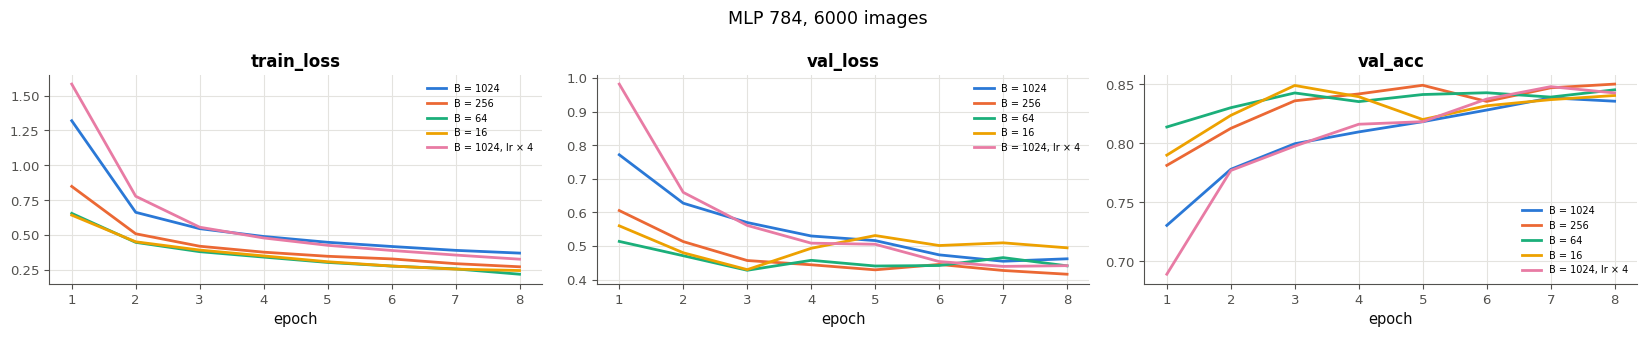

In [26]:
with checked("24.11"):
    runs_11 = {f"B = {b}": (b, 1e-3) for b in BATCH_SIZES_11}
    runs_11["B = 1024, lr × 4"] = (1024, 4e-3)                  # the batch AND the learning rate change
    histories_11 = {name: run_11(b, lr=lr) for name, (b, lr) in runs_11.items()}
    print(f"{'run':18s} {'pas/epoch':>9s} {'meilleure epoch':>15s} {'val_loss min':>12s} {'écart final':>11s} "
          f"{'val_acc finale':>14s} {'s/epoch':>8s}")
    for name_11, history_11 in histories_11.items():
        s_11 = summary_11(history_11)
        print(f"{name_11:18s} {math.ceil(len(XA_TR) / runs_11[name_11][0]):9d} {s_11['best_epoch']:15d} "
              f"{s_11['best_val_loss']:12.4f} {s_11['final_gap']:11.4f} {s_11['final_val_acc']:14.4f} "
              f"{s_11['sec_per_epoch']:8.2f}")
    plot_histories(histories_11, ("train_loss", "val_loss", "val_acc"), f"MLP 784, {len(XA_TR)} images")

💡 Les petits batches font beaucoup plus de pas par epoch (375 pour $B = 16$ contre 6 pour $B = 1\,024$ sur 6 000 images) : à learning rate égal, ils apprennent le train plus vite, atteignent leur meilleure loss de validation plus tôt (epoch 3 pour $B = 16$ et 64, contre 7 ou 8 pour les gros batches) et surapprennent davantage (l'écart final passe de 0,09 à 0,25). Une epoch de petits batches coûte aussi plus cher (environ 1 s contre 0,2 s ici) : chaque pas a un coût fixe, et un CPU, plus encore un GPU, calcule un gros batch presque aussi vite qu'un petit. Multiplier le learning rate par 4 avec des batches de 1 024 rattrape une partie du retard (84,3 % contre 83,6 %, sans atteindre les 85,0 % des batches de 256) : taille de batch et learning rate interagissent, si bien que « changer la taille de batch » change aussi la taille et le bruit de chaque pas. La règle « un seul hyperparamètre à la fois » reste une bonne méthode, à condition de savoir lesquels sont couplés.

### Ex 24.12 — Prédire le classement de quatre MLP (784, 784 + 784, 64, 32 + 32) 🔮 ★★ ⏱️ 25 min
**Objectif :** prédire, puis mesurer, l'effet de la largeur et de la profondeur d'un MLP sur l'overfitting et l'accuracy.  
**Prérequis :** Ex 24.11 · fiche §24.2.3 à §24.2.5 · **Fil rouge :** Fashion-MNIST · **Parcours :** R, C

La fiche résume ce que le livre observe sur MNIST avec ses quatre MLP : une couche de 784 neurones (A), deux couches de 784 (B), une couche de 64 (C), deux couches de 32 (D). Sur Fashion-MNIST, plus difficile, les écarts seront-ils les mêmes ? La cellule donnée définit `train_four_12`, qui entraîne les quatre modèles de la même façon : Adam, learning rate 0,001, mini-batches de 256, **15 epochs** sur les 6 000 premières images d'entraînement (les mêmes dans les deux modes), validation sur les 6 000 images de `XA_VAL`.

**Avant d'exécuter**, écris tes prédictions dans la cellule suivante :
a) quel modèle atteint sa plus petite loss de validation à l'epoch la **plus précoce** ? (`"A"`, `"B"`, `"C"` ou `"D"`)
b) après 15 epochs, C (64) a-t-il une meilleure accuracy de validation que A (784) ? (`True` ou `False`)
c) après 15 epochs, D (32 + 32) a-t-il une meilleure accuracy de validation que C (64) ? (`True` ou `False`)
d) à la 15ᵉ epoch, la loss de validation de B dépasse-t-elle **1,1 fois** sa plus petite valeur ? (`True` ou `False`)

La cellule d'expérience n'entraîne rien tant que tes quatre prédictions ne sont pas écrites (une trentaine de secondes ensuite).

In [27]:
EPOCHS_12 = 15                                   # the same in both modes, and the same 6 000 images
SHAPES_12 = {"A": (784,), "B": (784, 784), "C": (64,), "D": (32, 32)}


def train_four_12(seed=2412):
    """The four MLPs of the book, trained the same way: Adam(1e-3), mini-batches of 256, EPOCHS_12 epochs, the
    first 6 000 training images. Returns {letter: (number of parameters, history)}."""
    x_12, y_12 = XA_TR[:6000], YA_TR[:6000]
    out = {}
    for letter, hidden in SHAPES_12.items():
        torch.manual_seed(seed)
        model = make_mlp(hidden)
        out[letter] = (n_params(model), train_classifier(model, make_loader(x_12, y_12, 256, seed), XA_VAL, YA_VAL,
                                                         EPOCHS_12, seed=seed))
    return out

In [28]:
early_12, c_beats_a_12, d_beats_c_12, rise_12 = "B", False, False, True

In [29]:
wb.record("24.12a", "B", mistakes={"A n'a pas la plus petite valeur de la colonne « epoch du min »": "A", "C n'a pas la plus petite valeur de la colonne « epoch du min »": "C", "D n'a pas la plus petite valeur de la colonne « epoch du min »": "D"})
wb.record("24.12b", False, mistakes={"compare les accuracies de validation finales de A et de C dans le tableau": True})
wb.record("24.12c", False, mistakes={"compare les accuracies de validation finales de C et de D dans le tableau": True})
wb.record("24.12d", True, mistakes={"divise la loss de validation finale de B par sa plus petite valeur : le rapport dépasse-t-il 1,1 ?": False})

WB_ANSWER {"hash": "fa2fa86bda2107624de3061b3fa71493ea8d366fdc4e445c704e0c3c9c950fff", "id": "24.12a", "kind": "str", "mistakes": {"33d6b993b4292efa3b95ebb5c982111b600a0b5d929ffec35009c32382b71a7a": "A n'a pas la plus petite valeur de la colonne « epoch du min »", "8fdb6fc31783028c45e105602f9b90d1f60c34885ad3b3325b5e8ef3ed7da7da": "D n'a pas la plus petite valeur de la colonne « epoch du min »", "ec7fd99e18025676d28dbf57062cd9f6db0f54f761ea7741827b1b9d078b3a59": "C n'a pas la plus petite valeur de la colonne « epoch du min »"}}
📝 Ex 24.12a : réponse enregistrée (str).
WB_ANSWER {"hash": "1e325c04ab152d6d480e3419c35263d6975e6dd639a887bcf5ae3150847650fd", "id": "24.12b", "kind": "bool", "mistakes": {"8475619a89aab5b76ec863d0a2430dce9d1fa645bd76af006644f175eb253ff2": "compare les accuracies de validation finales de A et de C dans le tableau"}}
📝 Ex 24.12b : réponse enregistrée (bool).
WB_ANSWER {"hash": "a8f27b8acf6ed3ad1c306285e213c76ce2f8cfafe07f47ef8ca9db17a762daa9", "id": "24.12c", "k

modèle                       paramètres epoch du min val_loss min val_loss finale val_acc finale
A (784,)                         623290           10       0.4024          0.4112         0.8627
B (784, 784)                    1238730            9       0.4094          0.4753         0.8630
C (64,)                           50890           14       0.4280          0.4410         0.8430
D (32, 32)                        26506           15       0.4557          0.4557         0.8362


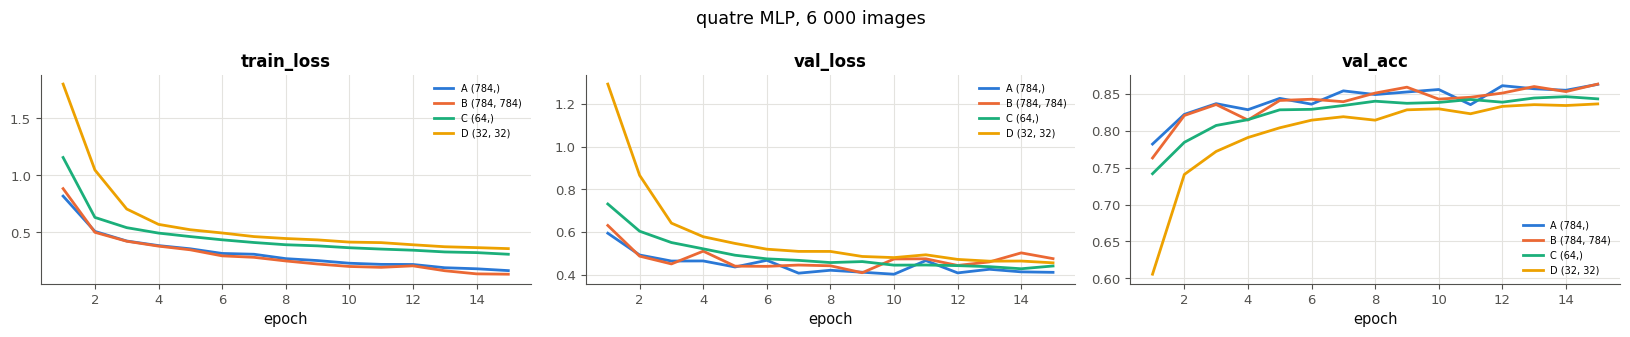

✅ Ex 24.12a : Parfait !
✅ Ex 24.12b : Bravo !
✅ Ex 24.12c : Exact !
✅ Ex 24.12d : Bien joué !


In [30]:
if any(answer is ... or answer is None for answer in [early_12, c_beats_a_12, d_beats_c_12, rise_12]):
    print("⏳ Ex 24.12 : écris d'abord tes quatre prédictions dans la cellule précédente.")
else:
    results_12 = train_four_12()
    print(f"{'modèle':28s} {'paramètres':>10s} {'epoch du min':>12s} {'val_loss min':>12s} {'val_loss finale':>15s} "
          f"{'val_acc finale':>14s}")
    for letter_12, (count_12, history_12) in results_12.items():
        val_12 = np.asarray(history_12["val_loss"])
        print(f"{letter_12} {str(SHAPES_12[letter_12]):26s} {count_12:10d} {int(np.argmin(val_12)) + 1:12d} "
              f"{val_12.min():12.4f} {val_12[-1]:15.4f} {history_12['val_acc'][-1]:14.4f}")
    plot_histories({f"{k} {SHAPES_12[k]}": h for k, (_, h) in results_12.items()}, ("train_loss", "val_loss", "val_acc"),
                   "quatre MLP, 6 000 images")
    wb.check("24.12a", early_12)
    wb.check("24.12b", c_beats_a_12)
    wb.check("24.12c", d_beats_c_12)
    wb.check("24.12d", rise_12)

Dans tes notes : lesquelles de tes prédictions étaient justes, et qu'est-ce qui t'a trompé ? Que fait la loss de validation de B après son minimum, et que fait son accuracy de validation pendant ce temps ? Combien de paramètres B a-t-il de plus que A, et qu'a-t-il gagné ? Avec une seule graine, laquelle de ces conclusions oserais-tu écrire dans un rapport ?

💡 B atteint le premier le minimum de sa loss de validation (epoch 9 ici, entre la 5ᵉ et la 9ᵉ selon la graine), puis cette loss remonte de 16 % en six epochs, alors que son accuracy de validation reste au niveau de celle de A (86,3 %) : le modèle devient plus sûr de lui, y compris sur ses erreurs. B a 615 440 paramètres de plus que A pour rien. Les petits modèles finissent 2 à 3 points en dessous (84,3 % pour C, 83,6 % pour D) et n'ont pas encore fini d'apprendre : leur minimum tombe à la 14ᵉ ou à la 15ᵉ epoch. D reste sous C, comme sur MNIST : deux couches de 32 ont deux fois moins de paramètres qu'une couche de 64. Les réponses vérifiées tiennent sur cinq graines (entrée `calib` de `tools/chapters/history_ch24.json`) ; le classement entre A et B, lui, change d'une graine à l'autre (quelques dixièmes de point) : on ne l'écrirait pas dans un rapport sans répéter (⚖️ 24.9).

### Ex 24.13 — Dropout, max-norm et learning rate trop grand 📦 ★★ ⏱️ 30 min
**Objectif :** programmer la contrainte de max-norm, l'appliquer avec le dropout, et voir ce que fait un learning rate trop grand avec Adam.  
**Prérequis :** Ex 24.12 · ∂ 24.6 · ch. 20 (dropout) · ch. 19 (Adam) · fiche §24.2.6 · **Fil rouge :** Fashion-MNIST · **Parcours :** R, C

Le livre ajoute à son MLP de 32 + 32 neurones un dropout de 0,2 après chaque couche cachée et une contrainte de max-norm, puis essaie les learning rates que conseillent les auteurs du dropout. La fiche montre la max-norm d'un MLP ; ta version vaut aussi pour les convolutions (le ∂ 24.6 a fait le calcul) et dit combien de vecteurs elle a ramenés.

**Contrat**
- `max_norm_13(model, c=3.0)` : pour chaque `nn.Linear` et chaque `nn.Conv2d` du modèle, **sauf la dernière** de ces couches (la sortie), les poids qui arrivent sur chaque neurone (une ligne du poids d'un `Linear`) ou sur chaque filtre (tous les poids d'un canal de sortie d'une `Conv2d`) dont la norme L2 dépasse `c` sont ramenés à la norme `c`, sans changer de direction ; les biais ne bougent pas ; tout se fait sur place, sans gradient, et les poids restent des paramètres qui apprennent ; la fonction rend le nombre de lignes ou de filtres ramenés ;
- `run_13(p_drop=0.0, c=None, lr=1e-3, epochs=EPOCHS_13, seed=2413)` entraîne `make_mlp((32, 32), p_drop=p_drop)`, ses poids tirés juste après `torch.manual_seed(seed)`, avec `train_classifier` (mini-batches de 256 de `make_loader(..., seed=seed)`, Adam, learning rate `lr`), et `max_norm_13(model, c)` après chaque pas quand `c` n'est pas `None` ; elle rend `(model, history)`.

La vérification essaie `max_norm_13` sur deux petits modèles dont les normes sont connues, puis `run_13` pendant une epoch ; la cellule suivante compare six runs (sans dropout ; dropout ; dropout et max-norm de 3, puis de 0,5 ; puis, avec la max-norm de 3, des learning rates de 0,01 et 0,1) et affiche la plus grande norme d'une ligne cachée à la fin.

Dans tes notes : que change le dropout à l'écart entre les losses d'entraînement et de validation ? La max-norm change-t-elle quelque chose de visible ici ? Que se passe-t-il avec un learning rate de 0,1, et pourquoi le conseil « 10 à 100 fois plus grand » ne vaut-il pas pour Adam ?

In [31]:
EPOCHS_13 = 15 if FAST_MODE else 50


def max_norm_13(model, c=3.0):
    """Max-norm constraint, in place and without gradient: for every nn.Linear and nn.Conv2d of `model` EXCEPT the
    last one of them (the output layer), the incoming weights of each neuron (a row of a Linear weight) or of each
    filter (all the weights of one output channel of a Conv2d) whose L2 norm exceeds c are rescaled to the norm c,
    without changing their direction. Biases are not touched. Returns the number of rescaled rows or filters."""
    layers = [m for m in model.modules() if isinstance(m, (nn.Linear, nn.Conv2d))][:-1]
    clipped = 0
    with torch.no_grad():                                 # a projection, not a learning step
        for layer in layers:
            norms = layer.weight.flatten(1).norm(dim=1)   # one norm per row (Linear) or per filter (Conv2d)
            clipped += int((norms > c).sum())
            layer.weight.copy_(torch.renorm(layer.weight, p=2, dim=0, maxnorm=c))
    return clipped


def run_13(p_drop=0.0, c=None, lr=1e-3, epochs=EPOCHS_13, seed=2413):
    """The MLP 784-32-32-10 with dropout p_drop after each hidden layer (make_mlp((32, 32), p_drop=p_drop)), its weights
    drawn just after torch.manual_seed(seed), trained by train_classifier on XA_TR, YA_TR (validation XA_VAL, YA_VAL)
    with Adam(lr), mini-batches of 256 from make_loader(..., seed=seed), and max_norm_13(model, c) after every step
    when c is not None. Returns (model, history)."""
    torch.manual_seed(seed)
    model = make_mlp((32, 32), p_drop=p_drop)
    after = None if c is None else (lambda m: max_norm_13(m, c))
    history = train_classifier(model, make_loader(XA_TR, YA_TR, 256, seed), XA_VAL, YA_VAL, epochs, lr=lr, seed=seed,
                               after_step=after)
    return model, history


with checked("24.13"):
    toy_13 = nn.Sequential(nn.Linear(3, 2), nn.ReLU(), nn.Linear(2, 2), nn.Linear(2, 4))
    with torch.no_grad():
        toy_13[0].weight.copy_(torch.tensor([[3.0, 4.0, 12.0], [1.0, 0.0, 0.0]]))      # norms 13 and 1
        toy_13[2].weight.copy_(torch.tensor([[0.0, 6.0], [2.0, 2.0]]))                # norms 6 and 2.83
        toy_13[3].weight.fill_(10.0)                                                  # the output layer: untouched
    bias_13 = toy_13[0].bias.detach().clone()
    param_13 = toy_13[0].weight                                         # the Parameter the optimizer knows
    count_13 = max_norm_13(toy_13, c=3.0)
    if returned("24.13", "max_norm_13", count_13):
        same("24.13", "poids de la 1re couche après max_norm_13(c=3)", toy_13[0].weight,
             [[9 / 13, 12 / 13, 36 / 13], [1.0, 0.0, 0.0]], rtol=1e-5, atol=1e-6)
        same("24.13", "poids de la 2e couche après max_norm_13(c=3)", toy_13[2].weight, [[0.0, 3.0], [2.0, 2.0]],
             rtol=1e-5, atol=1e-6)
        verdict("24.13", bool((toy_13[3].weight == 10.0).all()) and torch.equal(toy_13[0].bias, bias_13),
                "la couche de sortie et les biais ne bougent pas.",
                "la dernière couche (la sortie) et les biais ne doivent pas être touchés.")
        verdict("24.13", count_13 == 2, "max_norm_13 compte 2 lignes ramenées sur la sphère.",
                f"deux lignes dépassaient la norme 3 (13 et 6) : attendu 2, reçu {count_13!r}.")
        verdict("24.13", toy_13[0].weight is param_13 and toy_13[0].weight.requires_grad and toy_13[0].weight.grad_fn is None,
                "les poids restent des paramètres feuilles qui apprennent (pas de graphe créé).",
                "après max_norm_13, les poids doivent rester des paramètres feuilles : modifie-les sur place, sous "
                "torch.no_grad() (copy_), sans réaffecter layer.weight.")
    conv_13 = nn.Sequential(nn.Conv2d(1, 2, 2), nn.Flatten(), nn.Linear(2, 3))
    with torch.no_grad():
        conv_13[0].weight.copy_(torch.tensor([[[[2.0, 2.0], [2.0, 2.0]]], [[[0.5, 0.5], [0.5, 0.5]]]]))   # norms 4 and 1
    max_norm_13(conv_13, c=2.0)
    same("24.13", "filtres d'une Conv2d après max_norm_13(c=2) (norme de chaque filtre entier)",
         conv_13[0].weight.flatten(1).norm(dim=1), [2.0, 1.0], rtol=1e-5)
    model_13, history_13 = pair("24.13", "run_13(p_drop=0.2, c=0.3, epochs=1)", run_13(p_drop=0.2, c=0.3, epochs=1),
                                names=("model", "history"))
    norms_13 = torch.cat([m.weight.detach().norm(dim=1) for m in model_13.modules() if isinstance(m, nn.Linear)][:-1])
    kinds_13 = [type(m).__name__ for m in model_13]
    verdict("24.13", kinds_13.count("Dropout") == 2 and float(norms_13.max()) <= 0.3 + 1e-4,
            f"run_13 : deux Dropout, et avec c = 0,3 la plus grande norme d'une ligne cachée vaut {fr(float(norms_13.max()))} après une epoch.",
            f"attendu deux couches Dropout et des lignes cachées de norme ≤ 0,3 après une epoch avec c = 0,3 ; reçu {kinds_13} "
            f"et une norme maximale de {fr(float(norms_13.max()))} : la max-norm est-elle appliquée après chaque pas ?")
    verdict("24.13", history_13["val_acc"][-1] > 0.4,
            f"le modèle contraint apprend encore : {fr(100 * history_13['val_acc'][-1], 1)} % de validation après une epoch.",
            f"seulement {fr(100 * history_13['val_acc'][-1], 1)} % de validation après une epoch : si max_norm_13 remplace "
            "layer.weight au lieu de le modifier sur place, l'optimiseur met à jour l'ancien tenseur.")

✅ Ex 24.13 : poids de la 1re couche après max_norm_13(c=3) : [[0.69230771, 0.92307693, 2.76923084], [1.0, 0.0, 0.0]], comme attendu.
✅ Ex 24.13 : poids de la 2e couche après max_norm_13(c=3) : [[0.0, 3.0], [2.0, 2.0]], comme attendu.
✅ Ex 24.13 : la couche de sortie et les biais ne bougent pas.
✅ Ex 24.13 : max_norm_13 compte 2 lignes ramenées sur la sphère.
✅ Ex 24.13 : les poids restent des paramètres feuilles qui apprennent (pas de graphe créé).
✅ Ex 24.13 : filtres d'une Conv2d après max_norm_13(c=2) (norme de chaque filtre entier) : [2.0, 1.0], comme attendu.
✅ Ex 24.13 : run_13 : deux Dropout, et avec c = 0,3 la plus grande norme d'une ligne cachée vaut 0,300 après une epoch.
✅ Ex 24.13 : le modèle contraint apprend encore : 49,2 % de validation après une epoch.


run                            train_acc  val_acc train_loss  val_loss norme max  (dernière epoch)
sans dropout                      0.8695   0.8348     0.3589    0.4537     1.615
dropout 0,2                       0.8152   0.8255     0.5154    0.4775     1.482
dropout 0,2 + max-norm 3          0.8152   0.8255     0.5154    0.4775     1.482
dropout 0,2 + max-norm 0,5        0.7935   0.8107     0.5878    0.5270     0.500
dropout + max-norm 3, lr 0,01     0.8247   0.8198     0.4674    0.4826     3.000
dropout + max-norm 3, lr 0,1      0.3738   0.4888     1.5432    1.2908     3.000


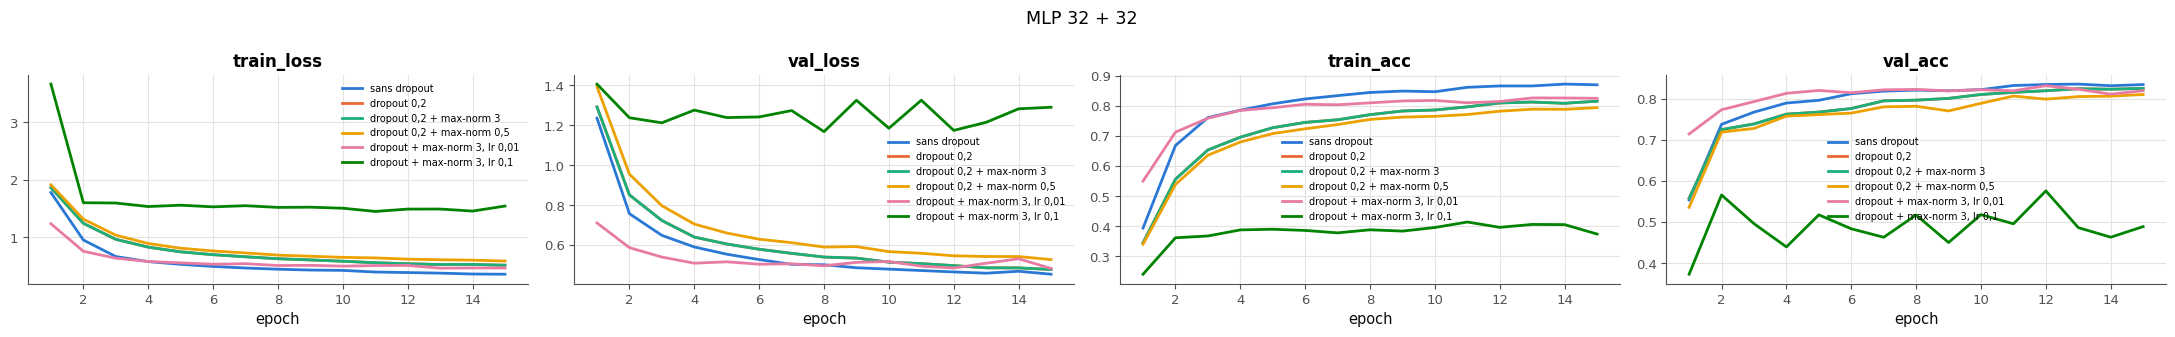

In [32]:
with checked("24.13"):
    runs_13 = {"sans dropout": dict(), "dropout 0,2": dict(p_drop=0.2), "dropout 0,2 + max-norm 3": dict(p_drop=0.2, c=3.0),
               "dropout 0,2 + max-norm 0,5": dict(p_drop=0.2, c=0.5),
               "dropout + max-norm 3, lr 0,01": dict(p_drop=0.2, c=3.0, lr=0.01),
               "dropout + max-norm 3, lr 0,1": dict(p_drop=0.2, c=3.0, lr=0.1)}
    histories_13, norms_13 = {}, {}
    for name_13, kwargs_13 in runs_13.items():
        model_13, histories_13[name_13] = run_13(**kwargs_13)
        hidden_13 = [m for m in model_13.modules() if isinstance(m, nn.Linear)][:-1]
        norms_13[name_13] = max(float(m.weight.detach().norm(dim=1).max()) for m in hidden_13)
    print(f"{'run':30s} {'train_acc':>9s} {'val_acc':>8s} {'train_loss':>10s} {'val_loss':>9s} {'norme max':>9s}  (dernière epoch)")
    for name_13, h_13 in histories_13.items():
        print(f"{name_13:30s} {h_13['train_acc'][-1]:9.4f} {h_13['val_acc'][-1]:8.4f} {h_13['train_loss'][-1]:10.4f} "
              f"{h_13['val_loss'][-1]:9.4f} {norms_13[name_13]:9.3f}")
    plot_histories(histories_13, ("train_loss", "val_loss", "train_acc", "val_acc"), "MLP 32 + 32")

💡 Le dropout rapproche les deux losses : celle d'entraînement monte (0,52 contre 0,36 : le réseau travaille avec des neurones éteints), celle de validation un peu aussi, et l'accuracy de validation perd un point en 15 epochs sur 6 000 images (82,6 % contre 83,5 %). La max-norm de 3 ne change **rien** ici : la plus grande norme d'une ligne cachée reste à 1,48, la contrainte ne s'active jamais, et les deux runs sont identiques au chiffre près. Une max-norm de 0,5, qui s'active, freine l'apprentissage (81,1 %). Avec un learning rate de 0,1, chaque pas d'Adam déplace chaque poids d'environ 0,1, des pas énormes pour des poids de l'ordre de 0,05 : l'accuracy de validation s'effondre à 49 % ; à 0,01, l'entraînement marche, un peu moins bien qu'à 0,001. Le conseil de Srivastava et coll. vaut pour SGD avec momentum, dont le pas est proportionnel au gradient ; celui d'Adam a déjà la taille du learning rate (ch. 19).

### Ex 24.14 — Pourquoi la validation dépasse le train avec dropout 📈 ★ ⏱️ 10 min
**Objectif :** séparer les deux raisons qui placent la courbe de validation au-dessus de celle d'entraînement.  
**Prérequis :** Ex 24.13 · 24.Q3 · 24.R1 · ch. 23 (Ex 23.18, moyenne pendant l'epoch) · fiche §24.2.6 · **Fil rouge :** Fashion-MNIST · **Parcours :** R, C

Comme dans la fig. 24.13 du livre, l'accuracy de validation de ton modèle à dropout passe au-dessus de celle d'entraînement. Est-ce que le modèle « généralise mieux que parfait » ? `HISTORY_14`, calculé à l'avance par `tools/chapters/history_ch24.py`, sépare les mesures : le MLP 32 + 32 avec dropout 0,2 et max-norm 3, entraîné 30 epochs sur les 54 000 images d'entraînement, avec à chaque epoch quatre accuracies :
- `"running_acc"` : la moyenne sur les mini-batches de l'epoch, en mode entraînement, ce qu'affichent Keras et `train_classifier` ;
- `"end_train_mode_acc"` : les poids de **fin** d'epoch, mesurés sur tout le train, dropout **actif** ;
- `"end_eval_mode_acc"` : les mêmes poids, sur tout le train, dropout **coupé** (`model.eval()`) ;
- `"val_acc"` : la validation, dropout coupé.

Réponds en calculant sur `HISTORY_14` (des listes, l'epoch 1 à l'indice 0) :
a) `above_14` : le nombre d'epochs (sur 30) où l'accuracy de validation est au-dessus de `"running_acc"` ;
b) `averaging_1_14` : à l'epoch 1, `"end_train_mode_acc"` moins `"running_acc"`, en points (1 décimale) ;
c) `averaging_late_14` : la même différence, en moyenne sur les epochs 21 à 30, en points (2 décimales) ;
d) `dropout_late_14` : `"end_eval_mode_acc"` moins `"end_train_mode_acc"`, en moyenne sur les epochs 21 à 30, en points (1 décimale) ;
e) `honest_gap_14` : `"end_eval_mode_acc"` moins `"val_acc"`, en moyenne sur les epochs 21 à 30, en points (1 décimale).

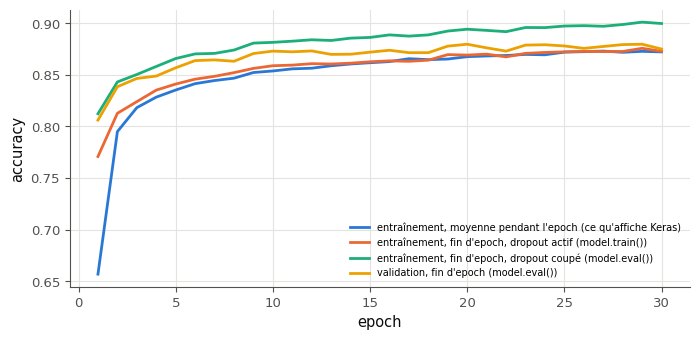

In [33]:
HISTORY_14 = {   # MLP 32 + 32, dropout 0.2 and max-norm 3, 30 epochs on 54 000 images (tools/chapters/history_ch24.py)
    "running_acc": [0.656778, 0.794852, 0.818074, 0.828259, 0.835148, 0.841315, 0.844333, 0.846611, 0.852111, 0.853611, 0.855648, 0.856278, 0.858648, 0.86037, 0.861593, 0.862685, 0.8655, 0.864556, 0.865167, 0.867444, 0.86813, 0.868593, 0.86963, 0.869278, 0.871852, 0.872296, 0.87287, 0.871685, 0.872611, 0.872074],
    "end_train_mode_acc": [0.770722, 0.812611, 0.823852, 0.835056, 0.840926, 0.845667, 0.848407, 0.851981, 0.856093, 0.858667, 0.859278, 0.860667, 0.860352, 0.861148, 0.8625, 0.863407, 0.862963, 0.864074, 0.869444, 0.869, 0.869907, 0.867259, 0.870667, 0.871556, 0.872148, 0.872593, 0.872407, 0.872481, 0.875556, 0.872611],
    "end_eval_mode_acc": [0.812148, 0.842963, 0.850185, 0.857981, 0.865648, 0.87013, 0.87063, 0.87387, 0.880611, 0.881333, 0.882463, 0.883815, 0.883148, 0.885407, 0.886093, 0.888556, 0.88737, 0.888556, 0.892278, 0.894056, 0.892907, 0.891685, 0.895704, 0.895611, 0.89713, 0.8975, 0.896907, 0.898593, 0.900926, 0.899574],
    "val_acc": [0.806, 0.838333, 0.846333, 0.848667, 0.856667, 0.863667, 0.864333, 0.863, 0.8705, 0.872833, 0.872167, 0.873, 0.869667, 0.869833, 0.871833, 0.873667, 0.871333, 0.871333, 0.877667, 0.8795, 0.876, 0.872833, 0.878667, 0.879, 0.877833, 0.8755, 0.877333, 0.879167, 0.8795, 0.874833],
}

fig_14, ax_14 = plt.subplots(figsize=(8, 3.6))
labels_14 = {"running_acc": "entraînement, moyenne pendant l'epoch (ce qu'affiche Keras)",
             "end_train_mode_acc": "entraînement, fin d'epoch, dropout actif (model.train())",
             "end_eval_mode_acc": "entraînement, fin d'epoch, dropout coupé (model.eval())",
             "val_acc": "validation, fin d'epoch (model.eval())"}
for key_14, label_14 in labels_14.items():
    ax_14.plot(range(1, 31), HISTORY_14[key_14], label=label_14)
ax_14.set_xlabel("epoch")
ax_14.set_ylabel("accuracy")
ax_14.legend(fontsize=7)
plt.show()

In [34]:
run_14 = np.asarray(HISTORY_14["running_acc"])
train_mode_14 = np.asarray(HISTORY_14["end_train_mode_acc"])
eval_mode_14 = np.asarray(HISTORY_14["end_eval_mode_acc"])
val_14 = np.asarray(HISTORY_14["val_acc"])
late_14 = slice(20, 30)                                   # epochs 21 to 30 (indices 20 to 29)
above_14 = int(np.sum(val_14 > run_14))
averaging_1_14 = round(100 * (train_mode_14[0] - run_14[0]), 1)
averaging_late_14 = round(100 * float(np.mean(train_mode_14[late_14] - run_14[late_14])), 2)
dropout_late_14 = round(100 * float(np.mean(eval_mode_14[late_14] - train_mode_14[late_14])), 1)
honest_gap_14 = round(100 * float(np.mean(eval_mode_14[late_14] - val_14[late_14])), 1)
print(above_14, averaging_1_14, averaging_late_14, dropout_late_14, honest_gap_14)

30 11.4 0.08 2.5 2.0


In [35]:
wb.record("24.14a", above_14, mistakes={"compare la validation à l'accuracy MOYENNE pendant l'epoch (running_acc), pas à celle de fin d'epoch en mode évaluation": 0})
wb.record("24.14b", averaging_1_14, decimals=1, mistakes={"en points : multiplie la différence d'accuracy par 100": averaging_1_14 / 100,
          "fin d'epoch MOINS moyenne pendant l'epoch, pas l'inverse": -averaging_1_14})
wb.record("24.14c", averaging_late_14, decimals=2, mistakes={"en points : multiplie la différence d'accuracy par 100": averaging_late_14 / 100,
          "moyenne sur les epochs 21 à 30 (indices 20 à 29), pas la seule epoch 30": 0.05})
wb.record("24.14d", dropout_late_14, decimals=1, mistakes={"mode évaluation MOINS mode entraînement, pas l'inverse": -dropout_late_14,
          "les deux mesures de FIN d'epoch, pas la moyenne pendant l'epoch": 2.6})
wb.record("24.14e", honest_gap_14, decimals=1, mistakes={"l'accuracy d'entraînement en mode ÉVALUATION (dropout coupé), pas celle de la moyenne pendant l'epoch": -0.6,
          "entraînement MOINS validation, pas l'inverse": -honest_gap_14})

WB_ANSWER {"hash": "db64672c1437edf454a44c713d82c05f237274d67f3b029ef60ea7ddff59e388", "id": "24.14a", "kind": "int", "magnitude": 1, "mistakes": {"700e1f24bea76b2080241d0e2e4012151f88ffc2904c396a8efce0f850d7b07f": "compare la validation à l'accuracy MOYENNE pendant l'epoch (running_acc), pas à celle de fin d'epoch en mode évaluation"}, "sign": 1}
📝 Ex 24.14a : réponse enregistrée (int).
WB_ANSWER {"decimals": 1, "hash": "5dd8037f252b19a22fa8d9de2a1b7331b46799b5166b2a03c7c4f5e3ce222432", "hash_coarse": "2f4716e96db27ff22c0f96625598c9b436093c8ef47c6f5317632449b81c83e8", "id": "24.14b", "kind": "float", "magnitude": 1, "mistakes": {"331b28a2c2453d1109acb5f5a4871a5244061a4228c3c969e94c04ba1d20fda2": "en points : multiplie la différence d'accuracy par 100", "faa7668f1dbcde4429515dfa53ec0d157be10393f212fa0fad8ab7207d023490": "fin d'epoch MOINS moyenne pendant l'epoch, pas l'inverse"}, "sign": 1}
📝 Ex 24.14b : réponse enregistrée (float, 1 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "79a

Dans tes notes : quelles sont les deux raisons pour lesquelles la courbe d'entraînement est sous celle de validation, et laquelle compte le plus en fin d'entraînement (b, c et d) ? Une fois les deux mesurées de la même façon (e), le modèle généralise-t-il « mieux que parfait » ? Quelle courbe faudrait-il tracer pour juger l'overfitting d'un modèle à dropout ?

💡 Deux effets s'ajoutent. La **moyenne pendant l'epoch** mélange des mini-batches vus par des poids plus anciens : énorme à la première epoch (11,4 points), elle devient négligeable quand le modèle change peu (0,08 point en moyenne sur les epochs 21 à 30). Le **dropout actif** pendant la mesure d'entraînement handicape le réseau, alors que la validation se fait dropout coupé : 2,5 points en fin d'entraînement, l'effet principal. C'est pourquoi la validation passe au-dessus de l'accuracy affichée pendant les 30 epochs. Mesurée en mode évaluation, l'accuracy d'entraînement dépasse celle de validation de 2,0 points : un peu d'overfitting, comme toujours. Pour juger l'overfitting d'un modèle à dropout, on compare des mesures faites de la même façon : le train évalué en mode évaluation contre la validation.

### Ex 24.15 — Journal d'expériences : un run, une ligne 🛠️ ★★ ⏱️ 20 min
**Objectif :** écrire un journal d'expériences en JSON lines, le relire et trouver le meilleur run.  
**Prérequis :** Ex 24.11 · Ex 24.13 · ch. 23 (Ex 23.28, fiche modèle) · fiche §24.2.7 (encadré « En entreprise ») · **Fil rouge :** Fashion-MNIST · **Parcours :** C

Après une dizaine de runs, qui se souvient des réglages du meilleur ? Tu écris le journal que conseille la fiche : **un run, une ligne** dans un fichier au format *JSON lines* (une ligne = un objet JSON complet, `.jsonl`), écrite à la fin de chaque entraînement, avec tout ce qu'il faut pour le refaire.

**Contrat**
- `git_commit_15()` rend le hash court du commit du workbook (`git rev-parse --short HEAD`, lancé dans `ROOT`, par `subprocess`), ou `None` si git manque ou que `ROOT` n'est pas un dépôt ;
- `log_run_15(path, params, metrics, seed)` **ajoute** une ligne au fichier `path` (créé s'il n'existe pas) et rend le dictionnaire écrit, tel qu'on le relirait : `{"time": l'heure UTC au format ISO 8601, "git": ..., "seed": ..., "params": ..., "metrics": ..., "versions": {"python": ..., "torch": ...}, "machine": platform.platform()}` ; les tuples deviennent des listes et les nombres NumPy des nombres Python, pour que n'importe quels réglages et métriques s'écrivent ;
- `read_runs_15(path)` rend la liste des runs, dans l'ordre du fichier ; `[]` si le fichier n'existe pas ; les lignes vides sont ignorées ;
- `runs_table_15(runs)` rend un `DataFrame` pandas, une ligne par run : `"time"`, `"git"`, `"seed"`, puis une colonne par réglage (`"params.lr"`…) et par métrique (`"metrics.val_acc"`…) ;
- `best_run_15(runs, metric="val_acc", mode="max")` rend le run dont `run["metrics"][metric]` est le plus grand (`"max"`) ou le plus petit (`"min"`).

La vérification écrit deux runs dans un fichier d'essai et les relit ; la cellule suivante note dans un journal les runs de 24.11 et de 24.13 (s'ils sont faits) et affiche le tableau.

Dans tes notes : quels réglages manquent encore pour refaire exactement un de ces runs (pense aux données, à la graine du mélange, au matériel) ? Pourquoi un fichier où l'on ajoute des lignes vaut-il mieux qu'un fichier réécrit à chaque run ?

In [36]:
def git_commit_15():
    """The short hash of the current commit of the workbook (`git rev-parse --short HEAD`, run in ROOT), or None when
    git is missing or ROOT is not a repository."""
    try:
        done = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=ROOT, capture_output=True, text=True, timeout=10)
    except (OSError, subprocess.SubprocessError):
        return None
    if done.returncode != 0:
        return None
    return done.stdout.strip() or None


def _plain_15(value):
    """json.dumps(default=...): NumPy numbers and arrays become Python numbers and lists."""
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, np.ndarray):
        return value.tolist()
    raise TypeError(f"not JSON serializable: {type(value).__name__}")


def log_run_15(path, params, metrics, seed):
    """Append ONE line to the JSON lines file `path` (created if needed) and return the dict written (as read back):
    {"time": the UTC time in ISO 8601, "git": git_commit_15(), "seed": seed, "params": params, "metrics": metrics,
     "versions": {"python": ..., "torch": ...}, "machine": platform.platform()}.
    Tuples become lists and NumPy numbers become Python numbers, so that any params and metrics can be written."""
    import datetime
    run = {"time": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"), "git": git_commit_15(),
           "seed": seed, "params": params, "metrics": metrics,
           "versions": {"python": platform.python_version(), "torch": torch.__version__}, "machine": platform.platform()}
    line = json.dumps(run, default=_plain_15, ensure_ascii=False)          # tuples are written as lists
    with open(path, "a", encoding="utf-8") as f:                           # "a": append, never overwrite
        f.write(line + "\n")
    return json.loads(line)


def read_runs_15(path):
    """The list of the runs (dicts) of the file, in order; [] if the file does not exist; blank lines are skipped."""
    path = Path(path)
    if not path.exists():
        return []
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]


def runs_table_15(runs):
    """A pandas DataFrame, one row per run: "time", "git", "seed", then one column per parameter ("params.lr", ...) and
    per metric ("metrics.val_acc", ...)."""
    table = pd.json_normalize(runs, sep=".")
    keep = ["time", "git", "seed"] + [c for c in table.columns if c.startswith(("params.", "metrics."))]
    return table[[c for c in keep if c in table.columns]]


def best_run_15(runs, metric="val_acc", mode="max"):
    """The run whose runs[i]["metrics"][metric] is the largest (mode "max") or the smallest (mode "min")."""
    pick = max if mode == "max" else min
    return pick(runs, key=lambda run: run["metrics"][metric])


with checked("24.15"):
    path_15 = WORK_DIR / "runs_check_15.jsonl"
    path_15.unlink(missing_ok=True)
    verdict("24.15", read_runs_15(path_15) == [], "un journal qui n'existe pas encore se lit comme une liste vide.",
            f"read_runs_15 d'un fichier absent : attendu [], reçu {read_runs_15(path_15)!r:.120}.")
    first_15 = log_run_15(path_15, {"hidden": (32, 32), "lr": np.float64(1e-3), "batch_size": 256},
                          {"val_acc": np.float32(0.875), "best_epoch": np.int64(7)}, seed=1)
    if returned("24.15", "log_run_15", first_15):
        log_run_15(path_15, {"hidden": (784,), "lr": 1e-3, "batch_size": 64}, {"val_acc": 0.861, "best_epoch": 3}, seed=2)
        lines_15 = [line for line in path_15.read_text(encoding="utf-8").splitlines() if line.strip()]
        verdict("24.15", len(lines_15) == 2, "deux runs, deux lignes : le fichier est complété, pas écrasé.",
                f"après deux appels, attendu 2 lignes dans le fichier, reçu {len(lines_15)} (ouvre-le en mode \"a\").")
        keys_15 = {"time", "git", "seed", "params", "metrics", "versions", "machine"}
        verdict("24.15", isinstance(first_15, dict) and set(first_15) == keys_15,
                "chaque ligne a ses sept champs.", f"attendu les champs {sorted(keys_15)}, reçu {sorted(first_15)!r:.200}.")
        verdict("24.15", first_15.get("params", {}).get("hidden") == [32, 32]
                and type(first_15.get("metrics", {}).get("best_epoch")) is int,
                "un tuple est écrit comme une liste, un entier NumPy comme un entier Python.",
                "les tuples doivent devenir des listes, et les nombres NumPy des nombres Python (json.dumps(..., default=...)).")
        stamp_15 = str(first_15.get("time", ""))
        verdict("24.15", re.fullmatch(r"\d{4}-\d\d-\d\dT\d\d:\d\d:\d\d(\.\d+)?(\+00:00|Z)", stamp_15) is not None,
                f"l'heure est en UTC, au format ISO 8601 : {stamp_15}.",
                f"attendu une heure UTC au format ISO 8601 (2026-05-04T09:30:00+00:00), reçu {stamp_15!r}.")
        commit_15 = git_commit_15()
        verdict("24.15", commit_15 is None or re.fullmatch(r"[0-9a-f]{4,40}", str(commit_15)) is not None,
                f"commit git : {commit_15}.", f"git_commit_15 doit rendre un hash court ou None, reçu {commit_15!r}.")
        runs_15 = read_runs_15(path_15)
        verdict("24.15", [r.get("seed") for r in runs_15] == [1, 2], "read_runs_15 relit les deux runs, dans l'ordre.",
                f"attendu les graines [1, 2] dans l'ordre du fichier, reçu {[r.get('seed') for r in runs_15]}.")
        fixed_15 = [{"time": "t1", "git": None, "seed": 1, "params": {"lr": 0.001}, "metrics": {"val_acc": 0.875, "best_epoch": 7},
                     "versions": {}, "machine": "m"},
                    {"time": "t2", "git": None, "seed": 2, "params": {"lr": 0.001}, "metrics": {"val_acc": 0.861, "best_epoch": 3},
                     "versions": {}, "machine": "m"}]                   # two runs written by hand
        table_15 = runs_table_15(fixed_15)
        verdict("24.15", list(table_15.columns[:3]) == ["time", "git", "seed"] and "params.lr" in table_15.columns
                and "metrics.val_acc" in table_15.columns and len(table_15) == 2,
                "runs_table_15 : une ligne par run, les colonnes params.* et metrics.*.",
                f"attendu les colonnes time, git, seed, params.*, metrics.*, reçu {list(table_15.columns)}.")
        verdict("24.15", best_run_15(fixed_15)["seed"] == 1 and best_run_15(fixed_15, "best_epoch", "min")["seed"] == 2,
                "best_run_15 trouve le meilleur run, en max comme en min.",
                "best_run_15 : le run de plus grande val_acc est le premier, celui de plus petite best_epoch le second.")

✅ Ex 24.15 : un journal qui n'existe pas encore se lit comme une liste vide.
✅ Ex 24.15 : deux runs, deux lignes : le fichier est complété, pas écrasé.
✅ Ex 24.15 : chaque ligne a ses sept champs.
✅ Ex 24.15 : un tuple est écrit comme une liste, un entier NumPy comme un entier Python.
✅ Ex 24.15 : l'heure est en UTC, au format ISO 8601 : 2026-10-29T19:08:35+00:00.
✅ Ex 24.15 : commit git : 6ca9aca.
✅ Ex 24.15 : read_runs_15 relit les deux runs, dans l'ordre.
✅ Ex 24.15 : runs_table_15 : une ligne par run, les colonnes params.* et metrics.*.
✅ Ex 24.15 : best_run_15 trouve le meilleur run, en max comme en min.


In [37]:
with checked("24.15"):
    journal_15 = WORK_DIR / "runs_ch24.jsonl"                 # in your own project: a file next to the code
    journal_15.unlink(missing_ok=True)
    for name_15, history_15 in (globals().get("histories_11") or {}).items():
        b_15, lr_15 = runs_11[name_15]
        s_15 = summary_11(history_15)
        log_run_15(journal_15, {"exercise": "24.11", "hidden": (784,), "batch_size": b_15, "lr": lr_15, "epochs": EPOCHS_11,
                                "optimizer": "Adam", "n_train": len(XA_TR)}, s_15, seed=2411)
    for name_15, history_15 in (globals().get("histories_13") or {}).items():
        kw_15 = runs_13[name_15]
        log_run_15(journal_15, {"exercise": "24.13", "hidden": (32, 32), "p_drop": kw_15.get("p_drop", 0.0),
                                "max_norm": kw_15.get("c"), "lr": kw_15.get("lr", 1e-3), "batch_size": 256,
                                "epochs": EPOCHS_13, "optimizer": "Adam", "n_train": len(XA_TR)},
                   {"final_val_acc": history_15["val_acc"][-1], "final_val_loss": history_15["val_loss"][-1]}, seed=2413)
    runs_15 = read_runs_15(journal_15)
    if runs_15:
        print(f"{len(runs_15)} runs dans {journal_15}")
        display(runs_table_15(runs_15).drop(columns=["time"]))
    else:
        print("⏳ Ex 24.15 : le journal se remplit avec les runs de 24.11 et 24.13 (fais-les d'abord).")

11 runs dans /tmp/wb_ch24__qcovi0g/runs_ch24.jsonl


,git,seed,params.exercise,params.hidden,params.batch_size,params.lr,params.epochs,params.optimizer,params.n_train,metrics.best_epoch,metrics.best_val_loss,metrics.final_gap,metrics.final_val_acc,metrics.sec_per_epoch,params.p_drop,params.max_norm,metrics.final_val_loss
0,6ca9aca,2411,24.11,[784],1024,0.001,8,Adam,6000,7.0,0.454586,0.091772,0.835500,0.142356,NaN,NaN,NaN
1,6ca9aca,2411,24.11,[784],256,0.001,8,Adam,6000,8.0,0.415938,0.144055,0.850000,0.184639,NaN,NaN,NaN
2,6ca9aca,2411,24.11,[784],64,0.001,8,Adam,6000,3.0,0.427698,0.222296,0.845167,0.301896,NaN,NaN,NaN
3,6ca9aca,2411,24.11,[784],16,0.001,8,Adam,6000,3.0,0.429595,0.249501,0.840333,0.988125,NaN,NaN,NaN
4,6ca9aca,2411,24.11,[784],1024,0.004,8,Adam,6000,7.0,0.439205,0.115055,0.842500,0.144422,NaN,NaN,NaN
5,6ca9aca,2413,24.13,"[32, 32]",256,0.001,15,Adam,6000,NaN,NaN,NaN,0.834833,NaN,0.0,NaN,0.453702
6,6ca9aca,2413,24.13,"[32, 32]",256,0.001,15,Adam,6000,NaN,NaN,NaN,0.825500,NaN,0.2,NaN,0.477473
7,6ca9aca,2413,24.13,"[32, 32]",256,0.001,15,Adam,6000,NaN,NaN,NaN,0.825500,NaN,0.2,3.0,0.477473
8,6ca9aca,2413,24.13,"[32, 32]",256,0.001,15,Adam,6000,NaN,NaN,NaN,0.810667,NaN,0.2,0.5,0.526961
9,6ca9aca,2413,24.13,"[32, 32]",256,0.010,15,Adam,6000,NaN,NaN,NaN,0.819833,NaN,0.2,3.0,0.482626


💡 Pour refaire un run à l'identique, il manque encore : l'identité des données (quelles images, quel découpage, une empreinte du fichier), toutes les graines (poids, mélange, dropout), les réglages laissés par défaut (les `betas` d'Adam, l'initialisation), et le matériel (CPU ou GPU, et les versions, déjà notées). Un fichier où l'on ajoute des lignes ne perd jamais un run, même quand deux entraînements écrivent l'un après l'autre ou qu'un run plante en route ; on le relit et on le trie quand on veut, c'est ce que font MLflow et Weights & Biases avec une interface en plus.

## Partie B · Un réseau PyTorch dans scikit-learn

Tu habilles un réseau PyTorch en estimateur scikit-learn (24.16) ; tu le valides par folds stratifiés, la mise à l'échelle dans un `Pipeline` (24.17) ; puis tu cherches ses hyperparamètres en grille, au hasard, puis par un zoom (24.18).

La cellule suivante importe ce dont la partie a besoin et prépare les **mêmes** images que la partie A sous la forme qu'aime scikit-learn : une ligne de 784 pixels bruts (de 0 à 255) par image (`XS_TR`, `XS_VAL`) et les **noms** des classes comme labels (`YS_TR`, `YS_VAL`). `SCALE_255` est une mise à l'échelle globale, qui divise tout par 255 et n'apprend rien.

In [38]:
from scipy.stats import loguniform, uniform
from sklearn.base import BaseEstimator, ClassifierMixin, clone, is_classifier
from sklearn.model_selection import GridSearchCV, KFold, RandomizedSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, MinMaxScaler

# Part B: the same images as part A, as scikit-learn likes them: one row of 784 raw pixels (0 to 255) per image,
# and the class NAMES as labels (an estimator must give back labels of the same kind)
XS_TR = X_TR_IMG.reshape(len(X_TR_IMG), -1).astype(np.float32)             # (N_FASHION, 784)
XS_VAL = X_VAL_IMG.reshape(len(X_VAL_IMG), -1).astype(np.float32)          # (6000, 784)
YS_TR = np.array(FASHION_CLASSES)[Y_TR]                                   # e.g. "Ankle boot"
YS_VAL = np.array(FASHION_CLASSES)[Y_VAL]


def divide_by_255(X):
    """A global scaling: every pixel divided by 255 (it learns nothing from the data)."""
    return np.asarray(X, dtype=np.float32) / 255.0


SCALE_255 = FunctionTransformer(divide_by_255)
print(XS_TR.shape, XS_TR.dtype, YS_TR[:3])

(6000, 784) float32 ['Shirt' 'Sandal' 'Pullover']


### Ex 24.16 — Un réseau PyTorch déguisé en estimateur scikit-learn 📦 ★★★ ⏱️ 50 min
**Objectif :** écrire un estimateur scikit-learn complet autour d'un réseau PyTorch, que clone, Pipeline et les recherches savent utiliser.  
**Prérequis :** ch. 15 (estimateurs, `clone`) · Ex 24.13 · ch. 23 (Ex 23.18, boucle) · fiche §24.3.1 · **Fil rouge :** Fashion-MNIST · **Parcours :** R, C

La fiche donne le squelette de `TorchMLPClassifier` (son `__init__`) et le contrat d'un estimateur. Écris `fit`, `predict_proba` et `predict`.

**Contrat**
- `__init__` est celui de la fiche (déjà écrit dans la cellule) : il range ses six arguments, rien d'autre ;
- `fit(X, y)` reçoit `X` de forme `(n, d)` (des nombres quelconques, convertis en `float32`) et `y` de forme `(n,)`, des labels **de n'importe quel genre** (entiers, chaînes…) ; il range `classes_` (les labels distincts, triés, comme `np.unique`), `n_features_in_` ($d$), `model_` (un `nn.Sequential` **neuf** : une couche `nn.Linear` + `nn.ReLU` (+ `nn.Dropout(p_drop)` si `p_drop > 0`) par taille de `hidden`, puis la couche de sortie, d'entrée $d$ et de sortie le nombre de classes) et `history_` (la loss moyenne d'entraînement de chaque epoch) ; il entraîne avec Adam (`lr`), la cross-entropy, `epochs` epochs de mini-batches de `batch_size` mélangés ; **tout** le hasard (poids, mélange, dropout) vient de `seed` ; il rend `self` ;
- `predict_proba(X)` rend un tableau NumPy `(n, nombre de classes)` de probabilités, colonnes dans l'ordre de `classes_`, calculé en mode évaluation sans graphe ; il lève `ValueError` si `X` n'a pas `n_features_in_` colonnes ;
- `predict(X)` rend les labels prédits, du même genre que le `y` de `fit` (pris dans `classes_`).

La vérification contrôle `is_classifier`, `get_params`, `clone` et `set_params`, entraîne ton estimateur sur des labels qui sont des **noms** de classes, contrôle les probabilités, la reproductibilité et un second `fit` sur des données d'une autre taille.

Dans tes notes : pourquoi `__init__` ne doit-il pas construire le réseau ? Que se passerait-il dans une validation croisée si `fit` réutilisait le réseau du `fit` précédent ?

In [39]:
class TorchMLPClassifier(ClassifierMixin, BaseEstimator):
    """A small PyTorch MLP dressed as a scikit-learn classifier."""

    def __init__(self, hidden=(32, 32), p_drop=0.2, lr=1e-3, epochs=5, batch_size=256, seed=0):
        self.hidden = hidden          # store, nothing else: clone() rebuilds from get_params()
        self.p_drop = p_drop
        self.lr = lr
        self.epochs = epochs
        self.batch_size = batch_size
        self.seed = seed

    def _network(self, n_in, n_out):
        layers = []
        for n in self.hidden:
            layers += [nn.Linear(n_in, n), nn.ReLU()]
            if self.p_drop > 0:
                layers.append(nn.Dropout(self.p_drop))
            n_in = n
        layers.append(nn.Linear(n_in, n_out))
        return nn.Sequential(*layers)

    def fit(self, X, y):
        """Train a NEW network on X (n, d), any numbers, and y (n,), labels of any kind (ints, strings...); store
        classes_ (the sorted distinct labels), n_features_in_ (d), model_ (the trained nn.Sequential) and history_
        (the mean training loss of each epoch); return self. Everything random comes from self.seed."""
        X = np.asarray(X, dtype=np.float32)
        self.classes_, codes = np.unique(np.asarray(y), return_inverse=True)   # labels -> 0 .. K-1
        self.n_features_in_ = X.shape[1]
        torch.manual_seed(self.seed)                                           # the weights and the dropout masks
        self.model_ = self._network(X.shape[1], len(self.classes_))
        loader = make_loader(torch.from_numpy(X), torch.from_numpy(codes.astype(np.int64)), self.batch_size, self.seed)
        optimizer = torch.optim.Adam(self.model_.parameters(), lr=self.lr)
        loss_fn = nn.CrossEntropyLoss()
        self.history_ = []
        for _ in range(self.epochs):
            self.model_.train()
            total = 0.0
            for xb, yb in loader:
                loss = loss_fn(self.model_(xb), yb)
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                total += loss.item() * len(xb)
            self.history_.append(total / len(X))
        return self

    def predict_proba(self, X):
        """(n, number of classes) NumPy probabilities, the columns in the order of classes_; ValueError when X does
        not have n_features_in_ columns."""
        X = np.asarray(X, dtype=np.float32)
        if X.ndim != 2 or X.shape[1] != self.n_features_in_:
            raise ValueError(f"X has {X.shape[-1]} features, the network was fitted with {self.n_features_in_}")
        self.model_.eval()
        with torch.inference_mode():
            logits = torch.cat([self.model_(torch.from_numpy(X[i:i + 4096])) for i in range(0, len(X), 4096)])
        return torch.softmax(logits, dim=1).numpy()

    def predict(self, X):
        """The predicted labels, of the same kind as the y given to fit (taken from classes_)."""
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


with checked("24.16"):
    est_16 = TorchMLPClassifier()
    verdict("24.16", is_classifier(est_16), "scikit-learn reconnaît un classifieur (ClassifierMixin avant BaseEstimator).",
            "is_classifier est faux : ClassifierMixin doit venir AVANT BaseEstimator dans la liste des classes mères.")
    want_params_16 = {"batch_size": 256, "epochs": 5, "hidden": (32, 32), "lr": 1e-3, "p_drop": 0.2, "seed": 0}
    verdict("24.16", est_16.get_params() == want_params_16, "get_params() rend les six réglages de __init__.",
            f"get_params() : attendu {want_params_16}, reçu {est_16.get_params()}.")
    other_16 = clone(est_16).set_params(hidden=(16,), lr=3e-3)
    verdict("24.16", other_16.hidden == (16,) and other_16.lr == 3e-3 and est_16.hidden == (32, 32),
            "clone puis set_params règlent une copie, sans toucher l'original.",
            "clone(est).set_params(hidden=(16,), lr=3e-3) doit changer la copie seulement.")
    small_16 = TorchMLPClassifier(hidden=(64,), epochs=3)
    fit_16 = small_16.fit(XS_TR / 255.0, YS_TR)
    verdict("24.16", fit_16 is small_16, "fit rend self (on peut écrire est.fit(X, y).predict(X)).",
            "fit doit rendre self.")
    verdict("24.16", list(getattr(small_16, "classes_", [])) == sorted(FASHION_CLASSES)
            and getattr(small_16, "n_features_in_", None) == 784 and isinstance(getattr(small_16, "model_", None), nn.Module),
            "après fit : classes_ (les 10 noms triés), n_features_in_ = 784, model_ (le réseau).",
            "après fit, attendu classes_ = les noms des classes triés (np.unique), n_features_in_ = 784 et model_ un nn.Module.")
    proba_16 = small_16.predict_proba(XS_VAL[:500] / 255.0)
    verdict("24.16", isinstance(proba_16, np.ndarray) and proba_16.shape == (500, 10)
            and np.allclose(proba_16.sum(axis=1), 1, atol=1e-5),
            "predict_proba : un tableau NumPy (500, 10) dont chaque ligne somme à 1.",
            f"predict_proba : attendu un tableau NumPy (500, 10) de probabilités, reçu {type(proba_16).__name__} "
            f"{getattr(proba_16, 'shape', '')}.")
    pred_16 = small_16.predict(XS_VAL[:500] / 255.0)
    verdict("24.16", set(np.asarray(pred_16).tolist()) <= set(FASHION_CLASSES)
            and np.array_equal(pred_16, small_16.classes_[proba_16.argmax(axis=1)]),
            "predict rend des noms de classes, ceux de la colonne la plus probable.",
            f"predict doit rendre des labels du même genre que y (ici des noms), reçu {np.asarray(pred_16)[:3]}.")
    score_16 = small_16.score(XS_VAL / 255.0, YS_VAL)
    verdict("24.16", score_16 > 0.6, f"score (l'accuracy, de ClassifierMixin) sur la validation : {fr(score_16)}.",
            f"après 3 epochs, l'accuracy de validation n'est que de {fr(score_16)} : le réseau apprend-il vraiment ?")
    again_16 = TorchMLPClassifier(hidden=(64,), epochs=3).fit(XS_TR / 255.0, YS_TR).predict_proba(XS_VAL[:500] / 255.0)
    seed1_16 = TorchMLPClassifier(hidden=(64,), epochs=3, seed=1).fit(XS_TR / 255.0, YS_TR).predict_proba(XS_VAL[:500] / 255.0)
    verdict("24.16", np.allclose(again_16, proba_16, atol=1e-6) and not np.allclose(seed1_16, proba_16, atol=1e-3),
            "même graine, même modèle ; autre graine, autre modèle.",
            "deux fit avec la même graine doivent donner les mêmes probabilités, et une autre graine d'autres : tout le "
            "hasard (poids, mélange, dropout) doit venir de self.seed.")
    first_model_16 = small_16.model_
    half_16 = small_16.set_params(epochs=1).fit(XS_TR[:, :392] / 255.0, YS_TR)       # the SAME estimator, refitted
    verdict("24.16", half_16.n_features_in_ == 392 and half_16.model_ is not first_model_16,
            "un nouveau fit construit un réseau neuf, à la taille des nouvelles données (392 colonnes).",
            "fit doit construire un réseau neuf à chaque appel, dont l'entrée a X.shape[1] valeurs.")
    refuses("24.16", "predict sur 784 colonnes d'un modèle ajusté sur 392", lambda: half_16.predict(XS_VAL[:5] / 255.0))

✅ Ex 24.16 : scikit-learn reconnaît un classifieur (ClassifierMixin avant BaseEstimator).
✅ Ex 24.16 : get_params() rend les six réglages de __init__.
✅ Ex 24.16 : clone puis set_params règlent une copie, sans toucher l'original.


✅ Ex 24.16 : fit rend self (on peut écrire est.fit(X, y).predict(X)).
✅ Ex 24.16 : après fit : classes_ (les 10 noms triés), n_features_in_ = 784, model_ (le réseau).
✅ Ex 24.16 : predict_proba : un tableau NumPy (500, 10) dont chaque ligne somme à 1.
✅ Ex 24.16 : predict rend des noms de classes, ceux de la colonne la plus probable.
✅ Ex 24.16 : score (l'accuracy, de ClassifierMixin) sur la validation : 0,738.


✅ Ex 24.16 : même graine, même modèle ; autre graine, autre modèle.
✅ Ex 24.16 : un nouveau fit construit un réseau neuf, à la taille des nouvelles données (392 colonnes).
✅ Ex 24.16 : predict sur 784 colonnes d'un modèle ajusté sur 392 : ValueError levée (X has 784 features, the network was fitted with 392).


💡 `clone` recrée l'estimateur à partir de `get_params()`, c'est-à-dire en rappelant `__init__` avec les mêmes réglages : tout ce que `__init__` calculerait en plus serait perdu ou incohérent après un `set_params`, et un réseau construit là ne connaîtrait pas encore le nombre de features ni de classes. Si `fit` repartait du réseau précédent, le fold 2 commencerait avec des poids qui ont déjà vu ses exemples de validation (ils faisaient partie du train du fold 1) : une fuite, et des scores trop optimistes. Ranger les classes avec `np.unique` et coder `y` par `return_inverse` permet n'importe quels labels, ce que la validation croisée de scikit-learn suppose.

### Ex 24.17 — Validation croisée stratifiée avec normalisation dans un Pipeline 📦 ★★ ⏱️ 25 min
**Objectif :** valider le réseau par folds stratifiés, la mise à l'échelle apprise dans chaque fold, et voir pourquoi un MinMaxScaler par pixel est un mauvais choix pour des images.  
**Prérequis :** Ex 24.16 · ch. 8 (validation croisée, fuite) · ch. 12 (MinMaxScaler) · fiche §24.3.2, §24.3.3 · **Fil rouge :** Fashion-MNIST · **Parcours :** R, C

**Contrat**
- `fold_class_counts_17(cv, X, y)` rend un tableau d'entiers `(nombre de folds, nombre de classes)` : la ligne $k$ compte les exemples de chaque classe (dans l'ordre de `np.unique(y)`) dans la partie **validation** du fold $k$ de `cv.split(X, y)` ;
- `make_pipe_17(scaler, **net_params)` rend `Pipeline([("scale", scaler), ("net", TorchMLPClassifier(**net_params))])` (`scaler` peut valoir `"passthrough"`, l'étape qui ne fait rien) ;
- `max_after_scaling_17(scaler, X_fit, X_new)` rend la plus grande valeur de `X_new` transformé par une **copie** de `scaler` ajustée sur `X_fit` (un `float` Python).

La vérification compte les classes par fold avec `StratifiedKFold`, puis avec `KFold` sans mélange sur un fichier trié par classe (le paquet de cartes du livre) ; elle contrôle ton pipeline et la plus grande valeur qu'un `MinMaxScaler` par pixel produit sur la validation. La cellule suivante compare trois pipelines par validation croisée stratifiée à 5 folds (pixels bruts, `MinMaxScaler`, division par 255), puis valide sur le fichier trié sans mélange.

Dans tes notes : que vaut l'accuracy de chaque fold sur le fichier trié, et pourquoi ? D'où viennent les valeurs énormes du `MinMaxScaler` par pixel ? Le score de validation croisée les révèle-t-il ? Quel prétraitement garderais-tu pour des images, et pourquoi doit-il être **dans** le pipeline même quand il n'apprend rien ?

In [40]:
def fold_class_counts_17(cv, X, y):
    """An int array (number of folds, number of classes): row k counts the examples of each class (in the order of
    np.unique(y)) in the VALIDATION part of fold k of cv.split(X, y)."""
    classes, codes = np.unique(np.asarray(y), return_inverse=True)
    return np.array([np.bincount(codes[val], minlength=len(classes)) for _, val in cv.split(X, y)])


def make_pipe_17(scaler, **net_params):
    """Pipeline([("scale", scaler), ("net", TorchMLPClassifier(**net_params))]); scaler may be "passthrough"."""
    return Pipeline([("scale", scaler), ("net", TorchMLPClassifier(**net_params))])


def max_after_scaling_17(scaler, X_fit, X_new):
    """The largest value of X_new once transformed by a COPY of scaler fitted on X_fit (a Python float)."""
    return float(np.max(clone(scaler).fit(X_fit).transform(X_new)))


with checked("24.17"):
    strat_17 = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
    counts_17 = fold_class_counts_17(strat_17, XS_TR, YS_TR)
    if returned("24.17", "fold_class_counts_17", counts_17):
        counts_17 = np.asarray(counts_17)
        per_class_17 = np.unique(YS_TR, return_counts=True)[1]
        verdict("24.17", counts_17.shape == (5, 10) and np.array_equal(counts_17.sum(axis=0), per_class_17)
                and np.abs(counts_17 - per_class_17 / 5).max() <= 1,
                f"folds stratifiés : chaque classe a {counts_17.min()} à {counts_17.max()} exemples dans chaque fold de validation.",
                f"attendu un tableau (5, 10) d'effectifs qui se somment à ceux des classes, reçu {counts_17!r:.200}.")
        sorted_17 = np.sort(YS_TR)                                    # a file sorted by class: the deck of cards
        plain_17 = fold_class_counts_17(KFold(n_splits=5), XS_TR, sorted_17)
        present_17 = [int((row > 0).sum()) for row in np.asarray(plain_17)]
        verdict("24.17", max(present_17) <= 4, f"KFold sans mélange sur un fichier trié : {present_17} classes par fold de validation.",
                f"sur des labels triés, KFold sans mélange donne des folds de validation de 2 à 4 classes ; reçu {present_17}.")
    pipe_17 = make_pipe_17(MinMaxScaler(), epochs=2)
    if returned("24.17", "make_pipe_17", pipe_17):
        verdict("24.17", isinstance(pipe_17, Pipeline) and list(pipe_17.named_steps) == ["scale", "net"]
                and pipe_17.get_params().get("net__epochs") == 2,
                "le pipeline a les étapes « scale » et « net », et net__epochs vaut 2.",
                f"attendu un Pipeline aux étapes ['scale', 'net'] avec net__epochs = 2, reçu {pipe_17!r:.200}.")
    minmax_17 = max_after_scaling_17(MinMaxScaler(), XS_TR, XS_VAL)
    if returned("24.17", "max_after_scaling_17", minmax_17):
        verdict("24.17", type(minmax_17) is float, "max_after_scaling_17 rend un float Python.",
                f"max_after_scaling_17 doit rendre un float Python, reçu {type(minmax_17).__name__} (convertis avec float(...)).")
        global_17 = max_after_scaling_17(SCALE_255, XS_TR, XS_VAL)
        verdict("24.17", minmax_17 > 1.5 and global_17 <= 1.0,
                f"MinMaxScaler par pixel : jusqu'à {fr(minmax_17, 2)} sur la validation ; division par 255 : au plus {fr(global_17, 2)}.",
                f"attendu une valeur nettement supérieure à 1 avec MinMaxScaler (reçu {minmax_17!r}) et au plus 1 avec SCALE_255 "
                f"(reçu {global_17!r}).")

✅ Ex 24.17 : folds stratifiés : chaque classe a 110 à 127 exemples dans chaque fold de validation.
✅ Ex 24.17 : KFold sans mélange sur un fichier trié : [2, 4, 2, 4, 2] classes par fold de validation.
✅ Ex 24.17 : le pipeline a les étapes « scale » et « net », et net__epochs vaut 2.
✅ Ex 24.17 : max_after_scaling_17 rend un float Python.
✅ Ex 24.17 : MinMaxScaler par pixel : jusqu'à 4,17 sur la validation ; division par 255 : au plus 1,00.


In [41]:
with checked("24.17"):
    cv_17 = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
    for name_17, scaler_17 in [("pixels bruts (0 à 255)", "passthrough"), ("MinMaxScaler par pixel", MinMaxScaler()),
                               ("division par 255", SCALE_255)]:
        scores_17 = cross_val_score(make_pipe_17(scaler_17, epochs=3), XS_TR, YS_TR, cv=cv_17)
        print(f"{name_17:24s} accuracy {scores_17.mean():.4f} ± {scores_17.std():.4f} (5 folds stratifiés)")
    order_17 = np.argsort(YS_TR, kind="stable")                    # the same images, sorted by class
    deck_17 = cross_val_score(make_pipe_17(SCALE_255, epochs=3), XS_TR[order_17], YS_TR[order_17], cv=KFold(n_splits=5))
    print(f"{'fichier trié, KFold':24s} accuracy par fold {np.round(deck_17, 3).tolist()}")

pixels bruts (0 à 255)   accuracy 0.4745 ± 0.0143 (5 folds stratifiés)


MinMaxScaler par pixel   accuracy 0.6548 ± 0.0088 (5 folds stratifiés)


division par 255         accuracy 0.6577 ± 0.0059 (5 folds stratifiés)


fichier trié, KFold      accuracy par fold [0.0, 0.014, 0.0, 0.013, 0.0]


💡 Sur le fichier trié, chaque fold de validation ne contient que deux à quatre classes, absentes ou presque de l'entraînement de ce fold : le réseau ne peut prédire que les autres, et l'accuracy tombe à 0 ou 1 %. Le `MinMaxScaler` apprend un minimum et un maximum par pixel : un pixel du bord, presque toujours noir dans le train, a un maximum petit, et le gris d'une image de validation y devient une valeur au-dessus de 1 (jusqu'à 4,2 ici, sur 6 000 images ; davantage avec moins d'images). Le score de validation croisée ne le montre pas (65,5 % contre 65,8 % pour la division par 255) : ces pixels sont rares, et c'est en production, sur une image un peu décalée, que la surprise arrive. Sans aucune mise à l'échelle, les pixels de 0 à 255 coûtent 18 points après 3 epochs. Pour des images, on garde une mise à l'échelle globale ; la mettre dans le pipeline, même quand elle n'apprend rien, garantit que le modèle livré applique le prétraitement qu'on a validé.

### Ex 24.18 — Grille, hasard, puis zoom : chercher les hyperparamètres 📦 ★★★ ⏱️ 45 min
**Objectif :** chiffrer puis mener une recherche en grille, une recherche au hasard et un zoom, et lire leurs résultats.  
**Prérequis :** Ex 24.17 · ✏️ 24.1 · 🧮 24.7 · ch. 15 (GridSearchCV) · fiche §24.3.4, §24.4.8 · **Fil rouge :** Fashion-MNIST · **Parcours :** R, C

**Contrat**
- `count_fits_18(cv, param_grid=None, n_iter=None, refit=True)` rend le nombre d'entraînements d'une recherche à `cv` folds : un par fold et par candidat (toutes les combinaisons de `param_grid`, ou `n_iter` tirages), plus un sur toutes les données si `refit` ;
- `grid_search_18(pipe, X, y)` rend un `GridSearchCV` **ajusté**, sur `net__hidden` dans `[(32,), (128,)]` et `net__lr` dans `[1e-3, 1e-2]`, avec `cv=StratifiedKFold(3, shuffle=True, random_state=0)` ;
- `random_search_18(pipe, X, y, n_iter=6, seed=0)` rend un `RandomizedSearchCV` ajusté : `net__lr` tiré dans `loguniform(1e-4, 3e-2)`, `net__hidden` dans `[(32,), (64,), (128,), (64, 64)]`, `net__p_drop` uniforme entre 0 et 0,5 (attention : `scipy.stats.uniform(loc, scale)` va de `loc` à `loc + scale`) ; `n_iter` candidats, `random_state=seed`, les mêmes folds ;
- `zoom_values_18(best, factor=2.0, n=3)` rend `n` valeurs (impair) sur une échelle logarithmique centrée sur `best`, chacune `factor` fois la précédente : `zoom_values_18(0.01)` donne `[0.005, 0.01, 0.02]` ;
- `results_18(search)` rend un `DataFrame` de `search.cv_results_`, une ligne par candidat, triée par rang, avec les colonnes `"params"`, `"mean_test_score"`, `"std_test_score"`, `"rank_test_score"`.

La vérification compte les entraînements réellement faits par une grille et un tirage (un estimateur qui compte ses `fit`) et contrôle tes tirages. La cellule suivante enchaîne les trois recherches sur les `N_FASHION` images (3 epochs par entraînement), puis évalue le modèle final sur les 6 000 images de validation, jamais vues pendant la recherche.

Dans tes notes : la recherche au hasard trouve-t-elle mieux que la grille, pour combien d'entraînements ? L'écart entre les deux meilleurs candidats dépasse-t-il l'écart-type entre folds (`std_test_score`) ? Que faudrait-il changer pour qu'un écart de cette taille soit une vraie différence ? Pourquoi évaluer le modèle final sur des images que la recherche n'a jamais vues ?

In [42]:
def count_fits_18(cv, param_grid=None, n_iter=None, refit=True):
    """The number of trainings of a search with `cv` folds: one per fold and per candidate (every combination of
    param_grid, or n_iter draws), plus one on all the data when refit is True."""
    candidates = n_iter if param_grid is None else math.prod(len(values) for values in param_grid.values())
    return cv * candidates + (1 if refit else 0)


CV_18 = StratifiedKFold(n_splits=3, shuffle=True, random_state=0)


def grid_search_18(pipe, X, y):
    """A fitted GridSearchCV of pipe over net__hidden in [(32,), (128,)] and net__lr in [1e-3, 1e-2], with
    cv=StratifiedKFold(3, shuffle=True, random_state=0)."""
    grid = {"net__hidden": [(32,), (128,)], "net__lr": [1e-3, 1e-2]}
    return GridSearchCV(pipe, grid, cv=CV_18).fit(X, y)


def random_search_18(pipe, X, y, n_iter=6, seed=0):
    """A fitted RandomizedSearchCV of pipe: net__lr drawn from loguniform(1e-4, 3e-2), net__hidden from
    [(32,), (64,), (128,), (64, 64)], net__p_drop from uniform(0, 0.5) (between 0 and 0.5); n_iter candidates,
    random_state=seed, the same cv as grid_search_18."""
    space = {"net__lr": loguniform(1e-4, 3e-2), "net__hidden": [(32,), (64,), (128,), (64, 64)],
             "net__p_drop": uniform(0, 0.5)}                  # uniform(loc, scale): from 0 to 0 + 0.5
    return RandomizedSearchCV(pipe, space, n_iter=n_iter, cv=CV_18, random_state=seed).fit(X, y)


def zoom_values_18(best, factor=2.0, n=3):
    """n values on a log scale centred on best, each one `factor` times the previous one (n odd), e.g.
    zoom_values_18(0.01) -> [0.005, 0.01, 0.02]."""
    half = n // 2
    return [best * factor ** k for k in range(-half, half + 1)]


def results_18(search):
    """A DataFrame of search.cv_results_, one row per candidate, sorted by rank: the columns "params",
    "mean_test_score", "std_test_score", "rank_test_score"."""
    table = pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
    return table.sort_values("rank_test_score").reset_index(drop=True)


class CountingMLP_18(TorchMLPClassifier):
    """TorchMLPClassifier that counts its trainings (to compare with count_fits_18)."""
    fits = 0

    def fit(self, X, y):
        CountingMLP_18.fits += 1
        return super().fit(X, y)


with checked("24.18"):
    grid_fits_18 = count_fits_18(3, param_grid={"a": [1, 2, 3], "b": [1, 2]})
    verdict("24.18", grid_fits_18 == 19, "count_fits_18 : 3 folds × 6 combinaisons + 1 = 19 entraînements.",
            f"une grille 3 × 2 avec 3 folds et refit : attendu 19 entraînements, reçu {grid_fits_18!r}.")
    verdict("24.18", count_fits_18(5, n_iter=10, refit=False) == 50, "et 50 pour 10 tirages, 5 folds, sans refit.",
            f"10 tirages, 5 folds, sans refit : attendu 50, reçu {count_fits_18(5, n_iter=10, refit=False)!r}.")
    zoom_18 = zoom_values_18(0.01)
    same("24.18", "zoom_values_18(0.01)", zoom_18, [0.005, 0.01, 0.02], rtol=1e-9)
    same("24.18", "zoom_values_18(1e-3, factor=3, n=5)", zoom_values_18(1e-3, factor=3, n=5),
         [1e-3 / 9, 1e-3 / 3, 1e-3, 3e-3, 9e-3], rtol=1e-9)
    pipe_18 = Pipeline([("scale", SCALE_255), ("net", CountingMLP_18(epochs=1))])
    CountingMLP_18.fits = 0
    grid_18 = grid_search_18(pipe_18, XS_TR[:1500], YS_TR[:1500])
    if returned("24.18", "grid_search_18", grid_18):
        verdict("24.18", CountingMLP_18.fits == count_fits_18(3, param_grid={"net__hidden": [1, 2], "net__lr": [1, 2]}),
                f"la grille a fait {CountingMLP_18.fits} entraînements, comme le prévoit count_fits_18.",
                f"la grille a fait {CountingMLP_18.fits} entraînements : attendu 3 folds × 4 candidats + 1.")
        table_18 = results_18(grid_18)
        verdict("24.18", list(table_18.columns) == ["params", "mean_test_score", "std_test_score", "rank_test_score"]
                and len(table_18) == 4 and list(table_18["rank_test_score"]) == sorted(table_18["rank_test_score"]),
                "results_18 : quatre candidats, triés par rang.",
                f"attendu les quatre colonnes demandées et quatre lignes triées par rang, reçu {list(table_18.columns)}.")
    CountingMLP_18.fits = 0
    random_18 = random_search_18(pipe_18, XS_TR[:1500], YS_TR[:1500], n_iter=4)
    if returned("24.18", "random_search_18", random_18):
        drawn_18 = [p["net__lr"] for p in random_18.cv_results_["params"]]
        drops_18 = [p["net__p_drop"] for p in random_18.cv_results_["params"]]
        verdict("24.18", CountingMLP_18.fits == 13 and all(1e-4 <= lr <= 3e-2 for lr in drawn_18)
                and all(0 <= p <= 0.5 for p in drops_18) and len(set(drawn_18)) == 4,
                f"4 tirages, 13 entraînements, learning rates {[float(f'{lr:.2g}') for lr in drawn_18]}.",
                f"attendu 4 candidats (13 entraînements), des learning rates entre 1e-4 et 3e-2 et des taux de dropout "
                f"entre 0 et 0,5 ; reçu {CountingMLP_18.fits} entraînements, lr {drawn_18}, p_drop {drops_18}.")

✅ Ex 24.18 : count_fits_18 : 3 folds × 6 combinaisons + 1 = 19 entraînements.
✅ Ex 24.18 : et 50 pour 10 tirages, 5 folds, sans refit.
✅ Ex 24.18 : zoom_values_18(0.01) : [0.005, 0.01, 0.02], comme attendu.
✅ Ex 24.18 : zoom_values_18(1e-3, factor=3, n=5) : [0.00011111, 0.00033333, 0.001, 0.003, 0.009], comme attendu.


✅ Ex 24.18 : la grille a fait 13 entraînements, comme le prévoit count_fits_18.
✅ Ex 24.18 : results_18 : quatre candidats, triés par rang.


✅ Ex 24.18 : 4 tirages, 13 entraînements, learning rates [0.0029, 0.0022, 0.0009, 0.024].


In [43]:
with checked("24.18"):
    pipe_18 = make_pipe_17(SCALE_255, epochs=3)
    started_18 = time.perf_counter()
    grid_18 = grid_search_18(pipe_18, XS_TR, YS_TR)
    print(f"grille ({count_fits_18(3, param_grid={'h': [1, 2], 'lr': [1, 2]})} entraînements, "
          f"{time.perf_counter() - started_18:.0f} s) : meilleur {grid_18.best_params_}, {grid_18.best_score_:.4f}")
    display(results_18(grid_18))
    started_18 = time.perf_counter()
    random_18 = random_search_18(pipe_18, XS_TR, YS_TR, n_iter=6)
    print(f"hasard ({count_fits_18(3, n_iter=6)} entraînements, {time.perf_counter() - started_18:.0f} s) : "
          f"meilleur {random_18.best_params_}, {random_18.best_score_:.4f}")
    display(results_18(random_18))
    best_18 = random_18 if random_18.best_score_ > grid_18.best_score_ else grid_18
    zoom_grid_18 = {"net__lr": zoom_values_18(best_18.best_params_["net__lr"]),
                    "net__hidden": [best_18.best_params_["net__hidden"]]}
    if "net__p_drop" in best_18.best_params_:
        zoom_grid_18["net__p_drop"] = [best_18.best_params_["net__p_drop"]]
    zoomed_18 = GridSearchCV(pipe_18, zoom_grid_18, cv=StratifiedKFold(3, shuffle=True, random_state=0)).fit(XS_TR, YS_TR)
    print(f"zoom autour de lr = {best_18.best_params_['net__lr']:.2g} : meilleur {zoomed_18.best_params_}, "
          f"{zoomed_18.best_score_:.4f}")
    display(results_18(zoomed_18))
    print(f"accuracy de validation (6 000 images jamais vues) du modèle final du zoom : {zoomed_18.score(XS_VAL, YS_VAL):.4f}")

grille (13 entraînements, 2 s) : meilleur {'net__hidden': (128,), 'net__lr': 0.01}, 0.8032


,params,mean_test_score,std_test_score,rank_test_score
0,"{'net__hidden': (128,), 'net__lr': 0.01}",0.803167,0.010403,1
1,"{'net__hidden': (32,), 'net__lr': 0.01}",0.781500,0.006819,2
2,"{'net__hidden': (128,), 'net__lr': 0.001}",0.746167,0.012263,3
3,"{'net__hidden': (32,), 'net__lr': 0.001}",0.661833,0.007706,4


hasard (19 entraînements, 3 s) : meilleur {'net__hidden': (128,), 'net__lr': np.float64(0.01027638627605536), 'net__p_drop': np.float64(0.23998858618752866)}, 0.8068


,params,mean_test_score,std_test_score,rank_test_score
0,"{'net__hidden': (128,), 'net__lr': 0.010276386...",0.806833,0.013079,1
1,"{'net__hidden': (64,), 'net__lr': 0.0196252458...",0.790333,0.009629,2
2,"{'net__hidden': (32,), 'net__lr': 0.0243842558...",0.758333,0.017327,3
3,"{'net__hidden': (32,), 'net__lr': 0.0029413587...",0.721833,0.011728,4
4,"{'net__hidden': (64, 64), 'net__lr': 0.0022373...",0.717000,0.008031,5
5,"{'net__hidden': (64,), 'net__lr': 0.0008956948...",0.699500,0.006683,6


zoom autour de lr = 0.01 : meilleur {'net__hidden': (128,), 'net__lr': np.float64(0.01027638627605536), 'net__p_drop': np.float64(0.23998858618752866)}, 0.8068


,params,mean_test_score,std_test_score,rank_test_score
0,"{'net__hidden': (128,), 'net__lr': 0.010276386...",0.806833,0.013079,1
1,"{'net__hidden': (128,), 'net__lr': 0.005138193...",0.802333,0.007728,2
2,"{'net__hidden': (128,), 'net__lr': 0.020552772...",0.788333,0.011557,3


accuracy de validation (6 000 images jamais vues) du modèle final du zoom : 0.8058


💡 La grille n'essaie que deux learning rates, et son meilleur candidat (une couche de 128, learning rate 0,01) fait 80,3 % ; les six tirages au hasard, sur une échelle logarithmique, en trouvent un un peu meilleur (80,7 %, learning rate 0,0103 avec un dropout de 0,24) pour 19 entraînements au lieu de 13. L'écart entre les deux meilleurs candidats (moins d'un point) est du même ordre que l'écart-type entre folds (environ un point) : avec 3 folds et 3 epochs, leur classement est en partie du hasard ; pour conclure, il faudrait plus de folds, plusieurs graines ou plus de données. Le zoom ne trouve rien de mieux autour de 0,01 : on est sur un plateau. Le score d'une recherche est celui du **meilleur** de plusieurs candidats, donc légèrement optimiste : le modèle final, évalué sur les 6 000 images jamais vues, fait 80,6 %.

## Partie C · Des CNN sur CIFAR-10

Tu répares un CNN traduit trop littéralement du Keras (24.19) ; tu construis un CNN simple puis un CNN profond et tu lis leurs formes (24.20) ; tu compares batchnorm et dropout (24.21) ; tu prédis l'effet de transformations sur un modèle déjà entraîné (24.22) ; tu écris l'augmentation de données avec `torchvision.transforms.v2` (24.23) ; puis un flux d'images synthétiques (24.24).

La cellule suivante charge CIFAR-10 (le premier chargement télécharge 170 Mo, une seule fois) : `N_CIFAR` images d'entraînement (5 000 en mode rapide, 45 000 sinon), les 5 000 dernières du fichier pour la validation, et les 10 000 de test, au format NHWC `uint8` que rend `wb.datasets`. Sur un CPU, les entraînements de CNN sont courts (`EPOCHS_C` = 2 epochs en mode rapide) : les historiques longs, calculés à l'avance, montrent la suite. En mode complet, lance cette partie sur un GPU (Colab).

In [44]:
from torchvision.transforms import v2

CIFAR_CLASSES = wb.datasets.CIFAR10_CLASSES
_XC, _YC = wb.datasets.load_cifar10("train", seed=None)        # (50000, 32, 32, 3) uint8 (NHWC), in the order of the file
N_CIFAR = 5_000 if FAST_MODE else 45_000
XC_TR, YC_TR = _XC[:N_CIFAR], _YC[:N_CIFAR].astype(np.int64)    # the training images...
XC_VAL, YC_VAL = _XC[45_000:], _YC[45_000:].astype(np.int64)   # ... and the last 5 000 of the file: validation
XC_TEST, _YC_TEST = wb.datasets.load_cifar10("test", seed=None)
YC_TEST = _YC_TEST.astype(np.int64)
MEAN, STD = (0.491, 0.482, 0.447), (0.247, 0.243, 0.262)       # the fiche's per-channel statistics (after / 255)
EPOCHS_C = 2 if FAST_MODE else 15                             # epochs of the trainings of parts C and E
print(f"CIFAR-10 : {len(XC_TR)} images d'entraînement, {len(XC_VAL)} de validation, {len(XC_TEST)} de test · "
      f"{XC_TR.shape} {XC_TR.dtype} · EPOCHS_C = {EPOCHS_C}")

CIFAR-10 : 5000 images d'entraînement, 5000 de validation, 10000 de test · (5000, 32, 32, 3) uint8 · EPOCHS_C = 2


### Ex 24.19 — Un CNN traduit du Keras qui refuse de tourner 🐛 ★★ ⏱️ 25 min
**Objectif :** trouver et réparer les six erreurs d'une traduction littérale de Keras vers PyTorch.  
**Prérequis :** ch. 21 (convolutions, formes) · ✏️ 24.2 · 24.R2 · 24.Q7 · fiche §24.4.1 à §24.4.3 · **Fil rouge :** CIFAR-10 · **Parcours :** R, C

Un collègue a traduit un petit CNN Keras en PyTorch, ligne à ligne. Le modèle Keras est dans la docstring de `make_cnn_19`. La traduction contient **six** erreurs : trois lèvent une exception, trois sont silencieuses (le code tourne, mais le modèle apprend mal ou pas du tout). Corrige `make_cnn_19` et `prepare_19` **sur place**, sans changer leurs signatures.

La vérification enchaîne les diagnostics : la construction du modèle, une passe avant, les activations, la sortie, puis la préparation des images (tant qu'une étape lève une exception, les suivantes attendent). Elle tourne dès le premier « Tout exécuter » : ses messages sont ton point de départ. La cellule suivante entraîne le modèle réparé `EPOCHS_C` epochs.

Dans tes notes : la liste des six erreurs, en séparant celles qui lèvent une exception de celles qui sont silencieuses. Pour chaque erreur silencieuse, comment l'aurais-tu détectée sans cette vérification ? Calcule la taille de l'entrée de la couche dense à la main, couche par couche.

In [45]:
def make_cnn_19():
    """PyTorch translation of this Keras model, trained with the categorical cross-entropy:
        Conv2D(16, 3, activation="relu", input_shape=(32, 32, 3))       # padding "valid" (Keras default)
        MaxPooling2D(2)
        Conv2D(32, 3, strides=2, padding="same", activation="relu")
        Flatten()
        Dense(10, activation="softmax")
    The PyTorch model must return LOGITS: nn.CrossEntropyLoss applies the softmax itself."""
    return nn.Sequential(
        nn.Conv2d(3, 16, 3),                              # 32 -> 30 ("valid")
        nn.ReLU(),                                        # bug 1: Keras's activation="relu" was lost
        nn.MaxPool2d(2),                                  # 30 -> 15
        nn.Conv2d(16, 32, 3, stride=2, padding=1),        # bug 2: "same" is refused with a stride of 2; 15 -> 8
        nn.ReLU(),
        nn.Flatten(),
        nn.Linear(32 * 8 * 8, 10),                        # bug 3: 8 x 8 positions, not 7 x 7
    )                                                     # bug 4: no Softmax, CrossEntropyLoss wants logits


def prepare_19(images):
    """uint8 images (N, 32, 32, 3) as given by wb.datasets.load_cifar10 -> float32 tensor (N, 3, 32, 32), divided by 255
    then standardised per channel with MEAN and STD."""
    x = torch.from_numpy(images).float() / 255
    x = x.permute(0, 3, 1, 2)                             # bug 5: NHWC -> NCHW is a permute, never a reshape
    mean = torch.tensor(MEAN).view(1, 3, 1, 1)            # bug 6: one value per CHANNEL (axis 1), not per column
    std = torch.tensor(STD).view(1, 3, 1, 1)
    return ((x - mean) / std).contiguous()


with checked("24.19"):
    model_19 = make_cnn_19()                               # a construction error stops here (❌, with its message)
    with torch.inference_mode():
        out_19 = model_19.eval()(torch.zeros(2, 3, 32, 32))  # a size error stops here
    verdict("24.19", tuple(out_19.shape) == (2, 10), "le modèle se construit et rend (2, 10) pour deux images.",
            f"pour deux images, attendu une sortie (2, 10), reçu {tuple(out_19.shape)}.")
    kinds_19 = [type(m).__name__ for m in model_19.children()]
    verdict("24.19", kinds_19[:3] in (["Conv2d", "ReLU", "MaxPool2d"], ["Conv2d", "MaxPool2d", "ReLU"]),
            "chaque convolution est suivie de sa ReLU, comme activation=\"relu\" dans Keras.",
            f"couches : {kinds_19} ; dans Keras, la première Conv2D avait activation=\"relu\" : nn.Conv2d n'a pas "
            "d'activation.")
    verdict("24.19", not any(k in ("Softmax", "LogSoftmax") for k in kinds_19),
            "le modèle rend des logits : nn.CrossEntropyLoss fera la softmax.",
            "le modèle finit par une softmax : nn.CrossEntropyLoss en applique déjà une, il attend des logits.")
    images_19 = XC_TR[:4]
    x_19 = prepare_19(images_19)                           # a broadcasting error stops here
    want_19 = (np.transpose(images_19, (0, 3, 1, 2)) / 255.0 - np.array(MEAN)[None, :, None, None]) / np.array(STD)[None, :, None, None]
    same("24.19", "prepare_19(XC_TR[:4]) contre les pixels rangés en (N, C, H, W) et standardisés par canal", x_19, want_19,
         rtol=1e-5, atol=1e-5)
    verdict("24.19", x_19.dtype == torch.float32, "prepare_19 rend du float32.", f"attendu float32, reçu {x_19.dtype}.")

✅ Ex 24.19 : le modèle se construit et rend (2, 10) pour deux images.
✅ Ex 24.19 : chaque convolution est suivie de sa ReLU, comme activation="relu" dans Keras.
✅ Ex 24.19 : le modèle rend des logits : nn.CrossEntropyLoss fera la softmax.
✅ Ex 24.19 : prepare_19(XC_TR[:4]) contre les pixels rangés en (N, C, H, W) et standardisés par canal : un tableau (4, 3, 32, 32), comme attendu.
✅ Ex 24.19 : prepare_19 rend du float32.


In [46]:
with checked("24.19"):
    torch.manual_seed(2419)
    model_19 = make_cnn_19()
    history_19 = train_classifier(model_19, make_loader(prepare_19(XC_TR), torch.from_numpy(YC_TR), 128, 2419),
                                  prepare_19(XC_VAL), torch.from_numpy(YC_VAL), EPOCHS_C, seed=2419)
    print(f"{n_params(model_19)} paramètres · accuracy de validation par epoch : {np.round(history_19['val_acc'], 3).tolist()}")
    verdict("24.19", history_19["val_acc"][-1] > 0.3,
            f"le modèle réparé apprend : {fr(100 * history_19['val_acc'][-1], 1)} % de validation (10 % pour le hasard).",
            f"seulement {fr(100 * history_19['val_acc'][-1], 1)} % de validation : un bug silencieux reste-t-il ?")

25578 paramètres · accuracy de validation par epoch : [0.335, 0.401]
✅ Ex 24.19 : le modèle réparé apprend : 40,1 % de validation (10 % pour le hasard).


💡 Les trois erreurs qui lèvent une exception : `padding="same"` avec un stride de 2 (PyTorch le refuse : `padding=1` donne la même taille que Keras, $\lceil 15/2 \rceil = 8$) ; la couche dense de $32 \times 7 \times 7$ entrées au lieu de $32 \times 8 \times 8$ ($32 \to 30 \to 15 \to 8$) ; et la moyenne de forme `(3,)`, que le broadcasting aligne sur le **dernier** axe (les colonnes) au lieu des canaux. Les trois silencieuses : la ReLU perdue après la première convolution (deux couches linéaires de suite : on la voit en imprimant le modèle) ; la softmax finale, qui fait appliquer deux softmax à `nn.CrossEntropyLoss` (on la voit à des sorties qui somment à 1, et à un entraînement qui stagne) ; et `reshape` au lieu de `permute`, qui mélange les pixels sans erreur (on la voit en affichant une image préparée).

### Ex 24.20 — Du CNN simple au CNN profond sur CIFAR-10 📦 ★★★ ⏱️ 45 min
**Objectif :** construire un CNN simple et un CNN profond paramétrable, compter leurs paramètres et suivre leurs formes.  
**Prérequis :** Ex 24.19 · ✏️ 24.2, 24.3 · ch. 21 · fiche §24.4.3 à §24.4.5 · **Fil rouge :** CIFAR-10 · **Parcours :** R, C

La cellule suivante définit `to_input_c`, la version de `to_input` de la fiche pour un tableau entier, et les tenseurs `XC_TR_T`, `YC_TR_T`, `XC_VAL_T`, `YC_VAL_T`.

**Contrat**
- `make_simple_cnn_20()` : le CNN simple du livre, pour des images $3 \times 32 \times 32$ : `Conv2d(3, 32, 5, padding=2)`, ReLU, `Flatten`, `Linear(..., 10)` ;
- `make_deep_cnn_20(batchnorm=False, p_drop=0.0, widths=(16, 32, 64))` : un `nn.Sequential` à plat ; pour chaque largeur $w$ de `widths` (un étage) : `Conv2d(c_in, w, 3, padding=1)`, [`BatchNorm2d(w)`], ReLU, `Conv2d(w, w, 3, padding=1)`, [`BatchNorm2d(w)`], ReLU, `MaxPool2d(2)`, [`Dropout(p_drop)`], avec `c_in` = 3 au premier étage, puis la largeur précédente ; les couches entre crochets n'existent que si `batchnorm` est vrai ou `p_drop > 0` ; les convolutions n'ont **pas de biais** quand `batchnorm` est vrai ; puis `Flatten` et `Linear(..., 10)` ;
- `trace_shapes_20(model, x)` fait passer `x` dans les couches d'un `nn.Sequential`, une à une (mode évaluation, sans graphe), et rend la liste des couples (nom du type de la couche, forme de sa sortie en tuple).

La vérification compte les paramètres de tes modèles (a, b, c) et lit la forme de sortie du dernier `MaxPool2d` (d) ; la cellule suivante entraîne les deux modèles `EPOCHS_C` epochs.

Dans tes notes : le CNN simple a quatre fois plus de paramètres que le profond : où sont-ils ? Lequel apprend le mieux ici, et lequel est le plus lent par epoch ? Pourquoi le profond double-t-il le nombre de canaux à chaque étage ?

In [47]:
def to_input_c(images):
    """uint8 images (N, 32, 32, 3) -> float32 tensor (N, 3, 32, 32): divided by 255 and standardised per channel (the
    fiche's to_input, for a whole array at once)."""
    x = torch.from_numpy(np.ascontiguousarray(images)).permute(0, 3, 1, 2).float() / 255.0
    return ((x - torch.tensor(MEAN).view(1, 3, 1, 1)) / torch.tensor(STD).view(1, 3, 1, 1)).contiguous()


XC_TR_T, YC_TR_T = to_input_c(XC_TR), torch.from_numpy(YC_TR)       # tensors of the training images...
XC_VAL_T, YC_VAL_T = to_input_c(XC_VAL), torch.from_numpy(YC_VAL)   # ... and of the validation images
print(XC_TR_T.shape, XC_TR_T.dtype, [round(float(XC_TR_T[:, c].mean()), 3) for c in range(3)])

torch.Size([5000, 3, 32, 32]) torch.float32 [-0.001, -0.003, -0.009]


In [48]:
def make_simple_cnn_20():
    """The book's simple CNN, for CIFAR-10: Conv2d(3, 32, 5, padding=2), ReLU, Flatten, Linear(..., 10)."""
    return nn.Sequential(nn.Conv2d(3, 32, 5, padding=2), nn.ReLU(), nn.Flatten(), nn.Linear(32 * 32 * 32, 10))


def make_deep_cnn_20(batchnorm=False, p_drop=0.0, widths=(16, 32, 64)):
    """An nn.Sequential (a flat list of layers): for each width w of `widths` (a stage),
    Conv2d(c_in, w, 3, padding=1), [BatchNorm2d(w)], ReLU, Conv2d(w, w, 3, padding=1), [BatchNorm2d(w)], ReLU,
    MaxPool2d(2), [Dropout(p_drop)], with c_in = 3 for the first stage, then the previous width; [ ]: only when
    batchnorm is True or p_drop > 0; the convolutions have no bias when batchnorm is True. Then Flatten and
    Linear(..., 10)."""
    layers, c_in, side = [], 3, 32
    for width in widths:
        for c in (c_in, width):                           # two convolutions per stage
            layers.append(nn.Conv2d(c, width, 3, padding=1, bias=not batchnorm))
            if batchnorm:
                layers.append(nn.BatchNorm2d(width))
            layers.append(nn.ReLU())
        layers.append(nn.MaxPool2d(2))
        if p_drop > 0:
            layers.append(nn.Dropout(p_drop))
        c_in, side = width, side // 2                     # each stage halves the height and the width
    layers += [nn.Flatten(), nn.Linear(c_in * side * side, 10)]
    return nn.Sequential(*layers)


def trace_shapes_20(model, x):
    """Run x through the layers of the nn.Sequential `model` one by one (eval mode, no graph) and return the list of
    pairs (type name of the layer, shape of its output as a tuple), e.g. [("Conv2d", (1, 32, 32, 32)), ...]."""
    model.eval()
    shapes = []
    with torch.inference_mode():
        for layer in model:
            x = layer(x)
            shapes.append((type(layer).__name__, tuple(x.shape)))
    return shapes


with checked("24.20"):
    simple_20 = make_simple_cnn_20()
    if returned("24.20", "make_simple_cnn_20", simple_20):
        wb.check("24.20a", n_params(simple_20), computed=True)
    deep_20 = make_deep_cnn_20()
    if returned("24.20", "make_deep_cnn_20", deep_20):
        wb.check("24.20b", n_params(deep_20), computed=True)
        bn_20 = make_deep_cnn_20(batchnorm=True, p_drop=0.25)
        wb.check("24.20c", n_params(bn_20), computed=True)
        convs_20 = [m for m in bn_20 if isinstance(m, nn.Conv2d)]
        verdict("24.20", len(convs_20) == 6 and all(m.bias is None for m in convs_20)
                and sum(isinstance(m, nn.Dropout) for m in bn_20) == 3,
                "avec batchnorm et dropout : six convolutions sans biais, trois Dropout.",
                f"make_deep_cnn_20(batchnorm=True, p_drop=0.25) : attendu six Conv2d sans biais et trois Dropout, reçu "
                f"{[type(m).__name__ for m in bn_20]}.")
        trace_20 = trace_shapes_20(deep_20, torch.zeros(1, 3, 32, 32))
        if returned("24.20", "trace_shapes_20", trace_20):
            for name_20, shape_20 in trace_20:
                print(f"  {name_20:12s} {shape_20}")
            verdict("24.20", len(trace_20) == len(deep_20) and tuple(trace_20[-1][1]) == (1, 10),
                    "une ligne par couche, et la sortie (1, 10).",
                    f"attendu {len(deep_20)} paires et une dernière forme (1, 10), reçu {len(trace_20)} paires.")
            pools_20 = [shape for name, shape in trace_20 if name == "MaxPool2d"]
            wb.check("24.20d", shape_text(pools_20[-1]) if pools_20 else None, computed=True)

✅ Ex 24.20a : C'est ça !
✅ Ex 24.20b : Parfait !
✅ Ex 24.20c : Bravo !
✅ Ex 24.20 : avec batchnorm et dropout : six convolutions sans biais, trois Dropout.
  Conv2d       (1, 16, 32, 32)
  ReLU         (1, 16, 32, 32)
  Conv2d       (1, 16, 32, 32)
  ReLU         (1, 16, 32, 32)
  MaxPool2d    (1, 16, 16, 16)
  Conv2d       (1, 32, 16, 16)
  ReLU         (1, 32, 16, 16)
  Conv2d       (1, 32, 16, 16)
  ReLU         (1, 32, 16, 16)
  MaxPool2d    (1, 32, 8, 8)
  Conv2d       (1, 64, 8, 8)
  ReLU         (1, 64, 8, 8)
  Conv2d       (1, 64, 8, 8)
  ReLU         (1, 64, 8, 8)
  MaxPool2d    (1, 64, 4, 4)
  Flatten      (1, 1024)
  Linear       (1, 10)
✅ Ex 24.20 : une ligne par couche, et la sortie (1, 10).
✅ Ex 24.20d : Exact !


In [49]:
wb.record("24.20a", n_params(make_simple_cnn_20()), mistakes={
    "tu as compté la sortie de la convolution comme sans padding : relis ce que fait padding=2 à la taille": 32 * (75 + 1) + (28 * 28 * 32 + 1) * 10,
    "n'oublie pas les biais : un par filtre et un par neurone de sortie": 32 * 75 + 32 * 32 * 32 * 10})
wb.record("24.20b", n_params(make_deep_cnn_20()), mistakes={
    "tu as compté deux poolings au lieu de trois avant la couche dense": 82330 - 10250 + (64 * 8 * 8 + 1) * 10,
    "n'oublie pas les biais des convolutions et de la couche dense": 82330 - 224 - 10})
wb.record("24.20c", n_params(make_deep_cnn_20(batchnorm=True, p_drop=0.25)), mistakes={
    "avec batchnorm, les convolutions n'ont pas de biais (bias=False)": 82330 + 448,
    "chaque BatchNorm2d apprend deux nombres par canal (γ et β)": 82330 - 224,
    "le dropout n'a pas de paramètres, mais la batchnorm en a": 82330})
wb.record("24.20d", "(1, 64, 4, 4)", mistakes={"c'est la forme après Flatten : on demande celle du dernier MaxPool2d": "(1, 1024)",
          "tu as compté deux poolings au lieu de trois": "(1, 64, 8, 8)"})

WB_ANSWER {"hash": "b2bf2c00dedf7e59b0f00bd6d0da9726454d496e3b0f4ba277eae10306700e6a", "id": "24.20a", "kind": "int", "magnitude": 5, "mistakes": {"8f968a37e53e4128c1c16229db30c764f606c6fd0eeca89c6353b1773e253006": "tu as compté la sortie de la convolution comme sans padding : relis ce que fait padding=2 à la taille", "e037639abe1322f380e80efdb8f5d05c9076e6d71245e3ae5e2ddad50a7fcd4f": "n'oublie pas les biais : un par filtre et un par neurone de sortie"}, "sign": 1}
📝 Ex 24.20a : réponse enregistrée (int).
WB_ANSWER {"hash": "c1494ce3155dc26007e8f6ef3291d10483291783c230baf1aed9e78dff2e4080", "id": "24.20b", "kind": "int", "magnitude": 4, "mistakes": {"027c0faae66977bfc8e3ffcf05130d22c9c501960f52df8a6887965d2e366e17": "n'oublie pas les biais des convolutions et de la couche dense", "ce49996454d2885f3aac957e6bd00a3f933c38a605cf6b267975697305d3f60b": "tu as compté deux poolings au lieu de trois avant la couche dense"}, "sign": 1}
📝 Ex 24.20b : réponse enregistrée (int).
WB_ANSWER {"hash": 

In [50]:
with checked("24.20"):
    histories_20 = {}
    for name_20, builder_20 in [("simple", make_simple_cnn_20), ("profond", make_deep_cnn_20)]:
        torch.manual_seed(2420)
        model_20 = builder_20()
        histories_20[name_20] = train_classifier(model_20, make_loader(XC_TR_T, YC_TR_T, 128, 2420), XC_VAL_T, YC_VAL_T,
                                                 EPOCHS_C, seed=2420)
        h_20 = histories_20[name_20]
        print(f"{name_20:8s} {n_params(model_20):7d} paramètres · train {h_20['train_acc'][-1]:.3f} · validation "
              f"{h_20['val_acc'][-1]:.3f} · {np.median(h_20['seconds']):.1f} s par epoch")

simple    330122 paramètres · train 0.494 · validation 0.445 · 2.3 s par epoch


profond    82330 paramètres · train 0.293 · validation 0.336 · 4.3 s par epoch


💡 Presque tous les paramètres du CNN simple sont dans sa couche dense : $32 \times 32 \times 32 = 32\,768$ valeurs vers 10 sorties, 327 690 paramètres sur 330 122. Le profond réduit l'image à $4 \times 4$ avant la couche dense (10 250 paramètres) et met les siens dans les convolutions. Après deux epochs sur 5 000 images, le simple est pourtant devant (44,5 % contre 33,6 %) : sa couche dense voit directement chaque position, alors que les six couches du profond, sans batchnorm, démarrent lentement ; l'historique long de 24.21 montre la suite. Le profond fait aussi trois fois et demie plus de multiplications-additions par image (9,9 millions contre 2,8) ; sur le CPU, une epoch dure environ deux fois plus longtemps. Doubler les canaux quand la taille est divisée par deux garde un coût de calcul du même ordre à chaque étage (la surface est divisée par 4, le produit $C_{in}C_{out}$ multiplié par 4) et laisse décrire avec plus de canaux des motifs plus grands et plus variés.

### Ex 24.21 — Batchnorm, dropout ou les deux : accuracy et écart entre train et validation d'un CNN 🔬 ★★★ ⏱️ 40 min
**Objectif :** comparer quatre variantes d'un CNN, sur un court entraînement puis sur un historique long.  
**Prérequis :** Ex 24.20 · ✏️ 24.3 · 24.Q9 · ch. 20 (batchnorm, dropout) · fiche §24.4.1, §24.4.4, §24.4.5 · **Fil rouge :** CIFAR-10 · **Parcours :** C

Le livre remplace le dropout par la batchnorm « pour voir laquelle des deux régularise le mieux ». Tu compares quatre variantes de ton `make_deep_cnn_20` : sans rien (`"plain"`), avec un dropout de 0,25 après chaque pooling (`"dropout"`), avec la batchnorm (`"batchnorm"`), avec les deux (`"both"`).

**Contrat**
- `run_21(variant, epochs=EPOCHS_C, seed=2421)` entraîne `make_deep_cnn_20(**VARIANTS_21[variant])`, ses poids tirés juste après `torch.manual_seed(seed)`, avec `train_classifier` sur `XC_TR_T`, `YC_TR_T` (validation `XC_VAL_T`, `YC_VAL_T`), Adam (0,001), mini-batches de 128 de `make_loader(..., seed=seed)`, et rend l'historique ;
- `gaps_21(history)` rend la liste, une valeur par epoch, de l'accuracy d'entraînement moins celle de validation, en points.

La vérification lance les quatre variantes `EPOCHS_C` epochs (une demi-minute en mode rapide), puis trace `HISTORY_21` : les mêmes quatre variantes, calculées à l'avance par `tools/chapters/history_ch24.py` sur 20 000 images pendant 20 epochs. Réponds ensuite aux questions sur cet historique long.

In [51]:
HISTORY_21 = {   # make_deep_cnn_20, 20 epochs on 20 000 images (tools/chapters/history_ch24.py)
    "plain": {"train_acc": [0.32375, 0.45405, 0.51555, 0.573, 0.6151, 0.6442, 0.6725, 0.6935, 0.719, 0.7338, 0.7544, 0.7745, 0.79075, 0.79535, 0.81735, 0.8363, 0.8493, 0.8635, 0.87375, 0.88815], "val_acc": [0.4086, 0.4844, 0.5374, 0.5596, 0.5862, 0.609, 0.637, 0.6378, 0.6664, 0.6642, 0.6626, 0.6666, 0.681, 0.6816, 0.6684, 0.6854, 0.6874, 0.6784, 0.68, 0.6644], "val_loss": [1.57669, 1.37655, 1.25542, 1.20592, 1.14888, 1.09351, 1.02308, 1.01732, 0.96227, 0.96539, 0.98622, 0.97682, 0.94048, 0.96017, 1.03973, 1.0097, 0.99506, 1.09574, 1.11023, 1.21178]},
    "dropout": {"train_acc": [0.28045, 0.4164, 0.4681, 0.5185, 0.54615, 0.56835, 0.59965, 0.6149, 0.638, 0.64945, 0.6635, 0.67395, 0.67865, 0.69095, 0.69715, 0.70145, 0.70995, 0.7147, 0.7224, 0.73195], "val_acc": [0.395, 0.447, 0.5048, 0.545, 0.5666, 0.6006, 0.6072, 0.623, 0.6466, 0.6544, 0.6598, 0.6708, 0.6812, 0.6772, 0.6822, 0.698, 0.7026, 0.6902, 0.7024, 0.7104], "val_loss": [1.63416, 1.47141, 1.36942, 1.25729, 1.1767, 1.11328, 1.10087, 1.03795, 0.99965, 0.96425, 0.95099, 0.9258, 0.90157, 0.90519, 0.8999, 0.85672, 0.84418, 0.87245, 0.84096, 0.8293]},
    "batchnorm": {"train_acc": [0.46475, 0.6318, 0.695, 0.7392, 0.77435, 0.8065, 0.83265, 0.86145, 0.88455, 0.90795, 0.92405, 0.93845, 0.9513, 0.97235, 0.98365, 0.98805, 0.9901, 0.9881, 0.9725, 0.97105], "val_acc": [0.5454, 0.6368, 0.6606, 0.6794, 0.6896, 0.6718, 0.694, 0.6798, 0.69, 0.6506, 0.691, 0.648, 0.7158, 0.6914, 0.714, 0.713, 0.7024, 0.6872, 0.6964, 0.6906], "val_loss": [1.23933, 1.01447, 0.96656, 0.89951, 0.8996, 0.98998, 0.92748, 0.98673, 0.98524, 1.15221, 1.04088, 1.32743, 1.00787, 1.14801, 1.04591, 1.11087, 1.1846, 1.25754, 1.24865, 1.3592]},
    "both": {"train_acc": [0.38275, 0.51295, 0.58485, 0.6131, 0.64855, 0.6705, 0.6856, 0.70185, 0.7109, 0.72335, 0.7336, 0.74475, 0.74955, 0.75645, 0.7611, 0.77065, 0.77795, 0.77835, 0.78535, 0.79295], "val_acc": [0.4714, 0.5076, 0.607, 0.621, 0.6556, 0.7028, 0.7114, 0.6804, 0.7092, 0.7192, 0.7318, 0.7264, 0.7036, 0.734, 0.7508, 0.7578, 0.7512, 0.7514, 0.7534, 0.7672], "val_loss": [1.43073, 1.3626, 1.08325, 1.07424, 0.95298, 0.86317, 0.81429, 0.88136, 0.83406, 0.78777, 0.75978, 0.77127, 0.85454, 0.75416, 0.70155, 0.68848, 0.72309, 0.70292, 0.70335, 0.67708]},
}

✅ Ex 24.21 : gaps_21 sur un historique d'essai : [5.0, 20.0], comme attendu.


variante   train_acc  val_acc écart (points)  s/epoch  (dernière epoch, 5000 images)
plain          0.263    0.290           -2.7      4.2
dropout        0.257    0.279           -2.3      5.0
batchnorm      0.490    0.422            6.8      5.4
both           0.376    0.377           -0.2      5.9


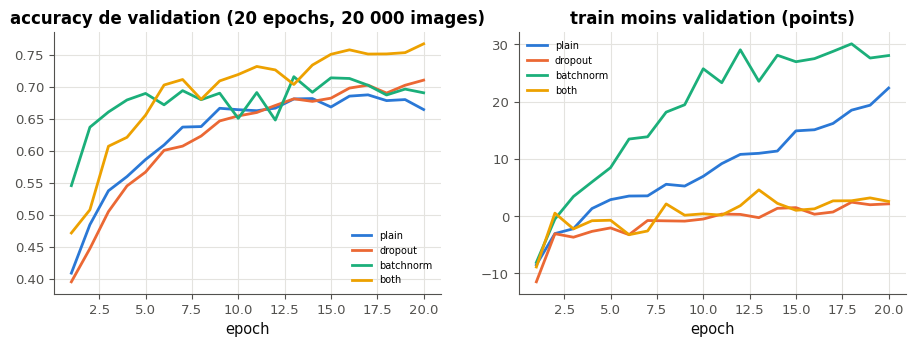

In [52]:
VARIANTS_21 = {"plain": {}, "dropout": {"p_drop": 0.25}, "batchnorm": {"batchnorm": True},
               "both": {"batchnorm": True, "p_drop": 0.25}}


def run_21(variant, epochs=EPOCHS_C, seed=2421):
    """make_deep_cnn_20(**VARIANTS_21[variant]), its weights drawn just after torch.manual_seed(seed), trained by
    train_classifier on XC_TR_T, YC_TR_T (validation XC_VAL_T, YC_VAL_T) with Adam(1e-3) and mini-batches of 128 from
    make_loader(..., seed=seed): returns the history."""
    torch.manual_seed(seed)
    model = make_deep_cnn_20(**VARIANTS_21[variant])
    return train_classifier(model, make_loader(XC_TR_T, YC_TR_T, 128, seed), XC_VAL_T, YC_VAL_T, epochs, seed=seed)


def gaps_21(history):
    """The list, one value per epoch, of the training accuracy minus the validation accuracy, in points."""
    return [100 * (t - v) for t, v in zip(history["train_acc"], history["val_acc"])]


with checked("24.21"):
    gaps_check_21 = gaps_21({"train_acc": [0.5, 0.9], "val_acc": [0.45, 0.7]})
    same("24.21", "gaps_21 sur un historique d'essai", gaps_check_21, [5.0, 20.0], rtol=1e-9, atol=1e-9)
    histories_21 = {name: run_21(name) for name in VARIANTS_21}
    print(f"{'variante':10s} {'train_acc':>9s} {'val_acc':>8s} {'écart (points)':>14s} {'s/epoch':>8s}  (dernière epoch, {len(XC_TR)} images)")
    for name_21, h_21 in histories_21.items():
        print(f"{name_21:10s} {h_21['train_acc'][-1]:9.3f} {h_21['val_acc'][-1]:8.3f} {gaps_21(h_21)[-1]:14.1f} "
              f"{np.median(h_21['seconds']):8.1f}")
    fig_21, axes_21 = plt.subplots(1, 2, figsize=(11, 3.4))
    for name_21, h_21 in HISTORY_21.items():
        axes_21[0].plot(range(1, 21), h_21["val_acc"], label=name_21)
        axes_21[1].plot(range(1, 21), gaps_21(h_21), label=name_21)
    axes_21[0].set_title("accuracy de validation (20 epochs, 20 000 images)")
    axes_21[1].set_title("train moins validation (points)")
    for ax_21 in axes_21:
        ax_21.set_xlabel("epoch")
        ax_21.legend(fontsize=7)
    plt.show()

Sur `HISTORY_21` (A = `"plain"`, B = `"dropout"`, C = `"batchnorm"`, D = `"both"`) :
a) `best_21` : quelle variante a la meilleure accuracy de validation à la 20ᵉ epoch ?
b) `best_gap_21` : laquelle a le plus petit écart (train moins validation) à la 20ᵉ epoch ?
c) `plain_gap_21` : l'écart de `"plain"` à la 20ᵉ epoch, en points (1 décimale) ;
d) `fastest_21` : laquelle atteint la première 65 % d'accuracy de validation ?

In [53]:
letters_21 = dict(zip("ABCD", ["plain", "dropout", "batchnorm", "both"]))
best_21 = max(letters_21, key=lambda k: HISTORY_21[letters_21[k]]["val_acc"][-1])
best_gap_21 = min(letters_21, key=lambda k: gaps_21(HISTORY_21[letters_21[k]])[-1])
plain_gap_21 = round(gaps_21(HISTORY_21["plain"])[-1], 1)
first_65_21 = {k: next((i for i, a in enumerate(HISTORY_21[v]["val_acc"]) if a >= 0.65), 99) for k, v in letters_21.items()}
fastest_21 = min(first_65_21, key=first_65_21.get)
print(best_21, best_gap_21, plain_gap_21, fastest_21)

D B 22.4 C


In [54]:
wb.record("24.21a", best_21, mistakes={"compare les accuracies de validation de la 20e epoch : « plain » n'a pas la plus grande": "A", "compare les accuracies de validation de la 20e epoch : « dropout » n'a pas la plus grande": "B", "compare les accuracies de validation de la 20e epoch : « batchnorm » n'a pas la plus grande": "C"})
wb.record("24.21b", best_gap_21, mistakes={"compare l'écart train moins validation de la 20e epoch : celui de « plain » n'est pas le plus petit": "A", "compare l'écart train moins validation de la 20e epoch : celui de « batchnorm » n'est pas le plus petit": "C", "compare l'écart train moins validation de la 20e epoch : celui de « both » n'est pas le plus petit": "D"})
wb.record("24.21c", plain_gap_21, decimals=1, mistakes={"en points : multiplie la différence d'accuracy par 100": 0.22399999999999998, "entraînement MOINS validation, pas l'inverse": -22.4, "la 20e epoch, la dernière de l'historique (indice -1 ou 19), pas l'avant-dernière": 19.4})
wb.record("24.21d", fastest_21, mistakes={"cherche la première epoch où chaque variante atteint 0,65 : « plain » n'est pas la première": "A", "cherche la première epoch où chaque variante atteint 0,65 : « dropout » n'est pas la première": "B", "cherche la première epoch où chaque variante atteint 0,65 : « both » n'est pas la première": "D"})

WB_ANSWER {"hash": "6fcc27aad47d363cddd0880f8b1682c84b672265ab0ef3042ebb44b30409d1d2", "id": "24.21a", "kind": "str", "mistakes": {"0870a848e0053fa26f2ab178885fa2fcdbde9f2b70d6f5747e48c1efc2af55a5": "compare les accuracies de validation de la 20e epoch : « plain » n'a pas la plus grande", "a58b8e87e3c457763e6a7076fdd058ad1601fbcebe06abc7a81ebfbd7f2f4b3f": "compare les accuracies de validation de la 20e epoch : « dropout » n'a pas la plus grande", "c053f3462bd0b999d02930b708305ccbec7038e61ded94e4380fd227083a68f7": "compare les accuracies de validation de la 20e epoch : « batchnorm » n'a pas la plus grande"}}
📝 Ex 24.21a : réponse enregistrée (str).
WB_ANSWER {"hash": "81890c8322dd0cd76b60f27e8c2e7095a6b7d4a46ecb059a6187e00b355ff001", "id": "24.21b", "kind": "str", "mistakes": {"125b55f814d6cbaaaf3b9b858db71c01dab473d98257644f311d0bef5b5f92f8": "compare l'écart train moins validation de la 20e epoch : celui de « batchnorm » n'est pas le plus petit", "5b6088fd6b5bbe570329b88eea9f44f922cec

Dans tes notes : la batchnorm régularise-t-elle, ou accélère-t-elle surtout l'apprentissage ? Le dropout réduit-il l'écart, et à quel prix ? Les deux ensemble font-ils mieux que chacun seul ? Ce que montraient les deux premières epochs (ton court entraînement) permettait-il de deviner le classement final ?

💡 Sur 20 000 images, le modèle sans rien finit avec 22,4 points d'écart (88,8 % sur le train, 66,4 % en validation). La batchnorm accélère nettement l'apprentissage (65 % de validation dès la 3ᵉ epoch), mais elle surapprend encore plus : 28 points d'écart, 97 % sur le train ; elle sert l'optimisation, pas la régularisation. Le dropout ramène l'écart à 2,2 points et gagne 4,6 points de validation, au prix d'un apprentissage plus lent. Les deux ensemble combinent la vitesse de la batchnorm et la régularisation du dropout : la meilleure validation (76,7 %), avec 2,6 points d'écart. Les deux premières epochs (ton court entraînement) ne disaient rien de ce classement, ni de l'overfitting, qui n'apparaît qu'après : c'est pourquoi on garde des historiques longs.

### Ex 24.22 — Prédire l'accuracy d'un CNN sur des images retournées, décalées, tournées ou en gris 🔮 ★ ⏱️ 10 min
**Objectif :** prédire, puis mesurer, la sensibilité d'un CNN entraîné sans augmentation à des transformations de ses images de test.  
**Prérequis :** Ex 24.20 · 24.Q8 · 🗣️ 24.8 · fiche §24.4.6 · **Fil rouge :** CIFAR-10 · **Parcours :** R, C

La fiche donne la règle de plausibilité : une transformation n'a de sens pour l'augmentation que si elle produit une image que le modèle pourrait rencontrer. Avant d'augmenter, regarde ce que « sait » déjà un modèle entraîné **sans** augmentation. La cellule donnée définit `train_reference_22` (un CNN à pooling moyen global, sans rapport avec tes modèles, entraîné 4 epochs sur les 10 000 premières images du fichier, les mêmes dans les deux modes) et cinq transformations des images de test : miroir gauche-droite, retournement haut-bas, rotation de 90°, décalage de 4 pixels vers la droite et vers le bas (une bande noire apparaît), niveaux de gris.

**Avant d'exécuter**, écris tes prédictions : sur 2 000 images de test, le modèle « perd » si son accuracy baisse d'au moins le nombre de points indiqué par rapport aux images intactes.
a) Miroir gauche-droite : perd-il au moins 3 points ? (`True` ou `False`)
b) Retournement haut-bas : perd-il au moins 10 points ?
c) Décalage de 4 pixels : perd-il au moins 5 points ?
d) Niveaux de gris : perd-il **moins** que le retournement haut-bas ?
e) La rotation de 90° fait-elle perdre **plus** que le retournement haut-bas ?

L'expérience (une minute environ) ne se lance qu'une fois tes cinq prédictions écrites.

In [55]:
def conv_bn_relu(c_in, c_out, k, stride=1):
    """The fiche's block: Conv (no bias: the batchnorm beta replaces it), then BatchNorm2d, then ReLU."""
    return nn.Sequential(nn.Conv2d(c_in, c_out, k, stride=stride, padding=k // 2, bias=False), nn.BatchNorm2d(c_out),
                         nn.ReLU())


def train_reference_22(seed=2422, n=10_000, epochs=4):
    """A CNN with a global average pooling, trained WITHOUT augmentation on the first n training images of the file
    (the same in both modes): Adam(1e-3), mini-batches of 128. Returns the model, in eval mode."""
    torch.manual_seed(seed)
    model = nn.Sequential(conv_bn_relu(3, 32, 3), nn.MaxPool2d(2), conv_bn_relu(32, 64, 3), nn.MaxPool2d(2),
                          conv_bn_relu(64, 128, 3), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, 10))
    train_classifier(model, make_loader(to_input_c(_XC[:n]), torch.from_numpy(_YC[:n].astype(np.int64)), 128, seed),
                     XC_VAL_T[:1000], YC_VAL_T[:1000], epochs, seed=seed)
    return model.eval()


def shift_22(images, k=4):
    """Move the images k pixels to the right and k pixels down; the uncovered band is black."""
    out = np.zeros_like(images)
    out[:, k:, k:] = images[:, :-k, :-k]
    return out


def gray_22(images):
    """The same images in shades of grey (the luminance, copied in the three channels)."""
    lum = images.astype(np.float32) @ np.array([0.299, 0.587, 0.114], dtype=np.float32)
    return np.repeat(np.clip(lum.round(), 0, 255).astype(np.uint8)[..., None], 3, axis=-1)


TRANSFORMS_22 = {"aucune": lambda im: im,
                 "miroir gauche-droite": lambda im: im[:, :, ::-1],
                 "retournement haut-bas": lambda im: im[:, ::-1],
                 "rotation de 90°": lambda im: np.rot90(im, 1, axes=(1, 2)),
                 "décalage de 4 pixels": shift_22,
                 "niveaux de gris": gray_22}

In [56]:
mirror_22, flip_22, shift_loss_22, gray_loss_22, rot_vs_flip_22 = False, True, True, True, True

In [57]:
wb.record("24.22a", False, mistakes={"compare la ligne « miroir gauche-droite » à « aucune » : la baisse atteint-elle 3 points ?": True})
wb.record("24.22b", True, mistakes={"compare la ligne « retournement haut-bas » à « aucune » : la baisse atteint-elle 10 points ?": False})
wb.record("24.22c", True, mistakes={"compare la ligne « décalage de 4 pixels » à « aucune » : la baisse atteint-elle 5 points ?": False})
wb.record("24.22d", True, mistakes={"compare les deux baisses, niveaux de gris et retournement haut-bas : laquelle est la plus petite ?": False})
wb.record("24.22e", True, mistakes={"compare les deux baisses, rotation et retournement haut-bas : laquelle est la plus grande ?": False})

WB_ANSWER {"hash": "1b719b739dc38e9d044ee9bc09785dd96897dbaa21537f0bae8866bce0e1d8ab", "id": "24.22a", "kind": "bool", "mistakes": {"8f9a445c085645746488394a77742a1b4e46a5c009581901caf4fb150a15a8b0": "compare la ligne « miroir gauche-droite » à « aucune » : la baisse atteint-elle 3 points ?"}}
📝 Ex 24.22a : réponse enregistrée (bool).
WB_ANSWER {"hash": "a46914a7a4dee770eb3ec0295b95d483501f1828003e0da8afa61440b7773a4d", "id": "24.22b", "kind": "bool", "mistakes": {"a2d9bd6043ec3996f214a9dda93309fa97acb41abef927ed892196e1cdba3c0e": "compare la ligne « retournement haut-bas » à « aucune » : la baisse atteint-elle 10 points ?"}}
📝 Ex 24.22b : réponse enregistrée (bool).
WB_ANSWER {"hash": "0058a8b62c4e058d3862148f29837859fc1b33e58cbb1a129f951eadbb98e06e", "id": "24.22c", "kind": "bool", "mistakes": {"00c537b8aaf4cafe2d5e6c32c1080c4c01f3efdb2bae52e6c5f457340352bb1a": "compare la ligne « décalage de 4 pixels » à « aucune » : la baisse atteint-elle 5 points ?"}}
📝 Ex 24.22c : réponse enregis

aucune                 accuracy de test 0.503   (+0.0 points)
miroir gauche-droite   accuracy de test 0.500   (-0.3 points)
retournement haut-bas  accuracy de test 0.333   (-17.1 points)
rotation de 90°        accuracy de test 0.211   (-29.2 points)
décalage de 4 pixels   accuracy de test 0.271   (-23.2 points)
niveaux de gris        accuracy de test 0.433   (-7.0 points)


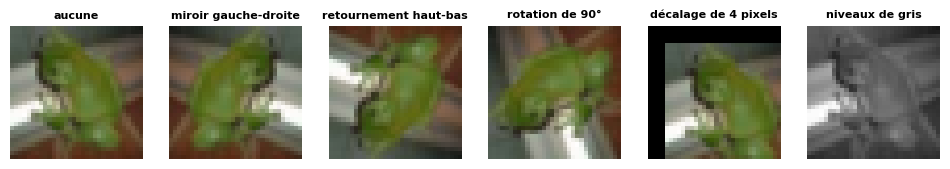

✅ Ex 24.22a : Bravo !
✅ Ex 24.22b : Exact !
✅ Ex 24.22c : Bien joué !
✅ Ex 24.22d : C'est ça !
✅ Ex 24.22e : Parfait !


In [58]:
if any(answer is ... or answer is None for answer in [mirror_22, flip_22, shift_loss_22, gray_loss_22, rot_vs_flip_22]):
    print("⏳ Ex 24.22 : écris d'abord tes cinq prédictions dans la cellule précédente.")
else:
    model_22 = train_reference_22()
    images_22, labels_22 = XC_TEST[:2000], torch.from_numpy(YC_TEST[:2000])
    acc_22 = {name: evaluate(model_22, to_input_c(np.ascontiguousarray(f(images_22))), labels_22)[1]
              for name, f in TRANSFORMS_22.items()}
    for name_22, a_22 in acc_22.items():
        print(f"{name_22:22s} accuracy de test {a_22:.3f}   ({100 * (a_22 - acc_22['aucune']):+.1f} points)")
    fig_22, axes_22 = plt.subplots(1, len(TRANSFORMS_22), figsize=(12, 2.4))
    for ax_22, (name_22, f_22) in zip(axes_22, TRANSFORMS_22.items()):
        ax_22.imshow(np.ascontiguousarray(f_22(XC_TEST[7:8]))[0])
        ax_22.set_title(name_22, fontsize=8)
        ax_22.axis("off")
    plt.show()
    wb.check("24.22a", mirror_22)
    wb.check("24.22b", flip_22)
    wb.check("24.22c", shift_loss_22)
    wb.check("24.22d", gray_loss_22)
    wb.check("24.22e", rot_vs_flip_22)

Dans tes notes : pour chaque transformation, la baisse mesurée te semble-t-elle logique ? Lesquelles de ces images transformées le train contenait-il déjà, ou presque ? Qu'est-ce qui, dans l'architecture (filtres partagés, poolings, bords complétés de zéros), rend un CNN sensible ou non à un décalage de quelques pixels ? Parmi ces transformations, lesquelles mettrais-tu dans l'augmentation de CIFAR-10, et lesquelles n'y ont aucun sens ?

💡 Le miroir gauche-droite ne coûte rien (moins d'un point sur cinq graines, entrée `calib` de `tools/chapters/history_ch24.json`) : les photos de CIFAR-10 montrent déjà les animaux et les véhicules tournés à gauche comme à droite, si bien que le modèle a vu les deux sans augmentation. Le retournement haut-bas fait perdre 14 à 17 points et la rotation de 90° 25 à 29 : le ciel en bas, des objets couchés, des images que le train ne contient pas. Le décalage de 4 pixels coûte beaucoup plus qu'on ne le croit (23 points ici, 13 à 24 selon la graine) : un CNN entraîné sans augmentation n'est pas invariant par translation (les poolings, les bords complétés de zéros), et la bande noire crée des bords que le réseau n'a jamais vus. C'est pourquoi le recadrage décalé est l'augmentation de base. Les niveaux de gris coûtent moins (4 à 10 points) : la couleur aide (le vert des grenouilles, le bleu du ciel et de la mer), mais la forme compte davantage. Le miroir gauche-droite et de petits décalages sont des augmentations naturelles pour CIFAR-10 ; les retournements haut-bas et les rotations de 90° n'y ont pas de sens.

### Ex 24.23 — Augmentation de données avec torchvision.transforms.v2 📦 ★★★ ⏱️ 45 min
**Objectif :** écrire une augmentation reproductible avec torchvision.transforms.v2 et un Dataset, et mesurer son effet sur un historique long.  
**Prérequis :** Ex 24.22 · Ex 24.20 · ch. 23 (Dataset, DataLoader) · fiche §24.4.2, §24.4.6 · **Fil rouge :** CIFAR-10 · **Parcours :** R, C

**Contrat**
- `make_transforms_23(augment=True)` rend `(train_tf, test_tf)`, deux `v2.Compose` : `test_tf` fait `ToImage`, `ToDtype(torch.float32, scale=True)` et `Normalize(MEAN, STD)` ; `train_tf` fait de même, avec `RandomCrop(32, padding=4)` puis `RandomHorizontalFlip()` juste après `ToImage` quand `augment` est vrai (rien d'aléatoire sinon) ;
- `CifarImages_23(images, labels, transform)` est un `Dataset` : l'élément `i` vaut `(transform(images[i]), int(labels[i]))`, la transformation étant appliquée **à chaque accès** ;
- `channel_stats_23(images)` rend `(means, stds)`, deux tuples de 3 `float` Python : la moyenne et l'écart-type (diviseur $n$) de chaque canal de `images / 255`, pour des images `uint8` $(N, 32, 32, 3)$ ;
- `make_train_loader_23(dataset, batch_size=128, seed=0)` rend un `DataLoader` mélangé dont l'ordre est tiré par son propre `torch.Generator`, de graine `seed`.

La vérification contrôle tes transformations (forme, type, standardisation, hasard, miroirs gauche-droite seulement), ton `Dataset`, tes statistiques, et ce que fixe chaque graine ; la cellule suivante entraîne `make_deep_cnn_20(batchnorm=True)` sans puis avec augmentation, `EPOCHS_C` epochs, et trace `HISTORY_23` : les mêmes entraînements, calculés à l'avance sur 20 000 images pendant 25 epochs.

In [59]:
def make_transforms_23(augment=True):
    """(train_tf, test_tf), two v2.Compose. test_tf: ToImage, ToDtype(float32, scale=True), Normalize(MEAN, STD).
    train_tf: the same, with RandomCrop(32, padding=4) then RandomHorizontalFlip() after ToImage when augment is True
    (and nothing random when it is False)."""
    finish = [v2.ToDtype(torch.float32, scale=True), v2.Normalize(MEAN, STD)]
    random_ops = [v2.RandomCrop(32, padding=4), v2.RandomHorizontalFlip()] if augment else []
    return v2.Compose([v2.ToImage(), *random_ops, *finish]), v2.Compose([v2.ToImage(), *finish])


class CifarImages_23(Dataset):
    """CifarImages_23(images, labels, transform): images uint8 (N, 32, 32, 3), labels (N,); item i is
    (transform(images[i]), int(labels[i])), the transform applied anew at EVERY access."""

    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        return self.transform(self.images[i]), int(self.labels[i])


def channel_stats_23(images):
    """(means, stds): two tuples of 3 Python floats, the mean and the standard deviation (divisor n) of each channel of
    images / 255, for uint8 images (N, 32, 32, 3)."""
    x = np.asarray(images, dtype=np.float64) / 255.0
    return tuple(float(m) for m in x.mean(axis=(0, 1, 2))), tuple(float(s) for s in x.std(axis=(0, 1, 2)))


def make_train_loader_23(dataset, batch_size=128, seed=0):
    """DataLoader(dataset, batch_size, shuffle=True) whose order is drawn by its own torch.Generator seeded by seed."""
    return DataLoader(dataset, batch_size=batch_size, shuffle=True, generator=torch.Generator().manual_seed(seed))


with checked("24.23"):
    train_tf_23, test_tf_23 = pair("24.23", "make_transforms_23()", make_transforms_23(), names=("train_tf", "test_tf"))
    image_23 = XC_TR[3]
    a_23, b_23 = test_tf_23(image_23), test_tf_23(image_23)
    verdict("24.23", isinstance(a_23, torch.Tensor) and a_23.dtype == torch.float32 and tuple(a_23.shape) == (3, 32, 32)
            and torch.equal(a_23, b_23), "test_tf : un tenseur float32 (3, 32, 32), toujours le même.",
            f"test_tf doit rendre un tenseur float32 (3, 32, 32), sans hasard ; reçu {type(a_23).__name__} "
            f"{tuple(getattr(a_23, 'shape', ()))}.")
    same("24.23", "test_tf(image) contre la standardisation par canal", a_23, to_input_c(image_23[None])[0], rtol=1e-5, atol=1e-5)
    draws_23 = torch.stack([train_tf_23(image_23) for _ in range(30)])
    distinct_23 = len({tuple(d.flatten()[::97].tolist()) for d in draws_23})
    verdict("24.23", distinct_23 >= 10, f"train_tf : {distinct_23} versions différentes de la même image en 30 tirages.",
            f"train_tf ne donne que {distinct_23} versions différentes en 30 tirages : l'augmentation est-elle là ?")

    def shifted_23(d, ref):
        """True when the centre of d is the centre of ref shifted by at most 4 pixels (a crop of the padded image)."""
        return any(torch.allclose(d[:, 4:28, 4:28], ref[:, 4 + dy:28 + dy, 4 + dx:28 + dx], atol=1e-5)
                   for dy in range(-4, 5) for dx in range(-4, 5))

    kinds_23 = ["miroir" if shifted_23(d, a_23.flip(-1)) else "droite" if shifted_23(d, a_23) else "autre" for d in draws_23]
    verdict("24.23", "miroir" in kinds_23 and "droite" in kinds_23 and "autre" not in kinds_23,
            f"chaque tirage est un recadrage décalé de l'image ou de son miroir gauche-droite ({kinds_23.count('miroir')} "
            f"miroirs sur 30).",
            f"attendu des recadrages décalés d'au plus 4 pixels, une fois sur deux en miroir gauche-droite ; reçu "
            f"{kinds_23.count('droite')} à l'endroit, {kinds_23.count('miroir')} en miroir et {kinds_23.count('autre')} autres.")
    plain_tf_23, _ = make_transforms_23(augment=False)
    verdict("24.23", torch.equal(plain_tf_23(image_23), a_23), "augment=False : l'entraînement voit les images telles quelles.",
            "make_transforms_23(augment=False) : la transformation d'entraînement doit égaler celle de test.")
    data_23 = CifarImages_23(XC_TR, YC_TR, train_tf_23)
    x0_23, y0_23 = data_23[0]
    fresh_23 = any(not torch.equal(data_23[3][0], data_23[3][0]) for _ in range(3))
    verdict("24.23", len(data_23) == len(XC_TR) and isinstance(y0_23, int) and y0_23 == int(YC_TR[0]) and fresh_23,
            "CifarImages_23 : la bonne longueur, des labels int, une transformation nouvelle à chaque accès.",
            "CifarImages_23 : attendu len = nombre d'images, item (transform(image), int(label)), la transformation "
            "appliquée à chaque accès (pas une seule fois dans __init__).")
    means_23, stds_23 = pair("24.23", "channel_stats_23(XC_TR)", channel_stats_23(XC_TR), names=("means", "stds"))
    x_23 = XC_TR.astype(np.float64) / 255.0
    same("24.23", "moyennes par canal", means_23, x_23.mean(axis=(0, 1, 2)), rtol=1e-6)
    same("24.23", "écarts-types par canal", stds_23, x_23.std(axis=(0, 1, 2)), rtol=1e-6)
    torch.manual_seed(1)
    first_23 = next(iter(make_train_loader_23(data_23, batch_size=8, seed=5)))
    torch.manual_seed(1)
    again_23 = next(iter(make_train_loader_23(data_23, batch_size=8, seed=5)))
    torch.manual_seed(2)
    other_23 = next(iter(make_train_loader_23(data_23, batch_size=8, seed=5)))
    verdict("24.23", torch.equal(first_23[0], again_23[0]) and torch.equal(first_23[1], other_23[1])
            and not torch.equal(first_23[0], other_23[0]),
            "même graine du loader : mêmes images ; autre graine globale : mêmes images, autres transformations.",
            "make_train_loader_23 doit mélanger avec son propre générateur (generator=torch.Generator().manual_seed(seed)).")

✅ Ex 24.23 : test_tf : un tenseur float32 (3, 32, 32), toujours le même.
✅ Ex 24.23 : test_tf(image) contre la standardisation par canal : un tableau (3, 32, 32), comme attendu.


✅ Ex 24.23 : train_tf : 28 versions différentes de la même image en 30 tirages.
✅ Ex 24.23 : chaque tirage est un recadrage décalé de l'image ou de son miroir gauche-droite (13 miroirs sur 30).
✅ Ex 24.23 : augment=False : l'entraînement voit les images telles quelles.
✅ Ex 24.23 : CifarImages_23 : la bonne longueur, des labels int, une transformation nouvelle à chaque accès.


✅ Ex 24.23 : moyennes par canal : [0.49068444, 0.48129195, 0.44468248], comme attendu.


✅ Ex 24.23 : écarts-types par canal : [0.24682773, 0.2429754, 0.2616961], comme attendu.
✅ Ex 24.23 : même graine du loader : mêmes images ; autre graine globale : mêmes images, autres transformations.


In [60]:
HISTORY_23 = {   # make_deep_cnn_20(batchnorm=True), 25 epochs on 20 000 images (tools/chapters/history_ch24.py)
    "without": {"train_acc": [0.4637, 0.6144, 0.68665, 0.73595, 0.7672, 0.8038, 0.8274, 0.8553, 0.88015, 0.9034, 0.9194, 0.9351, 0.9559, 0.9703, 0.9809, 0.9832, 0.9876, 0.9816, 0.9733, 0.9672, 0.97715, 0.97935, 0.991, 0.99835, 0.99995], "val_acc": [0.5178, 0.5976, 0.637, 0.6564, 0.6718, 0.7062, 0.7036, 0.6836, 0.7118, 0.667, 0.685, 0.712, 0.7018, 0.6958, 0.7244, 0.7232, 0.7168, 0.7074, 0.6826, 0.6894, 0.7102, 0.7102, 0.7242, 0.7294, 0.7374], "val_loss": [1.36739, 1.11294, 1.01307, 1.00111, 0.98113, 0.84106, 0.87288, 0.96453, 0.87994, 1.14517, 1.097, 0.99571, 1.05317, 1.1497, 1.02702, 1.04462, 1.09232, 1.17034, 1.35904, 1.4177, 1.24548, 1.29503, 1.15394, 1.14461, 1.13521]},
    "with": {"train_acc": [0.3984, 0.5151, 0.5903, 0.64355, 0.6669, 0.6898, 0.7092, 0.72355, 0.7364, 0.7464, 0.7501, 0.7641, 0.76695, 0.7698, 0.7824, 0.78595, 0.7935, 0.7948, 0.79505, 0.8047, 0.80245, 0.81075, 0.8146, 0.8125, 0.81965], "val_acc": [0.4712, 0.5816, 0.6102, 0.6428, 0.6856, 0.6804, 0.7022, 0.672, 0.7392, 0.7342, 0.7214, 0.693, 0.7436, 0.7256, 0.7628, 0.7614, 0.7498, 0.753, 0.757, 0.7738, 0.7856, 0.7444, 0.7756, 0.7846, 0.7632], "val_loss": [1.4991, 1.14374, 1.06942, 1.00575, 0.88525, 0.92491, 0.86686, 0.96401, 0.75351, 0.78713, 0.81663, 0.93934, 0.7347, 0.82765, 0.69275, 0.67607, 0.72675, 0.73842, 0.71919, 0.66383, 0.63635, 0.77943, 0.69745, 0.65242, 0.73041]},
}

sans augmentation  train 0.473 · validation 0.430 · 5.3 s par epoch


avec augmentation  train 0.384 · validation 0.405 · 6.6 s par epoch


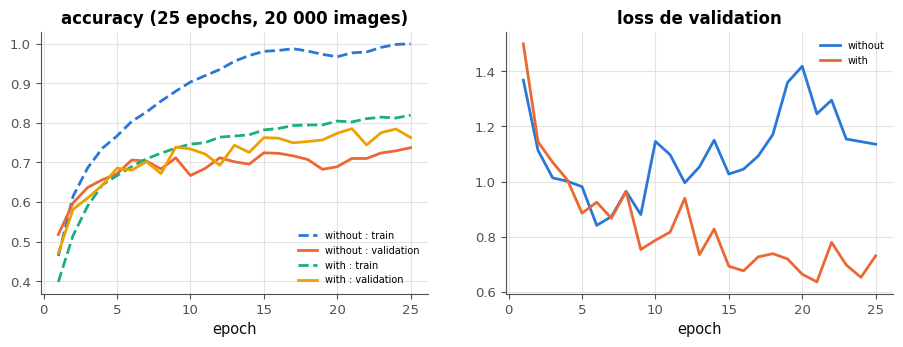

In [61]:
with checked("24.23"):
    train_tf_23, test_tf_23 = make_transforms_23(augment=True)
    histories_23 = {}
    for name_23, loader_23 in [("sans augmentation", make_loader(XC_TR_T, YC_TR_T, 128, 2423)),
                               ("avec augmentation", make_train_loader_23(CifarImages_23(XC_TR, YC_TR, train_tf_23), 128, 2423))]:
        torch.manual_seed(2423)
        model_23 = make_deep_cnn_20(batchnorm=True)
        histories_23[name_23] = train_classifier(model_23, loader_23, XC_VAL_T, YC_VAL_T, EPOCHS_C, seed=2423)
        print(f"{name_23:18s} train {histories_23[name_23]['train_acc'][-1]:.3f} · validation "
              f"{histories_23[name_23]['val_acc'][-1]:.3f} · {np.median(histories_23[name_23]['seconds']):.1f} s par epoch")
fig_23, axes_23 = plt.subplots(1, 2, figsize=(11, 3.4))
for name_23, h_23 in HISTORY_23.items():
    axes_23[0].plot(range(1, 26), h_23["train_acc"], "--", label=f"{name_23} : train")
    axes_23[0].plot(range(1, 26), h_23["val_acc"], label=f"{name_23} : validation")
    axes_23[1].plot(range(1, 26), h_23["val_loss"], label=name_23)
axes_23[0].set_title("accuracy (25 epochs, 20 000 images)")
axes_23[1].set_title("loss de validation")
for ax_23 in axes_23:
    ax_23.set_xlabel("epoch")
    ax_23.legend(fontsize=7)
plt.show()

Sur `HISTORY_23` :
a) `gain_23` : la meilleure accuracy de validation **avec** augmentation moins la meilleure **sans**, en points (1 décimale) ;
b) `cross_23` : la première epoch (comptée à partir de 1) à partir de laquelle l'accuracy de validation avec augmentation reste au-dessus de celle sans, jusqu'à la 25ᵉ ;
c) `train_gap_23` : à la 25ᵉ epoch, l'accuracy d'entraînement **sans** augmentation moins celle **avec**, en points (1 décimale).

In [62]:
with_23, without_23 = HISTORY_23["with"], HISTORY_23["without"]
gain_23 = round(100 * (max(with_23["val_acc"]) - max(without_23["val_acc"])), 1)
above_23 = [w > wo for w, wo in zip(with_23["val_acc"], without_23["val_acc"])]
cross_23 = next(i + 1 for i in range(len(above_23)) if all(above_23[i:]))
train_gap_23 = round(100 * (without_23["train_acc"][-1] - with_23["train_acc"][-1]), 1)
print(gain_23, cross_23, train_gap_23)

4.8 13 18.0


In [63]:
wb.record("24.23a", gain_23, decimals=1, mistakes={"la MEILLEURE accuracy de chaque courbe, pas celle de la 25e epoch": 2.6, "avec MOINS sans, pas l'inverse": -4.8, "en points : multiplie par 100": 0.048})
wb.record("24.23b", cross_23, mistakes={"c'est la première fois que la courbe avec augmentation passe au-dessus ; elle repasse dessous ensuite : cherche l'epoch à partir de laquelle elle reste au-dessus jusqu'à la 25e": 5, "les epochs se comptent à partir de 1 : l'indice 0 est l'epoch 1": 12})
wb.record("24.23c", train_gap_23, decimals=1, mistakes={"sans MOINS avec, pas l'inverse": -18.0, "l'accuracy d'ENTRAÎNEMENT, pas celle de validation": -2.6})

WB_ANSWER {"decimals": 1, "hash": "fe3c83ff24cd9956206d8fa33b993715ebe76a8fdbc4bedad170170a348209dc", "hash_coarse": "0fb3dfc0295ad0c76d740e400592b15380c86dcf9b4ec4249e32d7b9fd2d4ba4", "id": "24.23a", "kind": "float", "magnitude": 0, "mistakes": {"25ff0fcec3b38c3508d1777ac7d4033fa55978a4c15f8b653e5a9881b0bc8878": "en points : multiplie par 100", "2ef4fd74a0ba28c7cc650f3a1a4d410821a5307580f0331c6feec3f2ead6ff1c": "avec MOINS sans, pas l'inverse", "5d74b7852c6bc3594ec9d009b7e2071c67dff81a7f7110580f97a1228abcb986": "la MEILLEURE accuracy de chaque courbe, pas celle de la 25e epoch"}, "sign": 1}
📝 Ex 24.23a : réponse enregistrée (float, 1 décimale(s)).
WB_ANSWER {"hash": "1402d3c635ebc1c68a6a020287360301d23cdd20ecf5f232ed173033f3004bc5", "id": "24.23b", "kind": "int", "magnitude": 1, "mistakes": {"0e06026850cb2ff1a442c6c1759fc561de0cc92ac25cfde8feec990f625d3d08": "les epochs se comptent à partir de 1 : l'indice 0 est l'epoch 1", "1ded74619f74fba69487e58e8ee41f6ce16483e1b2235758c4db41cd115f

Dans tes notes : pourquoi l'augmentation ne sert-elle à rien, ou presque, dans ton court entraînement de `EPOCHS_C` epochs ? Pourquoi l'accuracy d'entraînement avec augmentation reste-t-elle loin de 100 % ? Dans la vérification, qu'est-ce que fixe la graine du loader, et qu'est-ce que fixe `torch.manual_seed` ? Que faudrait-il de plus avec `num_workers > 0` ?

💡 Au début, le modèle n'a pas encore appris le train par cœur : l'augmentation, qui rend chaque epoch un peu différente, n'a rien à empêcher, et elle ralentit même l'apprentissage (40,5 % contre 43,0 % après deux epochs). Sur l'historique long, sans augmentation, l'accuracy d'entraînement atteint 100 % et la loss de validation remonte après la 6ᵉ epoch ; avec augmentation, le train n'est jamais deux fois le même : l'accuracy d'entraînement reste à 82 %, et la validation finit plusieurs points au-dessus (meilleure valeur 78,6 % contre 73,7 %), durablement à partir de la 13ᵉ epoch. La graine du loader fixe l'ordre des images ; les tirages des transformations, faits dans le processus principal, viennent du générateur global de torch (`torch.manual_seed`). Avec des workers, chaque worker reçoit une graine tirée du générateur du loader (graine de base + numéro du worker) : le générateur du loader suffit alors à tout reproduire, à nombre de workers égal.

### Ex 24.24 — Des images synthétiques générées à la volée 📦 ★★ ⏱️ 30 min
**Objectif :** dessiner des images synthétiques variées, et les servir en flux infini, reproductible et partagé entre workers.  
**Prérequis :** Ex 24.20 · ch. 23 (Dataset) · 0A (générateurs) · fiche §24.4.7 · **Fil rouge :** synth · **Parcours :** C

Le livre dessine cinq formes (un Z, un plus, trois barres, un U carré, un cercle) dans des images $64 \times 64$, en bougeant un peu leurs points à chaque dessin. Tu fais de même en $32 \times 32$, puis tu écris un flux qui en fabrique sans fin. La fiche montre un `ShapeStream` ; le tien partage **exactement** le travail entre les workers. La cellule donnée définit `stroke_24`, qui trace un segment épais dans une image.

**Contrat**
- `draw_shape_24(rng, label=None, size=32)` rend `(image, label)` : une image `float32` $(size, size)$, 0 pour le fond et 1 sur les traits, et un label `int` ; si `label` vaut `None`, il est tiré uniformément entre 0 et 4 avec `rng`. En coordonnées unitaires (ligne, colonne), entre 0,2 et 0,8 : 0 « Z » (barre du haut, diagonale, barre du bas), 1 « plus », 2 « trois barres » (verticales, aux colonnes 0,25, 0,5 et 0,75), 3 « U carré » (côté gauche, bas, côté droit), 4 « cercle » (un polygone fermé de 24 côtés, centre $(0{,}5 ; 0{,}5)$, rayon 0,3). Chaque point de la forme bouge d'un bruit normal d'écart-type 0,03 ; la forme entière est agrandie d'un facteur tiré dans $[0{,}8 ; 1{,}1]$ autour de $(0{,}5 ; 0{,}5)$ et décalée d'au plus $\pm 0{,}1$ sur chaque axe ; puis les points sont multipliés par `size - 1` et reliés par `stroke_24` avec une épaisseur `width = size / 32`. Tout le hasard vient de `rng` ;
- `worker_share_24(n, worker_id, num_workers)` rend le nombre d'exemples que produit le worker `worker_id` pour que les workers en produisent `n` en tout : chacun `n // num_workers`, plus un pour les `n % num_workers` premiers ;
- `ShapeStream_24(n_per_epoch, size=32)` est un `IterableDataset` : une epoch produit des couples (tenseur `float32` $(1, size, size)$, label `int`) dessinés par `draw_shape_24` avec `np.random.default_rng(graine)`, la graine étant tirée de torch (`torch.randint`) au début de `__iter__` ; seul, il produit `n_per_epoch` couples ; dans un worker (`get_worker_info()`), sa part `worker_share_24`.

La vérification contrôle tes dessins (formes, labels, bruit, et que les cinq formes se distinguent), le partage entre workers, la reproductibilité, et, sous Linux, un vrai `DataLoader` à deux workers. La cellule suivante entraîne un tout petit CNN sur ton flux et l'évalue sur 1 000 dessins neufs.

Dans tes notes : pourquoi ce réseau ne peut-il pas surapprendre son train ? Avec la version de la fiche (`n_per_epoch // num_workers`), combien d'exemples ferait une epoch de 103 exemples avec 4 workers ? Qu'arriverait-il si la graine était fixée une fois pour toutes dans `__init__` ?

In [64]:
SHAPE_NAMES_24 = ["Z", "plus", "trois barres", "U carré", "cercle"]


def stroke_24(image, p, q, width=1.0):
    """Draw in place, in the 2D float array `image`, the segment from p to q ((row, column) in pixels, floats): the
    pixels at a distance <= width from the segment are set to 1."""
    rows, cols = np.mgrid[0:image.shape[0], 0:image.shape[1]]
    p, q = np.asarray(p, dtype=float), np.asarray(q, dtype=float)
    d = q - p
    t = np.clip(((rows - p[0]) * d[0] + (cols - p[1]) * d[1]) / max(float(d @ d), 1e-12), 0.0, 1.0)
    image[np.hypot(rows - (p[0] + t * d[0]), cols - (p[1] + t * d[1])) <= width] = 1.0

In [65]:
_LINES_24 = {0: [[(0.2, 0.2), (0.2, 0.8), (0.8, 0.2), (0.8, 0.8)]],
             1: [[(0.5, 0.2), (0.5, 0.8)], [(0.2, 0.5), (0.8, 0.5)]],
             2: [[(0.2, c), (0.8, c)] for c in (0.25, 0.5, 0.75)],
             3: [[(0.2, 0.2), (0.8, 0.2), (0.8, 0.8), (0.2, 0.8)]],
             4: [[(0.5 + 0.3 * np.sin(t), 0.5 + 0.3 * np.cos(t)) for t in np.linspace(0, 2 * np.pi, 25)]]}


def draw_shape_24(rng, label=None, size=32):
    """One random drawing: (image float32 (size, size), 0 for the background and 1 on the strokes, label int).
    label None: drawn uniformly among 0 to 4 with rng. In unit coordinates (row, column), between 0.2 and 0.8:
    0 "Z" (top bar, diagonal, bottom bar), 1 "plus", 2 "three bars" (vertical, at the columns 0.25, 0.5 and 0.75), 3 "square U" (left side,
    bottom, right side), 4 "circle" (a closed polygon of 24 sides, centre (0.5, 0.5), radius 0.3). Each point of the
    shape moves by a normal noise of standard deviation 0.03; the whole shape is scaled by a factor drawn in
    [0.8, 1.1] around (0.5, 0.5) and shifted by up to ±0.1 on each axis; then the points are multiplied by size - 1
    and joined by stroke_24 with width = size / 32. Everything random comes from rng."""
    label = int(rng.integers(5)) if label is None else int(label)
    scale, shift = rng.uniform(0.8, 1.1), rng.uniform(-0.1, 0.1, size=2)
    image = np.zeros((size, size), dtype=np.float32)
    for line in _LINES_24[label]:
        points = np.asarray(line, dtype=float) + rng.normal(0.0, 0.03, size=(len(line), 2))
        if label == 4:
            points[-1] = points[0]                         # keep the circle closed
        points = ((points - 0.5) * scale + 0.5 + shift) * (size - 1)
        for p, q in zip(points[:-1], points[1:]):
            stroke_24(image, p, q, width=size / 32)
    return image, label


def worker_share_24(n, worker_id, num_workers):
    """How many examples worker `worker_id` (0 to num_workers - 1) yields so that the workers yield n in all: each one
    n // num_workers, plus one for the first n % num_workers workers."""
    return n // num_workers + (1 if worker_id < n % num_workers else 0)


class ShapeStream_24(IterableDataset):
    """ShapeStream_24(n_per_epoch, size=32): an epoch yields (image tensor float32 (1, size, size), label int) pairs
    drawn by draw_shape_24 with np.random.default_rng(seed), seed drawn from torch (torch.randint) at the start of
    __iter__: torch.manual_seed makes the stream reproducible, and every epoch and every worker draws different
    images. Alone, it yields n_per_epoch pairs; in a worker (get_worker_info()), its worker_share_24."""

    def __init__(self, n_per_epoch, size=32):
        self.n_per_epoch, self.size = n_per_epoch, size

    def __iter__(self):
        rng = np.random.default_rng(int(torch.randint(2**31, ())))   # a new seed at each epoch, in each worker
        info = get_worker_info()                                      # None in the main process
        n = self.n_per_epoch if info is None else worker_share_24(self.n_per_epoch, info.id, info.num_workers)
        for _ in range(n):
            image, label = draw_shape_24(rng, size=self.size)
            yield torch.from_numpy(image).unsqueeze(0), label


import multiprocessing

with checked("24.24"):
    rng_24 = np.random.default_rng(0)
    image_24, label_24 = pair("24.24", "draw_shape_24(rng)", draw_shape_24(rng_24), names=("image", "label"))
    verdict("24.24", isinstance(image_24, np.ndarray) and image_24.shape == (32, 32) and image_24.dtype == np.float32
            and set(np.unique(image_24)) <= {0.0, 1.0} and isinstance(label_24, int) and 0 <= label_24 <= 4,
            "une image float32 (32, 32) de 0 et de 1, et un label int entre 0 et 4.",
            f"attendu une image float32 (32, 32) de 0 et de 1 et un label int, reçu {getattr(image_24, 'shape', '')} "
            f"{getattr(image_24, 'dtype', '')} et {label_24!r}.")
    forced_24 = [draw_shape_24(rng_24, label=3)[1] for _ in range(5)]
    twins_24 = [draw_shape_24(rng_24, label=k)[0] for k in (4, 4)]
    verdict("24.24", forced_24 == [3] * 5 and not np.array_equal(*twins_24),
            "un label imposé est respecté, et deux cercles ne sont jamais identiques.",
            "label=3 doit donner le label 3, et deux dessins de la même forme doivent différer (le bruit des points).")
    counts_24 = np.bincount([draw_shape_24(rng_24)[1] for _ in range(500)], minlength=5)
    verdict("24.24", counts_24.min() >= 60 and counts_24.max() <= 140,
            f"label=None : les cinq formes sont tirées à peu près autant ({counts_24.tolist()} sur 500).",
            f"label=None : attendu environ 100 tirages de chaque forme sur 500, reçu {counts_24.tolist()}.")
    train_24 = [draw_shape_24(rng_24, label=k)[0].ravel() for k in range(5) for _ in range(100)]
    means_24 = np.stack([np.mean(train_24[100 * k:100 * (k + 1)], axis=0) for k in range(5)])
    test_24 = [draw_shape_24(rng_24) for _ in range(500)]
    nearest_24 = np.mean([np.argmin(((means_24 - im.ravel()) ** 2).sum(axis=1)) == lab for im, lab in test_24])
    verdict("24.24", nearest_24 >= 0.7, f"les cinq formes se distinguent : la forme moyenne la plus proche donne le bon "
            f"label {fr(100 * nearest_24, 0)} fois sur 100.",
            f"les formes se ressemblent trop : la forme moyenne la plus proche ne donne le bon label que "
            f"{fr(100 * nearest_24, 0)} fois sur 100 ; relis la description de chaque forme.")
    shares_24 = {(n, w): [worker_share_24(n, k, w) for k in range(w)] for n, w in [(10, 3), (103, 4), (5, 8), (12, 4)]}
    verdict("24.24", all(sum(s) == n and max(s) - min(s) <= 1 and s == sorted(s, reverse=True)
                         for (n, w), s in shares_24.items()),
            f"worker_share_24 : tout est distribué, à un près ({shares_24[(103, 4)]} pour 103 exemples et 4 workers).",
            f"worker_share_24 : la somme doit valoir n, les parts différer d'au plus 1, les premiers workers prenant les "
            f"restes ; reçu {shares_24}.")
    stream_24 = ShapeStream_24(50)
    torch.manual_seed(7)
    epoch1_24 = list(stream_24)
    torch.manual_seed(7)
    again_24 = list(stream_24)
    epoch2_24 = list(stream_24)
    verdict("24.24", len(epoch1_24) == 50 and tuple(epoch1_24[0][0].shape) == (1, 32, 32)
            and all(torch.equal(a[0], b[0]) for a, b in zip(epoch1_24, again_24))
            and not all(torch.equal(a[0], b[0]) for a, b in zip(again_24, epoch2_24)),
            "le flux : 50 exemples (1, 32, 32) par epoch, reproductible avec torch.manual_seed, différent à chaque epoch.",
            "attendu 50 exemples (1, 32, 32), les mêmes après le même torch.manual_seed, et d'autres à l'epoch suivante "
            "(la graine du générateur NumPy doit être tirée de torch au début de __iter__).")
    if platform.system() == "Linux" and "fork" in multiprocessing.get_all_start_methods():
        loader_24 = DataLoader(ShapeStream_24(103), batch_size=10, num_workers=2, multiprocessing_context="fork")
        images_24 = torch.cat([xb for xb, _ in loader_24]).flatten(1)
        verdict("24.24", len(images_24) == 103 and len(torch.unique(images_24, dim=0)) == 103,
                "avec 2 workers : 103 exemples en tout, tous différents.",
                f"avec 2 workers : attendu 103 exemples tous différents, reçu {len(images_24)} exemples dont "
                f"{len(torch.unique(images_24, dim=0))} différents.")
    else:
        print("ℹ️ Ex 24.24 : le test à deux workers ne tourne que sous Linux (Colab) : une classe définie dans un "
              "notebook ne passe pas aux workers lancés par « spawn » (Windows, macOS).")

✅ Ex 24.24 : une image float32 (32, 32) de 0 et de 1, et un label int entre 0 et 4.
✅ Ex 24.24 : un label imposé est respecté, et deux cercles ne sont jamais identiques.


✅ Ex 24.24 : label=None : les cinq formes sont tirées à peu près autant ([96, 100, 93, 110, 101] sur 500).


✅ Ex 24.24 : les cinq formes se distinguent : la forme moyenne la plus proche donne le bon label 93 fois sur 100.
✅ Ex 24.24 : worker_share_24 : tout est distribué, à un près ([26, 26, 26, 25] pour 103 exemples et 4 workers).
✅ Ex 24.24 : le flux : 50 exemples (1, 32, 32) par epoch, reproductible avec torch.manual_seed, différent à chaque epoch.


✅ Ex 24.24 : avec 2 workers : 103 exemples en tout, tous différents.


6373 paramètres · loss d'entraînement [1.026, 0.092, 0.02] · accuracy sur 1 000 dessins neufs [0.974, 0.998, 1.0]
✅ Ex 24.24 : le petit réseau reconnaît 100,0 % des dessins neufs.


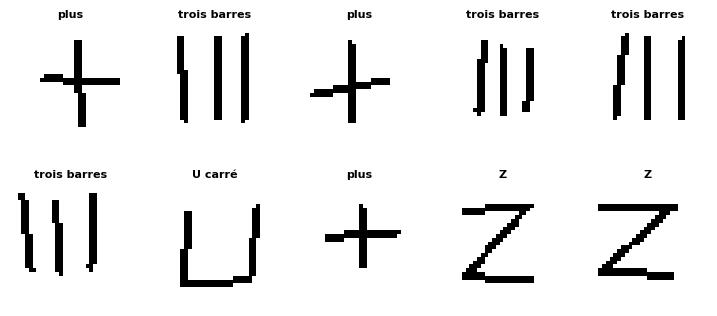

In [66]:
with checked("24.24"):
    N_STREAM_24, EPOCHS_24 = (3_000, 3) if FAST_MODE else (20_000, 5)
    rng_test_24 = np.random.default_rng(2424)
    test_pairs_24 = [draw_shape_24(rng_test_24) for _ in range(1000)]          # a fixed test set of 1 000 drawings
    x_test_24 = torch.from_numpy(np.stack([im for im, _ in test_pairs_24])).unsqueeze(1)
    y_test_24 = torch.tensor([lab for _, lab in test_pairs_24])
    torch.manual_seed(2424)
    net_24 = nn.Sequential(nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(8, 16, 3, padding=1),
                           nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(), nn.Linear(16 * 8 * 8, 5))
    history_24 = train_classifier(net_24, DataLoader(ShapeStream_24(N_STREAM_24), batch_size=64), x_test_24, y_test_24,
                                  EPOCHS_24, seed=2424)
    print(f"{n_params(net_24)} paramètres · loss d'entraînement {np.round(history_24['train_loss'], 3).tolist()} · "
          f"accuracy sur 1 000 dessins neufs {np.round(history_24['val_acc'], 3).tolist()}")
    verdict("24.24", history_24["val_acc"][-1] >= 0.9,
            f"le petit réseau reconnaît {fr(100 * history_24['val_acc'][-1], 1)} % des dessins neufs.",
            f"seulement {fr(100 * history_24['val_acc'][-1], 1)} % de dessins neufs reconnus : tes formes sont-elles "
            "conformes à la description ?")
    fig_24, axes_24 = plt.subplots(2, 5, figsize=(9, 3.8))
    for k_24, ax_24 in enumerate(axes_24.ravel()):
        im_24, lab_24 = test_pairs_24[k_24]
        ax_24.imshow(im_24, cmap="gray_r")
        ax_24.set_title(SHAPE_NAMES_24[lab_24], fontsize=8)
        ax_24.axis("off")
    plt.show()

💡 Chaque exemple est neuf : le réseau ne voit jamais deux fois le même dessin, il ne peut pas apprendre le train par cœur, et ses accuracies d'entraînement et de test restent proches (100 % des dessins neufs reconnus après trois epochs de 3 000 dessins). Avec `103 // 4 = 25` exemples par worker, une epoch n'en ferait que 100 : trois exemples perdus à chaque epoch, sans message. Avec une graine fixée dans `__init__`, chaque epoch redonnerait exactement les mêmes images (un dataset fini déguisé en flux) et, avec plusieurs workers, chaque worker produirait les mêmes images que les autres : des doublons dans chaque batch.

## Partie D · Des séries et un LSTM

Tu prépares des sommes de sinus pour un LSTM minuscule et tu compares sa RMSE à la persistance (24.25) ; tu démêles trois leviers sur une série plus difficile : la fenêtre, la profondeur et la quantité de données (24.26) ; puis tu lis les sorties de `nn.LSTM` et tu portes son état d'un morceau à l'autre, sur les taches solaires (24.27).

La cellule suivante reprend tes outils des ch. 12 et 22 (`SeriesScaler`, ton `MinMaxScaler`, et `make_windows`), les sinus du livre (`sum_of_sines`, la série calme `CALM`, la série agitée `BUSY`, $\Delta\theta = 0{,}057$, et `upsloping`, la série « toujours montante »), les deux modèles de la fiche (`TinyForecaster`, `Stacked`), et trace les trois séries.

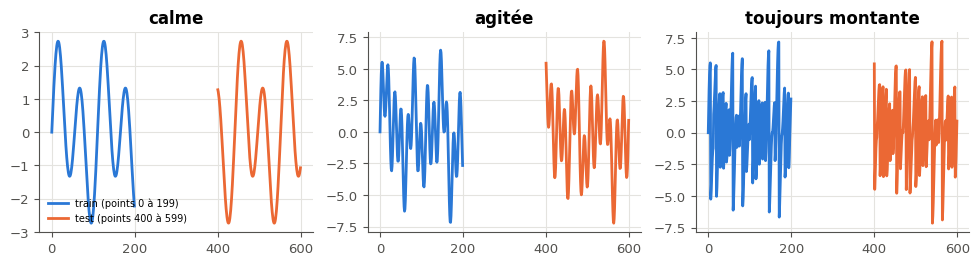

In [67]:
def SeriesScaler():
    """A new MinMaxScaler of your library (chapter 12): fit, transform, inverse_transform, on columns."""
    return mylearn.preprocessing.MinMaxScaler()


def make_windows(series, window, horizon=1, stride=1):
    """Your make_windows of chapter 22: X (N, window, 1) and y (N,)."""
    return mylearn.sequences.make_windows(series, window, horizon=horizon, stride=stride)


D_THETA = 0.057                                       # the book's angle between two points
CALM = {"freqs": (1, 2), "amps": (1, 2), "phases": (0, 0)}                       # the book's calm series
BUSY = {"freqs": (1.1, 1.7, 3.1, 7), "amps": (1, 2, 2, 3), "phases": (0, 0, 0, 0)}   # the book's busy series


def sum_of_sines(n_steps, d_theta, start, freqs, amps, phases):
    """s(n) = sum_k amps[k] * sin(freqs[k] * (phases[k] + n * d_theta)), for n = start .. start + n_steps - 1."""
    n = np.arange(start, start + n_steps)
    f, a, ph = (np.asarray(v, dtype=float) for v in (freqs, amps, phases))
    return (a * np.sin(f * (ph + (n * d_theta)[:, None]))).sum(axis=1)     # (n_steps, K), then sum over k


def upsloping(series):
    """The book's "always rising" series: every point where the sum goes down has its sign changed."""
    series = np.asarray(series, dtype=float)
    out = series.copy()
    out[1:][np.diff(series) < 0] *= -1
    return out


class TinyForecaster(nn.Module):
    """LSTM(1 -> hidden), then a linear read-out of the last time step: (N, w, 1) -> (N,)."""

    def __init__(self, hidden=3):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)             # no activation: a value, not a class

    def forward(self, x):
        output, (h_n, c_n) = self.lstm(x)            # output: (N, w, hidden)
        return self.head(output[:, -1]).squeeze(-1)  # last step only


class Stacked(nn.Module):
    """Stacked LSTMs of different sizes, like the book's 9, 6, 3, then a linear read-out of the last step."""

    def __init__(self, sizes=(9, 6, 3)):
        super().__init__()
        ins = (1,) + tuple(sizes[:-1])
        self.layers = nn.ModuleList(nn.LSTM(i, h, batch_first=True) for i, h in zip(ins, sizes))
        self.head = nn.Linear(sizes[-1], 1)

    def forward(self, x):
        for lstm in self.layers:
            x, _ = lstm(x)                             # the whole sequence goes to the next layer
        return self.head(x[:, -1]).squeeze(-1)


calm_train, calm_test = sum_of_sines(200, D_THETA, 0, **CALM), sum_of_sines(200, D_THETA, 400, **CALM)
busy_train, busy_test = sum_of_sines(200, D_THETA, 0, **BUSY), sum_of_sines(200, D_THETA, 400, **BUSY)
fig_d, axes_d = plt.subplots(1, 3, figsize=(12, 2.6))
for ax_d, (title_d, train_d, test_d) in zip(axes_d, [("calme", calm_train, calm_test), ("agitée", busy_train, busy_test),
                                                     ("toujours montante", upsloping(busy_train), upsloping(busy_test))]):
    ax_d.plot(range(200), train_d, label="train (points 0 à 199)")
    ax_d.plot(range(400, 600), test_d, label="test (points 400 à 599)")
    ax_d.set_title(title_d)
axes_d[0].legend(fontsize=7)
plt.show()

### Ex 24.25 — Sommes de sinus et LSTM minuscule : fenêtres, scaler, RMSE 📦 ★★★ ⏱️ 45 min
**Objectif :** préparer une série pour un LSTM sans fuite, l'entraîner, et mesurer sa RMSE dans les unités de la série, contre la persistance.  
**Prérequis :** ch. 22 (`make_windows`, persistance) · ch. 12 (`MinMaxScaler`) · ✏️ 24.5 · 24.Q10 · fiche §24.5.1 à §24.5.4 · **Fil rouge :** synth · **Parcours :** C

**Contrat**
- `prepare_25(train_series, test_series, window)` rend `(scaler, X_train, y_train, X_test, y_test)` : un `SeriesScaler` ajusté sur la colonne `train_series.reshape(-1, 1)` **seule**, les deux séries mises à l'échelle avec lui, puis découpées par `make_windows(..., window)` ; `X` en tenseurs `float32` $(N, w, 1)$, `y` en tenseurs `float32` $(N,)$ ;
- `fit_25(model, X, y, epochs=100, batch_size=16, lr=1e-2, seed=0)` entraîne `model` sur place (erreur quadratique moyenne, Adam, mini-batches mélangés de `make_loader(X, y, batch_size, seed)`) et rend la liste des losses moyennes d'entraînement, une par epoch ;
- `rmse_25(model, scaler, X, y)` rend la RMSE des prédictions de `model` (mode évaluation, sans graphe) sur `(X, y)`, **dans les unités de la série d'origine** : prédictions et cibles repassent par `scaler.inverse_transform` (en colonnes) ; un `float` Python ;
- `persistence_rmse_25(scaler, X, y)` rend la RMSE, dans les unités d'origine, de la persistance : prédire la dernière valeur de chaque fenêtre.

Le livre entraîne par batches d'un exemple ; des batches de 16 avec un learning rate de 0,01 vont bien plus vite. La vérification contrôle tes formes, ta mise à l'échelle (le min et le max du **train**), tes deux RMSE sur des cas calculables, puis cinq epochs ; la cellule suivante entraîne un `TinyForecaster(3)` sur les séries calme et agitée avec des fenêtres de 1, 3 et 5 points.

Dans tes notes : le réseau bat-il la persistance, et pour quelle fenêtre ? Que se passe-t-il avec une fenêtre d'un seul point, et pourquoi ? Pourquoi calculer la RMSE dans les unités de la série plutôt que dans l'échelle du scaler ?

In [68]:
def prepare_25(train_series, test_series, window):
    """(scaler, X_train, y_train, X_test, y_test): a SeriesScaler fitted on the column train_series.reshape(-1, 1) only,
    both series scaled with it, then cut by make_windows(..., window); X float32 tensors (N, window, 1), y float32
    tensors (N,)."""
    scaler = SeriesScaler().fit(np.asarray(train_series, dtype=float).reshape(-1, 1))   # min and max of the train only
    out = [scaler]
    for series in (train_series, test_series):
        scaled = scaler.transform(np.asarray(series, dtype=float).reshape(-1, 1)).ravel()
        X, y = make_windows(scaled, window=window)                                     # (N, w, 1) and (N,)
        out += [torch.as_tensor(X, dtype=torch.float32), torch.as_tensor(y, dtype=torch.float32)]
    return tuple(out)


def fit_25(model, X, y, epochs=100, batch_size=16, lr=1e-2, seed=0):
    """Train `model` in place on (X, y) with the mean squared error, Adam(lr) and shuffled mini-batches of batch_size
    from make_loader(X, y, batch_size, seed); return the list of the mean training loss of each epoch."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    loader = make_loader(X, y, batch_size, seed)
    losses = []
    for _ in range(epochs):
        model.train()
        total = 0.0
        for xb, yb in loader:
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
        losses.append(total / len(X))
    return losses


def _to_units_25(scaler, values):
    """Scaled values (N,) -> the original units (N,), through the scaler (a column in, a column out)."""
    return scaler.inverse_transform(np.asarray(values, dtype=float).reshape(-1, 1)).ravel()


def rmse_25(model, scaler, X, y):
    """The RMSE of the predictions of `model` (eval mode, no graph) on (X, y), in the units of the ORIGINAL series:
    predictions and targets both go back through scaler.inverse_transform (as columns). A Python float."""
    model.eval()
    with torch.inference_mode():
        pred = model(X).numpy()
    return float(np.sqrt(np.mean((_to_units_25(scaler, pred) - _to_units_25(scaler, y.numpy())) ** 2)))


def persistence_rmse_25(scaler, X, y):
    """The RMSE, in the original units, of the persistence forecast: predict the last value of each window."""
    last = X[:, -1, 0].numpy()
    return float(np.sqrt(np.mean((_to_units_25(scaler, last) - _to_units_25(scaler, y.numpy())) ** 2)))


class Zero_25(nn.Module):
    """A "model" that always predicts 0 (the training minimum, once scaled)."""

    def forward(self, x):
        return torch.zeros(len(x))


with checked("24.25"):
    scaler_25, X_tr_25, y_tr_25, X_te_25, y_te_25 = pair("24.25", "prepare_25(calm_train, calm_test, 3)",
                                                          prepare_25(calm_train, calm_test, 3),
                                                          names=("scaler", "X_train", "y_train", "X_test", "y_test"))
    verdict("24.25", tuple(X_tr_25.shape) == (197, 3, 1) and tuple(y_tr_25.shape) == (197,)
            and X_tr_25.dtype == torch.float32 and y_te_25.dtype == torch.float32,
            "200 points, des fenêtres de 3 : 197 exemples (197, 3, 1) et 197 cibles, en float32.",
            f"attendu X (197, 3, 1) et y (197,) en float32, reçu {tuple(X_tr_25.shape)} {X_tr_25.dtype} et "
            f"{tuple(y_tr_25.shape)} {y_te_25.dtype}.")
    lo_25, hi_25 = calm_train.min(), calm_train.max()
    same("24.25", "X_train[5] contre (train[5:8] - min) / (max - min), min et max du TRAIN", X_tr_25[5, :, 0],
         (calm_train[5:8] - lo_25) / (hi_25 - lo_25), rtol=1e-5, atol=1e-6)
    same("24.25", "y_test[0] contre (test[3] - min) / (max - min), avec le min et le max du TRAIN", y_te_25[:1],
         [(calm_test[3] - lo_25) / (hi_25 - lo_25)], rtol=1e-5, atol=1e-6)
    zero_rmse_25 = rmse_25(Zero_25(), scaler_25, X_te_25, y_te_25)
    if returned("24.25", "rmse_25", zero_rmse_25):
        same("24.25", "rmse_25 d'un modèle qui prédit toujours 0, dans les unités de la série",
             [zero_rmse_25], [np.sqrt(np.mean((lo_25 - calm_test[3:]) ** 2))], rtol=1e-5)
    same("24.25", "persistence_rmse_25 (prédire la dernière valeur de la fenêtre), dans les unités de la série",
         [persistence_rmse_25(scaler_25, X_te_25, y_te_25)], [np.sqrt(np.mean((calm_test[2:-1] - calm_test[3:]) ** 2))],
         rtol=1e-5)
    torch.manual_seed(0)
    losses_25 = fit_25(TinyForecaster(3), X_tr_25, y_tr_25, epochs=5)
    if returned("24.25", "fit_25", losses_25):
        verdict("24.25", len(losses_25) == 5 and losses_25[-1] < losses_25[0],
                f"fit_25 : 5 losses, de {fr(losses_25[0], 4)} à {fr(losses_25[-1], 4)}.",
                f"fit_25(..., epochs=5) doit rendre 5 losses qui baissent, reçu {losses_25!r:.200}.")

✅ Ex 24.25 : 200 points, des fenêtres de 3 : 197 exemples (197, 3, 1) et 197 cibles, en float32.
✅ Ex 24.25 : X_train[5] contre (train[5:8] - min) / (max - min), min et max du TRAIN : [0.74871218, 0.79235059, 0.83279109], comme attendu.
✅ Ex 24.25 : y_test[0] contre (test[3] - min) / (max - min), avec le min et le max du TRAIN : [0.68653238], comme attendu.
✅ Ex 24.25 : rmse_25 d'un modèle qui prédit toujours 0, dans les unités de la série : [3.13679768], comme attendu.
✅ Ex 24.25 : persistence_rmse_25 (prédire la dernière valeur de la fenêtre), dans les unités de la série : [0.17054295], comme attendu.
✅ Ex 24.25 : fit_25 : 5 losses, de 0,0634 à 0,0044.


série    fenêtre RMSE de test persistance


calme          1        0.188       0.170


calme          3        0.047       0.171


calme          5        0.038       0.171


agitée         1        0.893       0.886


agitée         3        0.129       0.884


agitée         5        0.129       0.882


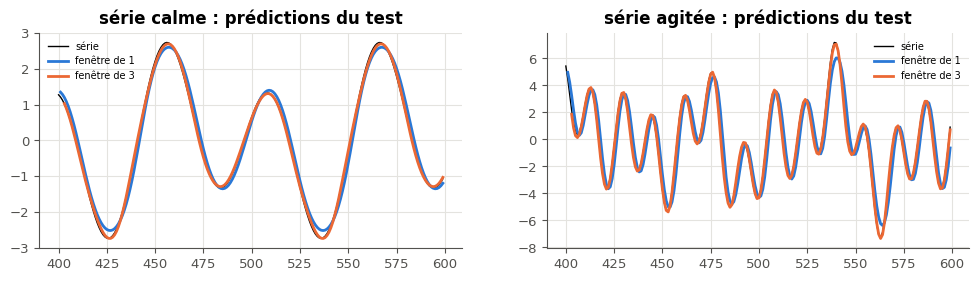

In [69]:
with checked("24.25"):
    print(f"{'série':8s} {'fenêtre':>7s} {'RMSE de test':>12s} {'persistance':>11s}")
    predictions_25 = {}
    for name_25, (train_25, test_25) in {"calme": (calm_train, calm_test), "agitée": (busy_train, busy_test)}.items():
        for window_25 in (1, 3, 5):
            scaler_25, X_tr_25, y_tr_25, X_te_25, y_te_25 = prepare_25(train_25, test_25, window_25)
            torch.manual_seed(2425)
            model_25 = TinyForecaster(3)
            fit_25(model_25, X_tr_25, y_tr_25)
            print(f"{name_25:8s} {window_25:7d} {rmse_25(model_25, scaler_25, X_te_25, y_te_25):12.3f} "
                  f"{persistence_rmse_25(scaler_25, X_te_25, y_te_25):11.3f}")
            with torch.inference_mode():
                predictions_25[name_25, window_25] = scaler_25.inverse_transform(model_25.eval()(X_te_25).numpy().reshape(-1, 1)).ravel()
    fig_25, axes_25 = plt.subplots(1, 2, figsize=(12, 2.8))
    for ax_25, (name_25, test_25) in zip(axes_25, [("calme", calm_test), ("agitée", busy_test)]):
        ax_25.plot(range(400, 600), test_25, "k", lw=1, label="série")
        for window_25 in (1, 3):
            ax_25.plot(range(400 + window_25, 600), predictions_25[name_25, window_25], label=f"fenêtre de {window_25}")
        ax_25.set_title(f"série {name_25} : prédictions du test")
        ax_25.legend(fontsize=7)
    plt.show()

💡 Avec une fenêtre de 3 ou 5 points, le petit LSTM suit très bien les deux séries et bat nettement la persistance (série calme : 0,047 et 0,038 contre 0,171 ; série agitée : 0,129 contre 0,884) : trois points suffisent à connaître la valeur, la pente et la courbure, donc à prolonger la courbe. Avec un seul point, le réseau ne voit qu'une valeur : il ne sait pas si la courbe monte ou descend, et il fait un peu moins bien que la persistance (0,188 contre 0,170). La RMSE dans les unités de la série se lit directement (« on se trompe de 0,05 en moyenne sur une courbe qui va de −3 à 3 ») et se compare d'une mise à l'échelle à l'autre ; dans l'échelle du scaler, elle dépendrait du min et du max du train.

### Ex 24.26 — Fenêtre, profondeur ou données : qu'est-ce qui aide vraiment ? 🔬 ★★★ ⏱️ 45 min
**Objectif :** mesurer séparément l'effet de la fenêtre, de la profondeur et de la quantité de données, à calcul égal.  
**Prérequis :** Ex 24.25 · ✏️ 24.5 · fiche §24.5.4 à §24.5.7 · **Fil rouge :** synth · **Parcours :** C

Sur la série « toujours montante » (la série agitée dont chaque descente est retournée), le livre essaie deux leviers à la fois : plus de couches, puis plus de données avec une fenêtre plus large. Tu les sépares, à **calcul égal** : chaque run fait le même nombre de pas d'optimisation (`STEPS_26`), si bien que plus de données ne veut pas dire plus de calcul.

**Contrat** : `run_26(n_train, window, sizes=(3,), steps=STEPS_26, seed=2426)` entraîne sur les `n_train` premiers points de `upsloping(sum_of_sines(..., **BUSY))` et rend `{"rmse": RMSE de test, "persistence": RMSE de la persistance, "epochs": epochs faites}` : `prepare_25` avec, pour test, `upsloping(sum_of_sines(200, D_THETA, TEST_START_26, **BUSY))` ; le modèle, construit juste après `torch.manual_seed(seed)`, est `TinyForecaster(sizes[0])` si `sizes` a une seule taille, `Stacked(sizes)` sinon ; `fit_25` avec des mini-batches de 32, un learning rate de 0,01, et le nombre d'epochs qui fait au moins `steps` pas.

La vérification essaie `run_26` sur un petit cas, puis lance la grille : 200 ou 2 000 points (et 20 000 en mode complet), des fenêtres de 5 ou 13, une couche de 3 ou trois couches de 9, 6 et 3 (un peu plus d'une minute en mode rapide).

Dans tes notes : lequel des trois leviers fait le plus baisser la RMSE de test ? Les trois couches aident-elles avec 200 points, avec 2 000 ? Pourquoi la fenêtre de 13 a-t-elle besoin de données pour servir ? Avec une seule graine, quels écarts oserais-tu interpréter ?

In [70]:
STEPS_26 = 4_000 if FAST_MODE else 8_000           # optimizer steps of every run (the same compute for all)
TEST_START_26 = 30_000                             # the test: 200 points from point 30 000, far from every train


def run_26(n_train, window, sizes=(3,), steps=STEPS_26, seed=2426):
    """Train on the first n_train points of upsloping(sum_of_sines(..., **BUSY)) and return a dict
    {"rmse": test RMSE, "persistence": persistence RMSE, "epochs": epochs done}: prepare_25 with the test
    upsloping(sum_of_sines(200, D_THETA, TEST_START_26, **BUSY)); the model, built just after torch.manual_seed(seed),
    is TinyForecaster(sizes[0]) when sizes has one size, Stacked(sizes) otherwise; fit_25 with mini-batches of 32,
    lr 1e-2 and the number of epochs that makes at least `steps` optimizer steps."""
    train = upsloping(sum_of_sines(n_train, D_THETA, 0, **BUSY))
    test = upsloping(sum_of_sines(200, D_THETA, TEST_START_26, **BUSY))
    scaler, X_tr, y_tr, X_te, y_te = prepare_25(train, test, window)
    torch.manual_seed(seed)
    model = TinyForecaster(sizes[0]) if len(sizes) == 1 else Stacked(sizes)
    epochs = math.ceil(steps / math.ceil(len(X_tr) / 32))          # mini-batches per epoch: ceil(N / 32)
    fit_25(model, X_tr, y_tr, epochs=epochs, batch_size=32, lr=1e-2, seed=seed)
    return {"rmse": rmse_25(model, scaler, X_te, y_te), "persistence": persistence_rmse_25(scaler, X_te, y_te),
            "epochs": epochs}


with checked("24.26"):
    probe_26 = run_26(200, 5, steps=10)
    if returned("24.26", "run_26", probe_26):
        verdict("24.26", isinstance(probe_26, dict) and probe_26.get("epochs") == 2 and probe_26.get("rmse", 0) > 0,
                f"run_26(200, 5, steps=10) : 195 fenêtres, 7 mini-batches par epoch, donc 2 epochs ; RMSE {fr(probe_26['rmse'])}.",
                f"200 points et une fenêtre de 5 : 195 fenêtres, 7 mini-batches de 32 par epoch ; 10 pas demandent 2 epochs. "
                f"Reçu {probe_26!r:.200}.")
    sizes_26 = (200, 2_000) if FAST_MODE else (200, 2_000, 20_000)
    results_26 = {}
    print(f"{'points':>6s} {'fenêtre':>7s} {'couches':>9s} {'epochs':>6s} {'RMSE de test':>12s} {'persistance':>11s}")
    for n_26 in sizes_26:
        for window_26 in (5, 13):
            for layers_26 in ((3,), (9, 6, 3)):
                r_26 = run_26(n_26, window_26, layers_26)
                results_26[n_26, window_26, layers_26] = r_26
                print(f"{n_26:6d} {window_26:7d} {str(layers_26):>9s} {r_26['epochs']:6d} {r_26['rmse']:12.3f} "
                      f"{r_26['persistence']:11.3f}")

✅ Ex 24.26 : run_26(200, 5, steps=10) : 195 fenêtres, 7 mini-batches par epoch, donc 2 epochs ; RMSE 2,874.
points fenêtre   couches epochs RMSE de test persistance


   200       5      (3,)    572        1.424       2.708


   200       5 (9, 6, 3)    572        1.112       2.708


   200      13      (3,)    667        1.287       2.668


   200      13 (9, 6, 3)    667        1.074       2.668


  2000       5      (3,)     64        1.388       2.708


  2000       5 (9, 6, 3)     64        0.943       2.708


  2000      13      (3,)     64        1.096       2.668


  2000      13 (9, 6, 3)     64        0.848       2.668


💡 À calcul égal (4 000 pas), le meilleur réglage réunit les trois leviers : trois couches, une fenêtre de 13 et 2 000 points (RMSE 0,85, contre 2,67 pour la persistance) ; le moins bon est le plus simple (une couche de 3, une fenêtre de 5 et 200 points : 1,42). La **profondeur** aide dans presque tous les cas ; les **données** aident surtout le réseau profond (de 1,07 à 0,85 avec une fenêtre de 13), le petit réseau de 3 valeurs d'état en profite moins (avec une fenêtre de 5, presque rien : de 1,42 à 1,39) ; la **fenêtre** de 13 aide avec 2 000 points, moins avec 200. Les leviers interagissent : c'est le réseau plus gros qui tire parti de plus de contexte et de plus d'exemples, ce que montrait aussi le livre. Sur trois graines (entrée `calib` de `tools/chapters/history_ch24.json`), les écarts de cet ordre (plusieurs dixièmes) se retrouvent ; à 1 500 pas, ils étaient noyés dans le bruit d'une graine à l'autre, d'où le budget choisi.

### Ex 24.27 — Séquences retournées, état porté entre batches, couche par pas de temps 📦 ★★★ ⏱️ 40 min
**Objectif :** lire les sorties de nn.LSTM, ranger une longue série en flux parallèles et porter l'état d'un morceau au suivant.  
**Prérequis :** Ex 24.25 · ✏️ 24.4 · 24.Q11 · ch. 22 (taches solaires) · fiche §24.5.8 à §24.5.10 · **Fil rouge :** taches solaires · **Parcours :** C

Les taches solaires (ch. 22) : une moyenne par mois depuis 1749, plus de 3 000 valeurs, une série trop longue pour une seule passe de rétropropagation, mais dont la mémoire (le cycle de 11 ans environ) dépasse une petite fenêtre.

**Contrat**
- `lstm_shapes_27(lstm, x)` rend `{"output": forme, "h_n": forme, "c_n": forme}`, les formes (tuples) de ce que rend `lstm(x)` ;
- `last_steps_27(lstm, x)` rend `(from_output, from_h_n)` : la sortie du **dernier** pas de temps de la **dernière** couche, lue dans `output` et dans `h_n`, deux tenseurs $(N, H)$ ; pour un LSTM bidirectionnel, le sens **avant** seulement : `output[:, -1, :H]` et `h_n[-2]` ;
- `to_streams_27(series, n_streams, seq_len)` rend `(X, Y)` : la série coupée en `n_streams` flux parallèles, puis en morceaux. Avec $L$ = `(len(series) - 1) // n_streams`, le flux $b$ est `series[b * L : b * L + L + 1]` ; `n_chunks = L // seq_len` ; `X[k, b, t, 0]` vaut `flux_b[k * seq_len + t]` et `Y[k, b, t]` vaut `flux_b[k * seq_len + t + 1]` ; tenseurs `float32` `(n_chunks, n_streams, seq_len, 1)` et `(n_chunks, n_streams, seq_len)` ;
- `run_carried_27(lstm, X, carry=True)` passe les morceaux `X[0]`, `X[1]`… dans l'ordre (sans graphe) et rend leurs sorties empilées, `(n_chunks, n_streams, seq_len, H)` ; avec `carry=True`, l'état `(h, c)` rendu par un morceau démarre le suivant, sinon chaque morceau part de l'état nul ;
- `train_carried_27(lstm, head, X, Y, epochs, lr=1e-2)` entraîne `lstm` et `head` (un `Linear(H, 1)` appliqué à chaque pas), l'état porté d'un morceau au suivant et **détaché** du graphe, nul au début de chaque epoch ; un pas d'Adam par morceau, sur l'erreur quadratique moyenne entre `head(output).squeeze(-1)` et `Y[k]` ; elle rend la loss moyenne de chaque epoch.

La vérification lit les formes de deux LSTM (a à d), compare tes deux lectures du dernier pas, essaie `to_streams_27` sur `np.arange(101)` puis compte les morceaux des taches solaires (e), et vérifie que l'état porté morceau après morceau donne **exactement** la même chose qu'une seule passe sur chaque flux. La cellule suivante entraîne un LSTM à état porté sur les taches solaires et compare son erreur, position par position dans un morceau, avec et sans état porté.

In [71]:
SUNSPOTS = wb.datasets.load_sunspots()["sunspots"].to_numpy(dtype=float)   # monthly means, since January 1749
print(len(SUNSPOTS), "mois ;", SUNSPOTS[:6])

3332 mois ; [ 96.7 104.3 116.7  92.8 141.7 139.2]


In [72]:
def lstm_shapes_27(lstm, x):
    """{"output": shape, "h_n": shape, "c_n": shape}, the shapes (tuples) of what lstm(x) returns."""
    output, (h_n, c_n) = lstm(x)
    return {"output": tuple(output.shape), "h_n": tuple(h_n.shape), "c_n": tuple(c_n.shape)}


def last_steps_27(lstm, x):
    """(from_output, from_h_n): the output of the LAST time step of the LAST layer, read in `output` and in `h_n`,
    two tensors (N, H). For a bidirectional LSTM, the FORWARD direction only: output[:, -1, :H] and h_n[-2]."""
    output, (h_n, _) = lstm(x)
    if lstm.bidirectional:                                 # h_n: (2 L, N, H), the two directions of each layer
        return output[:, -1, :lstm.hidden_size], h_n[-2]   # h_n[-1] is the backward direction of the last layer
    return output[:, -1], h_n[-1]


def to_streams_27(series, n_streams, seq_len):
    """(X, Y): the series cut into n_streams parallel streams, then into chunks. With L = (len(series) - 1) // n_streams,
    stream b is series[b * L : b * L + L + 1]; n_chunks = L // seq_len; X[k, b, t, 0] = stream_b[k * seq_len + t] and
    Y[k, b, t] = stream_b[k * seq_len + t + 1]. Float32 tensors (n_chunks, n_streams, seq_len, 1) and
    (n_chunks, n_streams, seq_len)."""
    series = np.asarray(series, dtype=np.float32)
    L = (len(series) - 1) // n_streams
    n_chunks = L // seq_len
    streams = np.stack([series[b * L:b * L + L + 1] for b in range(n_streams)])      # (n_streams, L + 1)
    inputs = streams[:, :n_chunks * seq_len].reshape(n_streams, n_chunks, seq_len)
    targets = streams[:, 1:n_chunks * seq_len + 1].reshape(n_streams, n_chunks, seq_len)
    X = torch.from_numpy(np.ascontiguousarray(inputs.transpose(1, 0, 2))).unsqueeze(-1)
    Y = torch.from_numpy(np.ascontiguousarray(targets.transpose(1, 0, 2)))
    return X, Y


def run_carried_27(lstm, X, carry=True):
    """Run the chunks X[0], X[1], ... in order (no graph) and return their outputs stacked, (n_chunks, n_streams,
    seq_len, H). With carry=True, the state (h, c) returned by a chunk starts the next one; otherwise every chunk
    starts from the zero state."""
    outputs, state = [], None
    with torch.inference_mode():
        for chunk in X:
            output, new_state = lstm(chunk, state if carry else None)
            outputs.append(output)
            state = new_state
    return torch.stack(outputs)


def train_carried_27(lstm, head, X, Y, epochs, lr=1e-2):
    """Train lstm + head (a Linear(H, 1) applied at every step) on the chunks, with the state carried from a chunk to
    the next and DETACHED from the graph, zero at the start of each epoch; one Adam(lr) step per chunk on the mean
    squared error between head(output).squeeze(-1) and Y[k]. Return the mean loss of each epoch."""
    optimizer = torch.optim.Adam(list(lstm.parameters()) + list(head.parameters()), lr=lr)
    loss_fn = nn.MSELoss()
    losses = []
    for _ in range(epochs):
        lstm.train()
        state, total = None, 0.0                             # zero state at the start of each epoch
        for xb, yb in zip(X, Y):                             # chunk k + 1 continues chunk k, row by row
            if state is not None:
                state = tuple(s.detach() for s in state)     # keep the values, cut the graph (truncated BPTT)
            output, state = lstm(xb, state)
            loss = loss_fn(head(output).squeeze(-1), yb)     # one shared Linear at every step
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item()
        losses.append(total / len(X))
    return losses


with checked("24.27"):
    torch.manual_seed(2427)
    deep_27 = nn.LSTM(2, 6, num_layers=3, batch_first=True)
    both_27 = nn.LSTM(2, 6, num_layers=2, batch_first=True, bidirectional=True)
    x_27 = torch.randn(4, 9, 2)
    shapes_27 = lstm_shapes_27(deep_27, x_27)
    if returned("24.27", "lstm_shapes_27", shapes_27):
        wb.check("24.27a", shape_text(shapes_27["output"]), computed=True)
        wb.check("24.27b", shape_text(shapes_27["h_n"]), computed=True)
        shapes_bi_27 = lstm_shapes_27(both_27, x_27)
        wb.check("24.27c", shape_text(shapes_bi_27["output"]), computed=True)
        wb.check("24.27d", shape_text(shapes_bi_27["h_n"]), computed=True)
    for label_27, lstm_27 in [("LSTM à 3 couches", deep_27), ("LSTM bidirectionnel à 2 couches", both_27)]:
        a_27, b_27 = pair("24.27", f"last_steps_27 ({label_27})", last_steps_27(lstm_27, x_27),
                          names=("from_output", "from_h_n"))
        if not same("24.27", f"{label_27} : le dernier pas lu dans output et dans h_n", a_27, b_27, rtol=1e-5, atol=1e-6):
            print("   ↳ les deux lectures diffèrent : dans h_n, les lignes vont par couche puis par sens (avant, arrière) ; "
                  "dans output, les deux sens sont côte à côte sur le dernier axe, et le sens arrière finit au pas 0.")
        verdict("24.27", tuple(a_27.shape) == (4, 6), "deux lectures (4, 6) de la même sortie.",
                f"attendu deux tenseurs (4, 6), reçu {tuple(a_27.shape)}.")
    X_toy_27, Y_toy_27 = pair("24.27", "to_streams_27(np.arange(101), 4, 5)", to_streams_27(np.arange(101.0), 4, 5),
                              names=("X", "Y"))
    verdict("24.27", tuple(X_toy_27.shape) == (5, 4, 5, 1) and tuple(Y_toy_27.shape) == (5, 4, 5)
            and X_toy_27.dtype == torch.float32,
            "101 valeurs, 4 flux de 25 pas, des morceaux de 5 : X (5, 4, 5, 1) et Y (5, 4, 5).",
            f"attendu X (5, 4, 5, 1) et Y (5, 4, 5) en float32, reçu {tuple(X_toy_27.shape)} et {tuple(Y_toy_27.shape)}.")
    same("24.27", "X[1, 2] (flux 2, 2e morceau)", X_toy_27[1, 2, :, 0], [55, 56, 57, 58, 59])
    same("24.27", "Y[1, 2] (la valeur suivante à chaque pas)", Y_toy_27[1, 2], [56, 57, 58, 59, 60])
    X_sun_27, Y_sun_27 = to_streams_27(SUNSPOTS / 100, 16, 24)
    wb.check("24.27e", int(X_sun_27.shape[0]), computed=True)
    torch.manual_seed(0)
    one_27 = nn.LSTM(1, 5, batch_first=True)
    carried_27 = run_carried_27(one_27, X_toy_27 / 100)
    with torch.inference_mode():
        whole_27, _ = one_27(X_toy_27.permute(1, 0, 2, 3).reshape(4, 25, 1) / 100)   # each stream in one pass
    same("24.27", "état porté morceau après morceau, contre chaque flux en une seule passe", carried_27,
         whole_27.reshape(4, 5, 5, 5).permute(1, 0, 2, 3), rtol=1e-4, atol=1e-5)
    reset_27 = run_carried_27(one_27, X_toy_27 / 100, carry=False)
    verdict("24.27", not torch.allclose(reset_27[1:], carried_27[1:], atol=1e-4) and torch.allclose(reset_27[0], carried_27[0]),
            "sans état porté, chaque morceau repart de zéro : seul le premier morceau est identique.",
            "carry=False doit repartir de l'état nul à chaque morceau (le premier morceau ne change pas, les autres si).")
    losses_27 = train_carried_27(nn.LSTM(1, 5, batch_first=True), nn.Linear(5, 1), X_toy_27 / 100, Y_toy_27 / 100, epochs=2)
    if returned("24.27", "train_carried_27", losses_27):
        verdict("24.27", len(losses_27) == 2, "train_carried_27 tourne deux epochs (l'état est bien détaché).",
                f"attendu 2 losses, reçu {losses_27!r:.120}.")

✅ Ex 24.27a : Bravo !
✅ Ex 24.27b : Exact !
✅ Ex 24.27c : Bien joué !
✅ Ex 24.27d : C'est ça !
✅ Ex 24.27 : LSTM à 3 couches : le dernier pas lu dans output et dans h_n : un tableau (4, 6), comme attendu.
✅ Ex 24.27 : deux lectures (4, 6) de la même sortie.
✅ Ex 24.27 : LSTM bidirectionnel à 2 couches : le dernier pas lu dans output et dans h_n : un tableau (4, 6), comme attendu.
✅ Ex 24.27 : deux lectures (4, 6) de la même sortie.
✅ Ex 24.27 : 101 valeurs, 4 flux de 25 pas, des morceaux de 5 : X (5, 4, 5, 1) et Y (5, 4, 5).
✅ Ex 24.27 : X[1, 2] (flux 2, 2e morceau) : [55.0, 56.0, 57.0, 58.0, 59.0], comme attendu.
✅ Ex 24.27 : Y[1, 2] (la valeur suivante à chaque pas) : [56.0, 57.0, 58.0, 59.0, 60.0], comme attendu.
✅ Ex 24.27e : Parfait !
✅ Ex 24.27 : état porté morceau après morceau, contre chaque flux en une seule passe : un tableau (5, 4, 5, 5), comme attendu.
✅ Ex 24.27 : sans état porté, chaque morceau repart de zéro : seul le premier morceau est identique.
✅ Ex 24.27 : train_car

In [73]:
torch.manual_seed(2427)
deep_27 = nn.LSTM(2, 6, num_layers=3, batch_first=True)
both_27 = nn.LSTM(2, 6, num_layers=2, batch_first=True, bidirectional=True)
x_27 = torch.randn(4, 9, 2)
wb.record("24.27a", shape_text(lstm_shapes_27(deep_27, x_27)["output"]), mistakes={
    "batch_first=True : l'axe des exemples vient en premier dans output": "(9, 4, 6)",
    "output ne garde que la dernière couche : pas d'axe des couches": "(3, 4, 9, 6)"})
wb.record("24.27b", shape_text(lstm_shapes_27(deep_27, x_27)["h_n"]), mistakes={
    "h_n garde l'axe des couches en premier et les exemples au milieu, même avec batch_first=True": "(4, 3, 6)",
    "h_n a une ligne par couche : trois couches ici": "(1, 4, 6)"})
wb.record("24.27c", shape_text(lstm_shapes_27(both_27, x_27)["output"]), mistakes={
    "bidirectional : les deux sens sont côte à côte, 2 H valeurs par pas": "(4, 9, 6)",
    "batch_first=True : l'axe des exemples vient en premier dans output": "(9, 4, 12)"})
wb.record("24.27d", shape_text(lstm_shapes_27(both_27, x_27)["h_n"]), mistakes={
    "h_n a une ligne par couche ET par sens : 2 couches × 2 sens": "(2, 4, 6)",
    "h_n ne met pas les deux sens côte à côte : une ligne par couche et par sens, de H valeurs chacune": "(2, 4, 12)"})
L_27 = (len(SUNSPOTS) - 1) // 16
wb.record("24.27e", int(to_streams_27(SUNSPOTS / 100, 16, 24)[0].shape[0]), mistakes={
    "chaque flux est coupé en morceaux : divise la longueur d'un FLUX, pas celle de la série, par seq_len": (len(SUNSPOTS) - 1) // 24,
    "c'est la longueur d'un flux : divise-la par seq_len pour compter les morceaux": L_27})

WB_ANSWER {"hash": "47f39a2be5f1aef7243d91f1bd4190e42af43fb4fa6f15e58dd6e6cf861dc03b", "id": "24.27a", "kind": "str", "mistakes": {"29d3aa0a2933044a5126a89c03dc505a5b788cbf369825fee5c3c7cc4fb08e20": "batch_first=True : l'axe des exemples vient en premier dans output", "91842e43029af3ba04c57a460efafa31b1dfb9220516616a6b54dc8992a3c142": "output ne garde que la dernière couche : pas d'axe des couches"}}
📝 Ex 24.27a : réponse enregistrée (str).
WB_ANSWER {"hash": "f85ea06371174e346807e4b3382bdd98fbaaec45fca94befa8a99e764ac01cfe", "id": "24.27b", "kind": "str", "mistakes": {"699a61ae324b4a22775b6cf4cb6ebdc8b0f2c79a41b144322bdb6ea9af0a6898": "h_n a une ligne par couche : trois couches ici", "7c48fe9f4051441a42d7ffc8f1b4c35ba14adef07f1293683b3b5058774e76b7": "h_n garde l'axe des couches en premier et les exemples au milieu, même avec batch_first=True"}}
📝 Ex 24.27b : réponse enregistrée (str).
WB_ANSWER {"hash": "55eb5f1ab67421ea9b41d4141c44886d4c45fe3af0aa200a7d42d5b1dc1baaeb", "id": "24.27c

8 morceaux de 24 mois par flux, 16 flux · loss de la 1re epoch 0.0511, de la 60e 0.0039
état porté                           erreur moyenne aux mois 1 à 3 du morceau 0.0033, aux mois 13 à 24 0.0038
état remis à zéro à chaque morceau   erreur moyenne aux mois 1 à 3 du morceau 0.0053, aux mois 13 à 24 0.0038


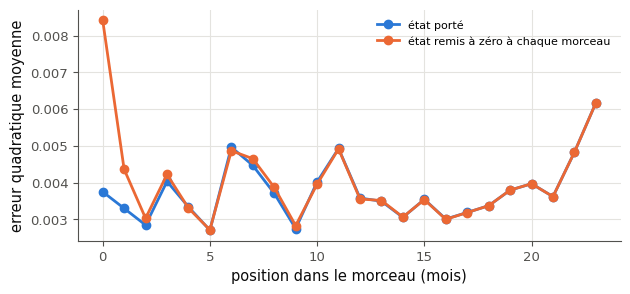

In [74]:
with checked("24.27"):
    scaled_27 = (SUNSPOTS - SUNSPOTS.min()) / (SUNSPOTS.max() - SUNSPOTS.min())
    X_27, Y_27 = to_streams_27(scaled_27, 16, 24)
    torch.manual_seed(2427)
    lstm_27, head_27 = nn.LSTM(1, 32, batch_first=True), nn.Linear(32, 1)
    losses_27 = train_carried_27(lstm_27, head_27, X_27, Y_27, epochs=60)
    print(f"{X_27.shape[0]} morceaux de 24 mois par flux, 16 flux · loss de la 1re epoch {losses_27[0]:.4f}, de la "
          f"60e {losses_27[-1]:.4f}")
    lstm_27.eval()
    with torch.inference_mode():
        errors_27 = {}
        for name_27, carry_27 in [("état porté", True), ("état remis à zéro à chaque morceau", False)]:
            out_27 = run_carried_27(lstm_27, X_27, carry=carry_27)
            errors_27[name_27] = ((head_27(out_27).squeeze(-1) - Y_27)[1:] ** 2).mean(dim=(0, 1))   # per position t
    for name_27, err_27 in errors_27.items():
        print(f"{name_27:36s} erreur moyenne aux mois 1 à 3 du morceau {float(err_27[:3].mean()):.4f}, aux mois 13 à 24 "
              f"{float(err_27[12:].mean()):.4f}")
    fig_27, ax_27 = plt.subplots(figsize=(7, 3))
    for name_27, err_27 in errors_27.items():
        ax_27.plot(range(24), err_27.numpy(), "o-", label=name_27)
    ax_27.set_xlabel("position dans le morceau (mois)")
    ax_27.set_ylabel("erreur quadratique moyenne")
    ax_27.legend(fontsize=8)
    plt.show()

Dans tes notes : pourquoi l'état porté donne-t-il exactement le résultat d'une seule passe sur tout le flux ? Pourquoi faut-il ranger la série en flux parallèles, plutôt que couper des morceaux consécutifs dans l'ordre du batch ? Sur la courbe, où l'état remis à zéro se trompe-t-il le plus, et pourquoi ? Qu'est-ce que le `detach()` coûte à l'apprentissage ?

💡 Un LSTM ne fait que transformer son état pas après pas : couper un flux en morceaux et passer l'état de l'un à l'autre fait exactement le même calcul qu'une seule passe. Pour que la ligne $b$ d'un batch continue la ligne $b$ du précédent, il faut ranger la série en $B$ flux contigus, un par ligne ; des morceaux consécutifs rangés dans le même batch se feraient passer l'état de la mauvaise ligne. Remis à zéro, le modèle se trompe surtout aux premiers mois de chaque morceau (une erreur de 0,0053 aux mois 1 à 3, contre 0,0033 avec l'état porté ; à partir du 13ᵉ mois, les deux font 0,0038) : il n'a encore rien vu du cycle en cours, et l'état porté lui donne ce contexte. Le `detach()` garde les valeurs mais coupe les gradients : le modèle ne peut pas apprendre à se servir de plus de 24 mois en arrière, même s'il les garde en mémoire.

## Partie E · Au-delà de nn.Sequential

Tu écris des modèles qui ne sont pas des piles : deux branches, une couche partagée, des blocs résiduels, et un gel propre d'une partie du réseau (24.28) ; tu mesures la précision mixte (24.29) ; tu génères du texte avec un embedding, au niveau du caractère et du mot (24.30) ; puis tu relèves le défi d'un CNN frugal sur CIFAR-10 (24.31).

La cellule suivante définit `ResidualBlock`, le bloc résiduel de la fiche. Les données de CIFAR-10 sont celles de la partie C.

In [75]:
class ResidualBlock(nn.Module):
    """The fiche's block: y = relu(F(x) + shortcut(x)); the shortcut is the identity, or a 1x1 conv when the shape
    changes."""

    def __init__(self, c_in, c_out, stride=1):
        super().__init__()
        self.f = nn.Sequential(
            nn.Conv2d(c_in, c_out, 3, stride=stride, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(),
            nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out),
        )
        self.shortcut = nn.Identity()
        if stride != 1 or c_in != c_out:              # match the shapes before adding
            self.shortcut = nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride=stride, bias=False),
                                          nn.BatchNorm2d(c_out))

    def forward(self, x):
        return torch.relu(self.f(x) + self.shortcut(x))   # the branch and the shortcut are summed

### Ex 24.28 — Au-delà de nn.Sequential : branches, addition, couches partagées, gel 📦 ★★★ ⏱️ 45 min
**Objectif :** écrire dans forward() des branches, une fusion, une couche partagée et un réseau résiduel, et geler une partie d'un réseau qui contient de la batchnorm.  
**Prérequis :** Ex 24.20 · 24.Q12 · 📄 24.10 · ch. 23 (Ex 23.24, gel et nouvelle tête) · fiche §24.6 à §24.6.2 · **Fil rouge :** CIFAR-10 · **Parcours :** R, C

En PyTorch, l'API fonctionnelle de Keras s'écrit dans `forward()`. La fiche montre un bloc résiduel ; tu écris les autres formes de graphe, puis un petit ResNet, et tu en gèles le début.

**Contrat**
- `TwoBranch_28(c_in, c_out, merge="add")` : deux branches lisent la **même** entrée, `Conv2d(c_in, c_out, 3, padding=1)` et `Conv2d(c_in, c_out, 1)` ; `"add"` les somme ($c_{out}$ canaux), `"cat"` les met côte à côte sur l'axe des canaux ($2c_{out}$ canaux) ; puis une ReLU ; toute autre fusion lève `ValueError` dès `__init__` ;
- `Siamese_28(encoder)` : `forward(a, b)` rend la distance au carré entre `encoder(a)` et `encoder(b)`, sommée sur les features, de forme $(N,)$ ; le **même** encodeur lit les deux entrées (des poids partagés) ;
- `make_resnet_28(widths=(16, 32, 64), n_classes=10)` rend un `nn.Sequential` : `Conv2d(3, widths[0], 3, padding=1, bias=False)`, `BatchNorm2d`, ReLU ; puis un `ResidualBlock` par largeur (stride 1 pour le premier, 2 pour les suivants ; `c_in` = la largeur précédente) ; puis `AdaptiveAvgPool2d(1)`, `Flatten` et `Linear(widths[-1], n_classes)` ;
- `freeze_28(module)` gèle `module` sur place : plus aucun de ses paramètres n'apprend, et ses batchnorms cessent de mettre à jour leurs statistiques glissantes ; il rend le module ;
- `train_mode_28(model, frozen)` met `model` en mode entraînement, sauf les modules de la liste `frozen`, qui restent en mode évaluation ;
- `trainable_28(model)` rend la liste des paramètres qui apprennent encore (pour l'optimiseur).

La vérification contrôle les formes et les paramètres de tes deux branches, le partage des poids du modèle siamois, compte les paramètres de ton ResNet (a, b) et ceux qui apprennent encore après le gel du tronc et du premier bloc (c), puis fait trois pas d'entraînement et vérifie que la partie gelée n'a pas bougé, statistiques glissantes comprises.

Dans tes notes : « add » et « cat » ont les mêmes paramètres : qu'est-ce qui change pour la couche suivante ? Pourquoi `requires_grad_(False)` ne suffit-il pas à geler une batchnorm ? Pourquoi le premier bloc du ResNet n'a-t-il pas de convolution 1 × 1 dans son raccourci ?

In [76]:
class TwoBranch_28(nn.Module):
    """TwoBranch_28(c_in, c_out, merge="add"): two branches read the SAME input, Conv2d(c_in, c_out, 3, padding=1) and
    Conv2d(c_in, c_out, 1); merge "add" sums them (c_out channels), "cat" puts them side by side along the channels
    (2 c_out channels); then a ReLU. Any other merge raises ValueError (in __init__)."""

    def __init__(self, c_in, c_out, merge="add"):
        super().__init__()
        if merge not in ("add", "cat"):
            raise ValueError(f"merge must be 'add' or 'cat', got {merge!r}")
        self.wide = nn.Conv2d(c_in, c_out, 3, padding=1)
        self.narrow = nn.Conv2d(c_in, c_out, 1)
        self.merge = merge

    def forward(self, x):
        a, b = self.wide(x), self.narrow(x)              # two branches, the same input
        merged = a + b if self.merge == "add" else torch.cat([a, b], dim=1)
        return torch.relu(merged)


class Siamese_28(nn.Module):
    """Siamese_28(encoder): forward(a, b) returns the squared distance between encoder(a) and encoder(b), summed over
    the features, shape (N,). The SAME encoder reads both inputs (shared weights)."""

    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder                           # one module, called twice: its weights are shared

    def forward(self, a, b):
        return ((self.encoder(a) - self.encoder(b)) ** 2).flatten(1).sum(dim=1)


def make_resnet_28(widths=(16, 32, 64), n_classes=10):
    """An nn.Sequential: Conv2d(3, widths[0], 3, padding=1, bias=False), BatchNorm2d, ReLU; then one ResidualBlock per
    width (stride 1 for the first, 2 for the others; c_in = the previous width); then AdaptiveAvgPool2d(1), Flatten and
    Linear(widths[-1], n_classes)."""
    layers = [nn.Conv2d(3, widths[0], 3, padding=1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU()]
    c_in = widths[0]
    for i, width in enumerate(widths):
        layers.append(ResidualBlock(c_in, width, stride=1 if i == 0 else 2))
        c_in = width
    layers += [nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(c_in, n_classes)]
    return nn.Sequential(*layers)


def freeze_28(module):
    """Freeze `module` in place: no parameter of it learns any more, and its batchnorm layers stop updating their
    running statistics. Return the module."""
    module.requires_grad_(False)                         # no gradient, no update of gamma, beta, weights
    module.eval()                                        # batchnorm: use (and keep) the running statistics
    return module


def train_mode_28(model, frozen):
    """Put `model` in train mode, except the modules of the list `frozen`, which stay in eval mode."""
    model.train()                                        # train() reaches every submodule...
    for module in frozen:
        module.eval()                                    # ... so the frozen ones go back to eval mode


def trainable_28(model):
    """The list of the parameters of `model` that still learn (to give to the optimizer)."""
    return [p for p in model.parameters() if p.requires_grad]


with checked("24.28"):
    x_28 = torch.randn(2, 4, 16, 16)
    add_28, cat_28 = TwoBranch_28(4, 8, "add"), TwoBranch_28(4, 8, "cat")
    with torch.no_grad():
        out_add_28, out_cat_28 = add_28(x_28), cat_28(x_28)
    verdict("24.28", tuple(out_add_28.shape) == (2, 8, 16, 16) and tuple(out_cat_28.shape) == (2, 16, 16, 16)
            and float(out_add_28.min()) >= 0 and n_params(add_28) == n_params(cat_28),
            "deux branches : (2, 8, 16, 16) en somme, (2, 16, 16, 16) côte à côte, ReLU à la fin, les mêmes paramètres.",
            f"attendu (2, 8, 16, 16) avec « add » et (2, 16, 16, 16) avec « cat », des sorties positives (ReLU) et le même "
            f"nombre de paramètres ; reçu {tuple(out_add_28.shape)} et {tuple(out_cat_28.shape)}.")
    refuses("24.28", "TwoBranch_28(4, 8, merge=\"mul\")", lambda: TwoBranch_28(4, 8, merge="mul"))
    torch.manual_seed(0)
    encoder_28 = nn.Sequential(nn.Flatten(), nn.Linear(12, 5))
    siamese_28 = Siamese_28(encoder_28)
    a_28, b_28 = torch.randn(3, 3, 4), torch.randn(3, 3, 4)
    d_28 = siamese_28(a_28, b_28)
    same("24.28", "Siamese_28 : distances au carré", d_28, ((encoder_28(a_28) - encoder_28(b_28)) ** 2).sum(dim=1),
         rtol=1e-5, atol=1e-6)
    verdict("24.28", n_params(siamese_28) == n_params(encoder_28) and float(siamese_28(a_28, a_28).abs().max()) == 0.0,
            f"un seul encodeur pour les deux entrées : {n_params(siamese_28)} paramètres, distance nulle d'une image à elle-même.",
            f"le modèle siamois doit avoir les {n_params(encoder_28)} paramètres de l'encodeur, pas une copie ; reçu "
            f"{n_params(siamese_28)}.")
    resnet_28 = make_resnet_28()
    if returned("24.28", "make_resnet_28", resnet_28):
        wb.check("24.28a", n_params(resnet_28), computed=True)
        wb.check("24.28b", n_params(make_resnet_28(widths=(32, 64, 128))), computed=True)
        with torch.inference_mode():
            logits_28 = resnet_28.eval()(torch.zeros(2, 3, 32, 32))
        verdict("24.28", tuple(logits_28.shape) == (2, 10) and sum(isinstance(m, ResidualBlock) for m in resnet_28) == 3,
                "trois blocs résiduels, et (2, 10) pour deux images.",
                f"attendu trois ResidualBlock et une sortie (2, 10), reçu {tuple(logits_28.shape)}.")
        torch.manual_seed(1)
        model_28 = make_resnet_28()
        frozen_28 = [model_28[0], model_28[1], model_28[3]]          # the stem convolution, its batchnorm, the 1st block
        for module_28 in frozen_28:
            freeze_28(module_28)
        wb.check("24.28c", sum(p.numel() for p in trainable_28(model_28)), computed=True)
        before_28 = {k: v.clone() for k, v in model_28.state_dict().items()}
        optimizer_28 = torch.optim.SGD(trainable_28(model_28), lr=0.1)
        for _ in range(3):
            train_mode_28(model_28, frozen_28)
            loss_28 = nn.functional.cross_entropy(model_28(torch.randn(8, 3, 32, 32)), torch.randint(10, (8,)))
            optimizer_28.zero_grad()
            loss_28.backward()
            optimizer_28.step()
        moved_28 = sorted({k.split(".")[0] for k, v in model_28.state_dict().items() if not torch.equal(v, before_28[k])})
        verdict("24.28", "8" in moved_28 and not any(k in moved_28 for k in ("0", "1", "3")),
                f"après trois pas, la partie gelée (statistiques glissantes comprises) n'a pas bougé ; ont changé : {moved_28}.",
                f"des modules gelés ont changé : {moved_28} (0, 1 et 3 doivent rester intacts, statistiques glissantes de "
                "la batchnorm comprises : model.train() remet tout en mode entraînement).")
        verdict("24.28", model_28.training and not model_28[1].training and not model_28[3].f[1].training,
                "train_mode_28 : le modèle s'entraîne, ses batchnorms gelées restent en mode évaluation.",
                "après train_mode_28, le modèle doit être en mode entraînement et les modules gelés en mode évaluation.")

✅ Ex 24.28 : deux branches : (2, 8, 16, 16) en somme, (2, 16, 16, 16) côte à côte, ReLU à la fin, les mêmes paramètres.
✅ Ex 24.28 : TwoBranch_28(4, 8, merge="mul") : ValueError levée (merge must be 'add' or 'cat', got 'mul').
✅ Ex 24.28 : Siamese_28 : distances au carré : [9.50630951, 4.08705568, 2.15555596], comme attendu.
✅ Ex 24.28 : un seul encodeur pour les deux entrées : 65 paramètres, distance nulle d'une image à elle-même.
✅ Ex 24.28a : Exact !
✅ Ex 24.28b : Bien joué !
✅ Ex 24.28 : trois blocs résiduels, et (2, 10) pour deux images.
✅ Ex 24.28c : C'est ça !
✅ Ex 24.28 : après trois pas, la partie gelée (statistiques glissantes comprises) n'a pas bougé ; ont changé : ['4', '5', '8'].
✅ Ex 24.28 : train_mode_28 : le modèle s'entraîne, ses batchnorms gelées restent en mode évaluation.


/tmp/ipykernel_5318/2556973102.py:83: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  verdict("24.28", n_params(siamese_28) == n_params(encoder_28) and float(siamese_28(a_28, a_28).abs().max()) == 0.0,


In [77]:
wb.record("24.28a", n_params(make_resnet_28()), mistakes={
    "chaque BatchNorm2d apprend deux nombres par canal (γ et β)": n_params(make_resnet_28()) - sum(
        p.numel() for m in make_resnet_28().modules() if isinstance(m, nn.BatchNorm2d) for p in m.parameters()),
    "les raccourcis 1 × 1 des blocs qui changent de forme ont des paramètres (une convolution et une batchnorm)": n_params(make_resnet_28()) - (16 * 32 + 64) - (32 * 64 + 128),
    "le premier bloc garde 16 canaux et un stride de 1 : son raccourci est l'identité, sans paramètres": n_params(make_resnet_28()) + 16 * 16 + 32})
wb.record("24.28b", n_params(make_resnet_28(widths=(32, 64, 128))), mistakes={
    "doubler les largeurs multiplie les poids des convolutions par 4 environ, pas par 2": 2 * n_params(make_resnet_28())})
frozen_count_28 = sum(p.numel() for m in (make_resnet_28()[0], make_resnet_28()[1], make_resnet_28()[3]) for p in m.parameters())
wb.record("24.28c", n_params(make_resnet_28()) - frozen_count_28, mistakes={
    "relis la question : on demande les paramètres qui apprennent ENCORE, pas ceux qu'on a gelés": frozen_count_28,
    "la batchnorm du tronc (module 1) fait partie de la partie gelée : ses 32 paramètres n'apprennent plus": n_params(make_resnet_28()) - frozen_count_28 + 32})

WB_ANSWER {"hash": "8e5175bef7e25e57cde06cb8a293c646f3e4d5d7be3db6523ffeb7a08effafc5", "id": "24.28a", "kind": "int", "magnitude": 4, "mistakes": {"6fdef81acbde3a5c8d552b369a6993d71afcd61879715d656791ffa802a5d2d6": "chaque BatchNorm2d apprend deux nombres par canal (γ et β)", "99493ed5a88e17c3d8ab9773e238c407946d92908f7fbc2d3d1c365e59e298b4": "les raccourcis 1 × 1 des blocs qui changent de forme ont des paramètres (une convolution et une batchnorm)", "a8112581e85007e867d2f04ae746b9f09dfc78bcd8b30480ad56715092c5fac0": "le premier bloc garde 16 canaux et un stride de 1 : son raccourci est l'identité, sans paramètres"}, "sign": 1}
📝 Ex 24.28a : réponse enregistrée (int).
WB_ANSWER {"hash": "496de58daf1b646e61dc5218deb7dc8274b84fbfddc4171fc93a7d25f1001e9f", "id": "24.28b", "kind": "int", "magnitude": 5, "mistakes": {"d59762923e2aabffe046532998fe1ae91316b9e2d7c8db7c074c3434c8655b2e": "doubler les largeurs multiplie les poids des convolutions par 4 environ, pas par 2"}, "sign": 1}
📝 Ex 24.28

WB_ANSWER {"hash": "dfc9eae6d14b5a82dceb705161083b10e956f9efa1fba1399a13e59af714f331", "id": "24.28c", "kind": "int", "magnitude": 4, "mistakes": {"5e3b07559037ec40a8e0449a4b5dffe574094c816558371e55279d6b067e8317": "relis la question : on demande les paramètres qui apprennent ENCORE, pas ceux qu'on a gelés", "6fbd837a7f0859f52387003960e5ac4b9d2c8bb4db0475a7fae22cf3bcb2fc46": "la batchnorm du tronc (module 1) fait partie de la partie gelée : ses 32 paramètres n'apprennent plus"}, "sign": 1}
📝 Ex 24.28c : réponse enregistrée (int).


In [78]:
with checked("24.28"):
    for name_28, model_28 in [("make_deep_cnn_20(batchnorm=True)", make_deep_cnn_20(batchnorm=True)),
                              ("make_resnet_28()", make_resnet_28())]:
        dense_28 = sum(p.numel() for m in model_28.modules() if isinstance(m, nn.Linear) for p in m.parameters())
        print(f"{name_28:34s} {n_params(model_28):7d} paramètres, dont {dense_28:6d} dans la couche dense")

make_deep_cnn_20(batchnorm=True)     82554 paramètres, dont  10250 dans la couche dense
make_resnet_28()                     78042 paramètres, dont    650 dans la couche dense


💡 La somme garde $c_{out}$ canaux : la couche suivante a deux fois moins de poids d'entrée, mais les deux branches doivent avoir la même forme. La concaténation garde les deux informations séparées, au prix d'une couche suivante plus grosse. `requires_grad_(False)` arrête les gradients, donc $\gamma$ et $\beta$ ne bougent plus, mais en mode entraînement la batchnorm met à jour sa moyenne et sa variance glissantes à chaque passe avant : il faut la remettre en mode évaluation après chaque `model.train()`. Le premier bloc garde 16 canaux et la même taille : $F(x)$ et $x$ ont déjà la même forme, le raccourci est l'identité, sans paramètres. Le ResNet de 78 042 paramètres n'en met que 650 dans sa couche dense, grâce au pooling moyen global.

### Ex 24.29 — Précision mixte et torch.compile : mesurer avant de croire 📦 ★★ ⏱️ 25 min
**Objectif :** mesurer honnêtement le temps d'un pas d'entraînement, en float32 et en précision mixte, et vérifier que l'apprentissage ne se dégrade pas.  
**Prérequis :** Ex 24.20 · 🧮 24.7 · fiche « Au-delà du livre : précision mixte et compilation » · **Fil rouge :** CIFAR-10 · **Parcours :** C

La précision mixte accélère beaucoup les GPU récents ; sur un CPU, c'est moins sûr. Tu la mesures avant de l'adopter. La cellule donnée prépare 23 mini-batches de 128 images (`BATCHES_29`) et l'option `TRY_COMPILE_29` (passe-la à `True` pour mesurer aussi `torch.compile`, qui demande un compilateur C++ : sous Windows, celui de Microsoft, MSVC).

**Contrat**
- `amp_dtype_29(device_type)` rend le type 16 bits de la précision mixte : `torch.bfloat16` pour `"cpu"`, `torch.float16` pour `"cuda"` ; `ValueError` sinon ;
- `time_steps_29(model, batches, amp=False, warmup=3, lr=1e-3)` entraîne `model` (sur `DEVICE`), un pas par mini-batch de la liste `batches`, avec un Adam créé dans la fonction et la cross-entropy ; avec `amp=True`, la passe avant et la loss se font sous `torch.autocast(device_type, dtype=amp_dtype_29(device_type))` et le pas passe par un `torch.amp.GradScaler` (activé pour le `float16` seulement) ; les `warmup` premiers pas ne sont pas chronométrés ; chaque autre pas est chronométré seul avec `time.perf_counter` (après `torch.cuda.synchronize()` sur un GPU) ; la fonction rend `(durée médiane d'un pas chronométré, liste des losses des pas chronométrés, en float Python)`.

La vérification contrôle tes types et ta mesure sur un petit modèle ; la cellule suivante entraîne deux copies du **même** CNN (mêmes poids de départ, mêmes mini-batches), en float32 et en précision mixte, et compare leurs temps et leurs losses. Aucun temps n'est vérifié : il dépend de ta machine.

Dans tes notes : la précision mixte accélère-t-elle ici ? Sur quel matériel gagnerait-elle vraiment, et pourquoi ? Pourquoi ne pas chronométrer les premiers pas ? Pourquoi la médiane plutôt que la moyenne ? Que se passerait-il en `float16` sans `GradScaler` ?

In [79]:
BATCHES_29 = [(XC_TR_T[i:i + 128], YC_TR_T[i:i + 128]) for i in range(0, 23 * 128, 128)]   # 23 mini-batches of 128
TRY_COMPILE_29 = False      # True to also time torch.compile (it needs a C++ compiler; slow first step)

In [80]:
def amp_dtype_29(device_type):
    """The 16-bit type of mixed precision: torch.bfloat16 on "cpu", torch.float16 on "cuda"; ValueError otherwise."""
    types = {"cpu": torch.bfloat16, "cuda": torch.float16}
    if device_type not in types:
        raise ValueError(f"no mixed precision type for {device_type!r}")
    return types[device_type]


def time_steps_29(model, batches, amp=False, warmup=3, lr=1e-3):
    """Train `model` (on DEVICE) one step per mini-batch of the list `batches`, with Adam(lr) created here and the
    cross-entropy; with amp=True, the forward pass and the loss run under torch.autocast(device_type, dtype=
    amp_dtype_29(device_type)) and the step goes through a torch.amp.GradScaler (enabled for float16 only). The first
    `warmup` steps are not timed; each other step is timed alone with time.perf_counter (after
    torch.cuda.synchronize() on a GPU). Return (the median duration of a timed step, the list of the losses of the
    timed steps as Python floats)."""
    device_type = "cuda" if str(DEVICE).startswith("cuda") else "cpu"
    dtype = amp_dtype_29(device_type)
    model.to(DEVICE).train()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scaler = torch.amp.GradScaler(device_type, enabled=(amp and dtype == torch.float16))
    durations, losses = [], []
    for i, (xb, yb) in enumerate(batches):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        if device_type == "cuda":
            torch.cuda.synchronize()                       # the GPU computes asynchronously
        start = time.perf_counter()
        with torch.autocast(device_type=device_type, dtype=dtype, enabled=amp):
            loss = nn.functional.cross_entropy(model(xb), yb)
        optimizer.zero_grad()
        scaler.scale(loss).backward()                      # identity when the scaler is disabled
        scaler.step(optimizer)
        scaler.update()
        if device_type == "cuda":
            torch.cuda.synchronize()
        if i >= warmup:                                    # the first steps warm up (and compile)
            durations.append(time.perf_counter() - start)
            losses.append(loss.item())
    return float(np.median(durations)), losses


with checked("24.29"):
    verdict("24.29", amp_dtype_29("cpu") == torch.bfloat16 and amp_dtype_29("cuda") == torch.float16,
            "bfloat16 sur CPU, float16 sur GPU.", "attendu torch.bfloat16 pour \"cpu\" et torch.float16 pour \"cuda\".")
    refuses("24.29", "amp_dtype_29(\"tpu\")", lambda: amp_dtype_29("tpu"))
    layer_29 = nn.Linear(8, 4)
    with torch.autocast(device_type="cpu", dtype=torch.bfloat16):
        inside_29 = layer_29(torch.randn(2, 8))
    print(f"ℹ️ sous autocast (CPU) : nn.Linear rend du {inside_29.dtype} ; ses poids restent en {layer_29.weight.dtype}.")
    torch.manual_seed(2429)
    small_29 = nn.Sequential(nn.Flatten(), nn.Linear(3 * 32 * 32, 32), nn.ReLU(), nn.Linear(32, 10))
    result_29 = time_steps_29(small_29, BATCHES_29[:8])
    median_29, losses_29 = pair("24.29", "time_steps_29(model, 8 batches)", result_29, names=("median", "losses"),
                                floats=("median",))
    verdict("24.29", median_29 > 0 and len(losses_29) == 5 and all(isinstance(v, float) and math.isfinite(v) for v in losses_29),
            f"8 mini-batches, 3 pas de chauffe : 5 pas mesurés, médiane {fr(1000 * median_29, 1)} ms.",
            f"attendu une médiane positive et 5 losses (8 pas moins 3 de chauffe) en float, reçu {median_29!r} et {losses_29!r:.120}.")

✅ Ex 24.29 : bfloat16 sur CPU, float16 sur GPU.
✅ Ex 24.29 : amp_dtype_29("tpu") : ValueError levée (no mixed precision type for 'tpu').
ℹ️ sous autocast (CPU) : nn.Linear rend du torch.bfloat16 ; ses poids restent en torch.float32.
✅ Ex 24.29 : 8 mini-batches, 3 pas de chauffe : 5 pas mesurés, médiane 1,4 ms.


In [81]:
with checked("24.29"):
    torch.manual_seed(2429)
    base_29 = make_deep_cnn_20(batchnorm=True)
    runs_29 = {"float32": (copy.deepcopy(base_29), False), "précision mixte": (copy.deepcopy(base_29), True)}
    if TRY_COMPILE_29:
        runs_29["float32 + torch.compile"] = (torch.compile(copy.deepcopy(base_29)), False)
    timing_29 = {name: time_steps_29(model, BATCHES_29, amp=amp) for name, (model, amp) in runs_29.items()}
    for name_29, (median_29, losses_29) in timing_29.items():
        print(f"{name_29:24s} {1000 * median_29:7.1f} ms par pas · loss du 1er pas mesuré {losses_29[0]:.3f}, du dernier "
              f"{losses_29[-1]:.3f}")
    ref_29, mixed_29 = timing_29["float32"], timing_29["précision mixte"]
    print(f"rapport des temps (précision mixte / float32) : {mixed_29[0] / ref_29[0]:.2f} sur {DEVICE}")
    verdict("24.29", abs(np.mean(mixed_29[1][-5:]) - np.mean(ref_29[1][-5:])) < 0.15 * np.mean(ref_29[1][-5:]),
            "la précision mixte apprend comme le float32 (losses des 5 derniers pas à moins de 15 % l'une de l'autre).",
            "les losses de la précision mixte s'écartent de plus de 15 % de celles du float32 : vérifie l'autocast et le "
            "GradScaler.")

float32                     73.2 ms par pas · loss du 1er pas mesuré 2.241, du dernier 1.858
précision mixte             54.8 ms par pas · loss du 1er pas mesuré 2.242, du dernier 1.856
rapport des temps (précision mixte / float32) : 0.75 sur cpu
✅ Ex 24.29 : la précision mixte apprend comme le float32 (losses des 5 derniers pas à moins de 15 % l'une de l'autre).


💡 Sur le CPU de génération (2 cœurs), la précision mixte va environ 25 à 30 % plus vite (le rapport des temps varie d'une exécution à l'autre, entre 0,69 et 0,76) ; sur un processeur sans instructions `bfloat16` (AVX-512 BF16, AMX), elle peut ne rien gagner, voire ralentir, à cause des conversions de type : c'est pourquoi on mesure. Sur un GPU récent (cœurs tensoriels), les produits de matrices et les convolutions en 16 bits vont plusieurs fois plus vite, et les activations prennent deux fois moins de mémoire. Les losses restent les mêmes à 0,002 près. Les premiers pas paient l'allocation de la mémoire, le choix des algorithmes et, avec `torch.compile`, la compilation : les compter fausserait la mesure. La médiane ignore les pas ralentis par autre chose (le système, un autre programme). En `float16` sans `GradScaler`, les petits gradients s'arrondissent à zéro et l'entraînement stagne sans aucune erreur.

### Ex 24.30 — Générer du texte : embeddings, séquences décalées, mots contre caractères 📦 ★★★★ ⏱️ 100 min
**Objectif :** entraîner deux modèles de langage (caractères et mots) avec un embedding et une loss à chaque position, les comparer honnêtement et générer du texte.  
**Prérequis :** ch. 22 (`build_vocab`, `encode`, `make_sequence_pairs`, `sample_from_logits`) · Ex 24.27 · 24.R3 · ch. 6 (perplexité) · fiche §24.5.11 · **Fil rouge :** Holmes · **Parcours :** C

Le générateur de texte du livre, en mieux : un embedding au lieu du one-hot, une loss à **chaque** position au lieu d'une seule, et une comparaison honnête entre un modèle de caractères et un modèle de mots. La cellule donnée charge les aventures de Sherlock Holmes, reprend tes outils du ch. 22 et `WordLM`, le modèle de la fiche (qui sert aussi pour les caractères).

**Contrat**
- `tokenize_words_30(text)` met le texte en minuscules et le découpe : les mots (suites de lettres de a à z, une apostrophe `'` ou `’` **à l'intérieur** d'un mot étant gardée : `"holmes’s"`, `"don't"`) et un token pour chaque autre caractère qui n'est pas une espace (ponctuation, chiffres, lettres accentuées) ;
- `make_vocab_30(tokens, max_size)` rend `(stoi, itos)` : `build_vocab` de ta librairie avec le token inconnu `"<unk>"` (id 0), au plus `max_size` entrées ;
- `unk_rate_30(ids)` rend la part des ids qui valent le token inconnu (0), un `float` Python ;
- `split_pairs_30(ids, seq_len, val_share=0.1)` rend `(X_tr, Y_tr, X_val, Y_val)`, des tenseurs `int64` : les `int(len(ids) * val_share)` derniers ids pour la validation, les autres pour l'entraînement, chaque partie découpée par `make_sequence_pairs(partie, seq_len)` (des morceaux qui ne se chevauchent pas) ;
- `train_lm_30(model, X, Y, epochs, batch_size=64, lr=3e-3, seed=0)` entraîne le modèle de langage (ids $(N, T)$ → `(logits (N, T, V), état)`) : Adam, mini-batches mélangés de `make_loader(X, Y, batch_size, seed)`, la cross-entropy sur **toutes** les positions (`logits.reshape(-1, V)`), les gradients limités à une norme de 1 (`nn.utils.clip_grad_norm_`) ; elle rend la loss moyenne d'entraînement par token de chaque epoch ;
- `mean_loss_30(model, X, Y, batch_size=256)` rend la cross-entropy moyenne par token sur `(X, Y)`, en nats (mode évaluation, sans graphe) ;
- `generate_30(model, prompt_ids, n_tokens, temperature=1.0, seed=0)` rend `n_tokens` nouveaux ids (une liste d'entiers) : le modèle lit le prompt, puis un token à la fois, son état porté d'un appel à l'autre ; chaque id est tiré par `sample_from_logits(logits du dernier pas, temperature, rng=rng)`, avec **un seul** générateur `rng = np.random.default_rng(seed)`, créé au début et passé à chaque tirage.

La vérification essaie ton tokeniseur, compte les tokens des 150 000 premiers caractères (a) et la part de tokens inconnus avec 2 001 entrées (b), contrôle tes paires, la perplexité d'un modèle non entraîné, l'entraînement et la génération. La cellule suivante entraîne un modèle de caractères et un modèle de mots `EPOCHS_30` epochs, compare leurs losses **par caractère** et génère à trois températures ; la dernière trace `HISTORY_30`, les mêmes modèles entraînés 20 epochs sur tout le texte.

Dans tes notes : pourquoi la perplexité d'un modèle non entraîné vaut-elle à peu près $V$ ? Pourquoi ne pas comparer directement la perplexité du modèle de mots à celle du modèle de caractères, et que vaut la comparaison par caractère ? En quoi le token inconnu avantage-t-il le modèle de mots ? Comment la température change-t-elle les textes ?

In [82]:
HOLMES = wb.datasets.load_holmes()
TEXT_30 = HOLMES[:150_000] if FAST_MODE else HOLMES            # the text the models of the experiment learn
EPOCHS_30 = 6 if FAST_MODE else 20


def build_vocab(*args, **kwargs):           # your chapter 22 library (mylearn.sequences), called through these names
    return mylearn.sequences.build_vocab(*args, **kwargs)


def encode(*args, **kwargs):
    return mylearn.sequences.encode(*args, **kwargs)


def make_sequence_pairs(*args, **kwargs):
    return mylearn.sequences.make_sequence_pairs(*args, **kwargs)


def sample_from_logits(*args, **kwargs):
    return mylearn.sequences.sample_from_logits(*args, **kwargs)


class WordLM(nn.Module):
    """The fiche's model: ids (N, T) -> logits (N, T, V), embedding, LSTM, one shared Linear at every step (for
    characters as for words)."""

    def __init__(self, vocab_size, emb_dim=64, hidden=256):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim)
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True)
        self.head = nn.Linear(hidden, vocab_size)

    def forward(self, ids, state=None):
        output, state = self.lstm(self.emb(ids), state)
        return self.head(output), state              # cross-entropy on logits.reshape(-1, V)


print(f"{len(HOLMES)} caractères ; le modèle en apprend {len(TEXT_30)}")

562203 caractères ; le modèle en apprend 150000


In [83]:
WORD_RE_30 = re.compile(r"[a-z]+(?:['’][a-z]+)*|[^\sa-z]")


def tokenize_words_30(text):
    """The text in lower case, cut into tokens: words (runs of the letters a to z, an apostrophe ' or ’ INSIDE a word
    being kept: "holmes’s", "don't") and one token for every other character that is not a space (punctuation,
    digits, accented letters)."""
    return WORD_RE_30.findall(text.lower())


def make_vocab_30(tokens, max_size):
    """(stoi, itos): build_vocab of your library with the unknown token "<unk>" (id 0), at most max_size entries."""
    return build_vocab(tokens, max_size=max_size, unk_token="<unk>")


def unk_rate_30(ids):
    """The share of the ids that are the unknown token (id 0), a Python float."""
    return float(np.mean(np.asarray(ids) == 0))


def split_pairs_30(ids, seq_len, val_share=0.1):
    """(X_tr, Y_tr, X_val, Y_val), int64 tensors: the last int(len(ids) * val_share) ids for the validation, the others for
    the training, each part cut by make_sequence_pairs(part, seq_len) (chunks that do not overlap)."""
    ids = np.asarray(ids)
    n_val = int(len(ids) * val_share)
    out = []
    for part in (ids[:len(ids) - n_val], ids[len(ids) - n_val:]):
        X, Y = make_sequence_pairs(part, seq_len)
        out += [torch.as_tensor(X, dtype=torch.int64), torch.as_tensor(Y, dtype=torch.int64)]
    return tuple(out)


def train_lm_30(model, X, Y, epochs, batch_size=64, lr=3e-3, seed=0):
    """Train the language model `model` (ids (N, T) -> (logits (N, T, V), state)) on (X, Y): Adam(lr), shuffled
    mini-batches from make_loader(X, Y, batch_size, seed), the cross-entropy over every position
    (logits.reshape(-1, V)), the gradients clipped to a norm of 1 (nn.utils.clip_grad_norm_). Return the mean training
    loss per token of each epoch."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = make_loader(X, Y, batch_size, seed)
    losses = []
    for _ in range(epochs):
        model.train()
        total, count = 0.0, 0
        for xb, yb in loader:
            logits, _ = model(xb)
            loss = nn.functional.cross_entropy(logits.reshape(-1, logits.shape[-1]), yb.reshape(-1))   # T terms per row
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total += loss.item() * yb.numel()
            count += yb.numel()
        losses.append(total / count)
    return losses


def mean_loss_30(model, X, Y, batch_size=256):
    """The mean cross-entropy per token of `model` on (X, Y), in nats (eval mode, no graph), a Python float."""
    model.eval()
    total = 0.0
    with torch.inference_mode():
        for i in range(0, len(X), batch_size):
            logits, _ = model(X[i:i + batch_size])
            total += nn.functional.cross_entropy(logits.reshape(-1, logits.shape[-1]), Y[i:i + batch_size].reshape(-1),
                                                 reduction="sum").item()
    return total / Y.numel()


def generate_30(model, prompt_ids, n_tokens, temperature=1.0, seed=0):
    """n_tokens new ids (a list of ints) after the prompt: the model reads the prompt, then one token at a time, its
    state carried along; each id is drawn by sample_from_logits(logits of the last step, temperature, rng), with ONE
    rng = np.random.default_rng(seed) created at the start and used for every draw."""
    rng = np.random.default_rng(seed)
    model.eval()
    new = []
    with torch.inference_mode():
        logits, state = model(torch.as_tensor([list(prompt_ids)], dtype=torch.int64))
        for _ in range(n_tokens):
            next_id = int(sample_from_logits(logits[0, -1].numpy(), temperature=temperature, rng=rng))
            new.append(next_id)
            logits, state = model(torch.tensor([[next_id]]), state)      # one token, the state carried along
    return new


with checked("24.30"):
    tokens_30 = tokenize_words_30("Mr. Holmes’s hat, it's 3 o'clock!\nIn 1887, a café _here_")
    want_tokens_30 = ["mr", ".", "holmes’s", "hat", ",", "it's", "3", "o'clock", "!", "in", "1", "8", "8", "7", ",", "a",
                      "caf", "é", "_", "here", "_"]
    verdict("24.30", tokens_30 == want_tokens_30, f"tokenize_words_30 : {tokens_30}.",
            f"attendu {want_tokens_30}, reçu {tokens_30!r:.200}.")
    holmes_tokens_30 = tokenize_words_30(HOLMES[:150_000])
    wb.check("24.30a", len(holmes_tokens_30), computed=True)
    stoi_30, itos_30 = pair("24.30", "make_vocab_30(tokens, 2001)", make_vocab_30(holmes_tokens_30, 2001), names=("stoi", "itos"))
    verdict("24.30", len(itos_30) == 2001 and itos_30[0] == "<unk>" and stoi_30["<unk>"] == 0,
            "2 001 entrées, dont « <unk> » en premier (id 0).",
            f"attendu 2 001 entrées, « <unk> » à l'id 0 ; reçu {len(itos_30)} entrées, la première {itos_30[0]!r}.")
    ids_30 = encode(holmes_tokens_30, stoi_30, unk_token="<unk>")
    wb.check("24.30b", unk_rate_30(ids_30), computed=True)
    X_tr_30, Y_tr_30, X_val_30, Y_val_30 = pair("24.30", "split_pairs_30(ids, 32)", split_pairs_30(ids_30, 32),
                                                names=("X_tr", "Y_tr", "X_val", "Y_val"))
    n_val_30 = int(len(ids_30) * 0.1)
    verdict("24.30", X_tr_30.dtype == torch.int64 and X_tr_30.shape[1] == 32 and torch.equal(X_tr_30[0, 1:], Y_tr_30[0, :-1])
            and torch.equal(X_val_30[0], torch.as_tensor(ids_30[len(ids_30) - n_val_30:][:32], dtype=torch.int64)),
            f"{len(X_tr_30)} séquences d'entraînement et {len(X_val_30)} de validation, de 32 tokens, la cible décalée d'un cran.",
            "attendu des tenseurs int64 de séquences de 32 ids, la cible décalée d'un cran, la validation prise à la fin.")
    torch.manual_seed(2430)
    fresh_30 = WordLM(2001, 32, 64)
    loss0_30 = mean_loss_30(fresh_30, X_val_30, Y_val_30)
    if returned("24.30", "mean_loss_30", loss0_30):
        verdict("24.30", abs(math.exp(loss0_30) / 2001 - 1) < 0.25,
                f"un modèle non entraîné hésite entre tous les tokens : perplexité {math.exp(loss0_30):.0f}, pour 2 001 tokens.",
                f"un modèle non entraîné devrait avoir une perplexité proche du nombre de tokens (2 001), reçu "
                f"{math.exp(loss0_30):.0f} : mean_loss_30 rend-elle une moyenne PAR TOKEN, en nats ?")
    history_30 = train_lm_30(fresh_30, X_tr_30[:64], Y_tr_30[:64], epochs=2, batch_size=32)
    if returned("24.30", "train_lm_30", history_30):
        verdict("24.30", len(history_30) == 2 and history_30[1] < history_30[0], "train_lm_30 : deux epochs, la loss baisse.",
                f"attendu deux losses qui baissent, reçu {history_30!r:.120}.")
    new_30 = generate_30(fresh_30, ids_30[:5], 8, temperature=1.0, seed=3)
    if returned("24.30", "generate_30", new_30):
        again_30 = generate_30(fresh_30, ids_30[:5], 8, temperature=1.0, seed=3)
        greedy_30 = generate_30(fresh_30, ids_30[:5], 8, temperature=0, seed=3)
        verdict("24.30", len(new_30) == 8 and all(isinstance(i, int) and 0 <= i < 2001 for i in new_30) and new_30 == again_30
                and greedy_30 == generate_30(fresh_30, ids_30[:5], 8, temperature=0, seed=4),
                "generate_30 : 8 ids entiers, les mêmes à graine égale ; à température 0, le choix glouton ne dépend pas de la graine.",
                f"attendu 8 ids entiers entre 0 et 2 000, reproductibles avec la graine ; reçu {new_30!r:.120}.")

        class Flat_30(nn.Module):
            """A "model" whose logits are always equal: every token is equally likely."""

            def forward(self, ids, state=None):
                return torch.zeros(ids.shape[0], ids.shape[1], 50), state

        drawn_30 = generate_30(Flat_30(), [0], 30, temperature=1.0, seed=5)
        verdict("24.30", len(set(drawn_30)) > 5,
                "avec des logits tous égaux, les tirages varient d'un token à l'autre : un seul générateur sert à tout le texte.",
                f"avec des logits tous égaux, 30 tirages ne donnent que {len(set(drawn_30))} ids différents : crée UN "
                "générateur au début (np.random.default_rng(seed)) et passe-le à chaque tirage, sans le recréer.")

✅ Ex 24.30 : tokenize_words_30 : ['mr', '.', 'holmes’s', 'hat', ',', "it's", '3', "o'clock", '!', 'in', '1', '8', '8', '7', ',', 'a', 'caf', 'é', '_', 'here', '_'].
✅ Ex 24.30a : Parfait !
✅ Ex 24.30 : 2 001 entrées, dont « <unk> » en premier (id 0).
✅ Ex 24.30b : Bravo !
✅ Ex 24.30 : 954 séquences d'entraînement et 106 de validation, de 32 tokens, la cible décalée d'un cran.
✅ Ex 24.30 : un modèle non entraîné hésite entre tous les tokens : perplexité 2001, pour 2 001 tokens.
✅ Ex 24.30 : train_lm_30 : deux epochs, la loss baisse.
✅ Ex 24.30 : generate_30 : 8 ids entiers, les mêmes à graine égale ; à température 0, le choix glouton ne dépend pas de la graine.
✅ Ex 24.30 : avec des logits tous égaux, les tirages varient d'un token à l'autre : un seul générateur sert à tout le texte.


In [84]:
tokens_30 = tokenize_words_30(HOLMES[:150_000])
wb.record("24.30a", len(tokens_30), mistakes={
    "les signes de ponctuation sont des tokens aussi : chaque caractère qui n'est ni une lettre ni une espace": len(re.findall(r"[a-z]+(?:['’][a-z]+)*", HOLMES[:150_000].lower())),
    "l'apostrophe à l'intérieur d'un mot reste dans le mot : « holmes’s » est un seul token": len(re.findall(r"[a-z]+|[^\sa-z]", HOLMES[:150_000].lower()))})
stoi_30, _ = make_vocab_30(tokens_30, 2001)
rate_30 = unk_rate_30(encode(tokens_30, stoi_30, unk_token="<unk>"))
stoi_2000_30, _ = make_vocab_30(tokens_30, 2000)
wb.record("24.30b", rate_30, decimals=5, mistakes={
    "max_size compte « <unk> » : 2 001 entrées, donc 2 000 tokens connus": unk_rate_30(encode(tokens_30, stoi_2000_30, unk_token="<unk>")),
    "une part entre 0 et 1, pas un pourcentage": 100 * rate_30})

WB_ANSWER {"hash": "b8f40a2f6892fe169604a38f98e0dc9b22b9c9cb29afc549c79b80f8a9071ed1", "id": "24.30a", "kind": "int", "magnitude": 4, "mistakes": {"3c424d4961a6c8fed1141340c73dc39f81ad5189ff6fd36c6e2c5071bdeef27d": "les signes de ponctuation sont des tokens aussi : chaque caractère qui n'est ni une lettre ni une espace", "f568b8370b9dac3d9450a2ec8a0db350d7a87bed3c84cda2aef36957c75a6a51": "l'apostrophe à l'intérieur d'un mot reste dans le mot : « holmes’s » est un seul token"}, "sign": 1}
📝 Ex 24.30a : réponse enregistrée (int).


WB_ANSWER {"decimals": 5, "hash": "4d92dd4e94fe93e76bad289eb414bb7d8f841b4831439ec9c8d448c3c3bc92ca", "hash_coarse": "b34df1fc3bb3b9f1cc335d3dfffd1ff58b933624d210cea1f8e354a4fae45dbc", "id": "24.30b", "kind": "float", "magnitude": -2, "mistakes": {"badb7a50f1fa3ecb6286a0a1b271344de1c647f57d5b30ec8f1626c7580ea6b2": "max_size compte « <unk> » : 2 001 entrées, donc 2 000 tokens connus", "f92378f3f3cb049f4512e73b23eedd69afbea4984917e8960751ee93192cd5b1": "une part entre 0 et 1, pas un pourcentage"}, "sign": 1}
📝 Ex 24.30b : réponse enregistrée (float, 5 décimale(s)).


In [85]:
with checked("24.30"):
    results_30 = {}
    stoi_c_30, itos_c_30 = build_vocab(TEXT_30)                           # characters
    char_ids_30 = encode(TEXT_30, stoi_c_30)
    word_tokens_30 = tokenize_words_30(TEXT_30)                           # words
    stoi_w_30, itos_w_30 = make_vocab_30(word_tokens_30, 2001)
    word_ids_30 = encode(word_tokens_30, stoi_w_30, unk_token="<unk>")
    for name_30, ids_30, itos_30, sizes_30, seq_30, sep_30 in [
            ("caractères", char_ids_30, itos_c_30, (32, 128), 64, ""),
            ("mots", word_ids_30, itos_w_30, (64, 128), 32, " ")]:
        X_tr_30, Y_tr_30, X_val_30, Y_val_30 = split_pairs_30(ids_30, seq_30)
        torch.manual_seed(2430)
        model_30 = WordLM(len(itos_30), *sizes_30)
        started_30 = time.perf_counter()
        history_30 = train_lm_30(model_30, X_tr_30, Y_tr_30, EPOCHS_30)
        val_30 = mean_loss_30(model_30, X_val_30, Y_val_30)
        chars_per_token_30 = len(TEXT_30) / len(ids_30)
        results_30[name_30] = val_30
        print(f"{name_30:10s} V = {len(itos_30):5d} · {time.perf_counter() - started_30:.0f} s · loss de validation "
              f"{val_30:.3f} nats par token, perplexité {math.exp(val_30):.1f} · {val_30 / chars_per_token_30:.3f} nats "
              f"par caractère")
        prompt_30 = list(ids_30[:20])
        for temperature_30 in (0.5, 1.0, 1.5):
            text_30 = sep_30.join(itos_30[i] for i in generate_30(model_30, prompt_30, 200 if sep_30 == "" else 40,
                                                                  temperature_30, seed=2430))
            print(f"   T = {temperature_30} : {text_30[:200]!r}")
    print(f"taux de « <unk> » dans le texte en mots : {unk_rate_30(word_ids_30):.3f}")

caractères V =    86 · 4 s · loss de validation 2.092 nats par token, perplexité 8.1 · 2.092 nats par caractère
   T = 0.5 : 'ere to me the said call on then the colinted me the sarr in the and the and in the sones and inmare in the singet, and the and of the mat the leall of cating in the sterded the land the is the for sic'
   T = 1.0 : 'erad ass youn has ay canle, yof had buses of cawen ow with to deear, lain thay il inot ured ho Friredled ther saicled on dian in unke mitt a the vorrolk the this one tappila dothe to staiciad\nayh my,”'
   T = 1.5 : 'tull ad\ntinghesinct. Bong qndiElouma.”\ns\nandrmef dorstu, ,ot do nthwerenes hivdabessy nharwail 7ffreuce\na copistevy winto\nMan loice—tely oe ter op, pid-oe.en gyod owat ATvon loomon aerein.\nigbeIf yubD'


mots       V =  2001 · 3 s · loss de validation 5.365 nats par token, perplexité 213.8 · 1.214 nats par caractère
   T = 0.5 : ', and the <unk> , and i have <unk> to the <unk> . “ i have , and the door , and the <unk> of the man , and i shall . “ i had the very <unk> . “'
   T = 1.0 : 'to 0 first upon . “ ’ ’ i seemed a worn a the right of the wilson . hosmer a slight and the least , lodge “ come adler languid as and most what for contrary from a <unk>'
   T = 1.5 : 'than amount ever coat in at written won’t of altar what middle cellar of face out are behind was i’ll what stay what this thick you lens all memory fortune thoroughly bank myself became companion up b'
taux de « <unk> » dans le texte en mots : 0.058


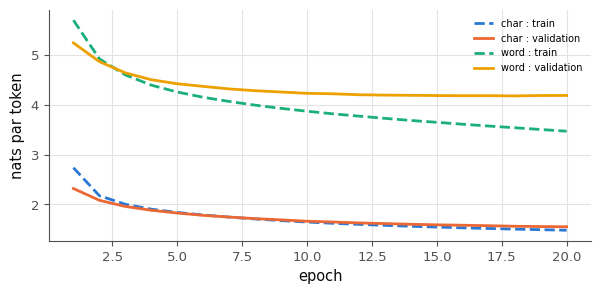

char  T = 0.5 : 'Holmes which were a man of a singular and chair to me that he had a went was a langer which he said the companion which I did he had for your ever the brown for the points to be a cold to the distriding upon the man which had been singular '
char  T = 1.0 : 'Holmes chaning your dark for an your. He such one discale had excearness you a lettlet. The side, and.\nHe word address your seeming in sturely a seeutecions,” are this narreep.\n\n“I seed to see precusiony.”\n\n“Hink modrel. Filse in my\ndiscon.'
char  T = 1.5 : 'Holmess.\nHe wonge. It is Majesse. Yope whah\nsee of gabed hourg whethen ould he seem?”\n\n“And home, sie_py, prected broumble\nyet with ranceDe when a titty’s\nchuse. Helpered, a ville many one stailley-swits,”\nsaic made.”\n\nA Paganding. Pownate?'
word  T = 0.5 : 'holmes , and a <unk> <unk> , and i <unk> his <unk> . “ i have not you to be too <unk> as to <unk> and <unk> ? ” “ what did you see that you had done with you , ” said he . “ he <unk> me , ” s

In [86]:
HISTORY_30 = {   # 20 epochs on the whole text (tools/chapters/history_ch24.py)
    "char": {"train_loss": [2.73508, 2.17237, 2.00059, 1.90207, 1.83633, 1.7854, 1.74268, 1.70579, 1.67196, 1.64373, 1.61868, 1.59695, 1.57656, 1.5585, 1.54296, 1.52722, 1.51401, 1.50132, 1.48996, 1.47912], "val_loss": [2.31684, 2.08045, 1.95707, 1.88025, 1.82474, 1.77785, 1.74399, 1.71178, 1.68723, 1.65979, 1.6442, 1.62584, 1.61286, 1.59831, 1.58765, 1.57918, 1.57002, 1.55878, 1.55303, 1.54895],
             "samples": {"0.5": "Holmes which were a man of a singular and chair to me that he had a went was a langer which he said the companion which I did he had for your ever the brown for the points to be a cold to the distriding upon the man which had been singular things the danger the company in the man of the complete very seen", "1.0": "Holmes chaning your dark for an your. He such one discale had excearness you a lettlet. The side, and.\nHe word address your seeming in sturely a seeutecions,” are this narreep.\n\n“I seed to see precusiony.”\n\n“Hink modrel. Filse in my\ndiscon. My trink at the bedushed. His late, it is who congulto’s—it, and ", "1.5": "Holmess.\nHe wonge. It is Majesse. Yope whah\nsee of gabed hourg whethen ould he seem?”\n\n“And home, sie_py, prected broumble\nyet with ranceDe when a titty’s\nchuse. Helpered, a ville many one stailley-swits,”\nsaic made.”\n\nA Paganding. Pownate? You fingeh a behg got, ‘K gusled is uncon\nyourch from Joâs Lentur"}},
    "word": {"train_loss": [5.69989, 4.92386, 4.60049, 4.39483, 4.2565, 4.15087, 4.06722, 3.99269, 3.92819, 3.87071, 3.8181, 3.7723, 3.72741, 3.68524, 3.64762, 3.60924, 3.573, 3.53886, 3.50355, 3.46938], "val_loss": [5.2438, 4.86785, 4.64202, 4.50372, 4.42287, 4.37008, 4.31902, 4.28312, 4.25694, 4.23074, 4.22092, 4.20219, 4.19495, 4.19077, 4.18539, 4.18311, 4.1833, 4.17862, 4.18651, 4.18729],
             "samples": {"0.5": "holmes , and a <unk> <unk> , and i <unk> his <unk> . “ i have not you to be too <unk> as to <unk> and <unk> ? ” “ what did you see that you had done with you , ” said he . “ he <unk> me , ” said he , “ it is <unk> to me ,", "1.0": "holmes , or out of the <unk> that we have known a pretty light . that was it upon the patient , so i have looked to visit to work upon anyone of the chance of a handkerchief home to <unk> as the matter as if your business may <unk> it . ” “ but are they <unk> her that the", "1.5": "holmes ! chance what after the first account here . save it matters ever was still ; but then to spare you dressing - chair upon the mantelpiece . far every cripple could very walk question with eyford colour in the importance . have once done anything in impossible , when you think you am remarkable months , most certainly ,"}},
}

fig_30, ax_30 = plt.subplots(figsize=(7, 3))
for name_30, h_30 in HISTORY_30.items():
    ax_30.plot(range(1, 21), h_30["train_loss"], "--", label=f"{name_30} : train")
    ax_30.plot(range(1, 21), h_30["val_loss"], label=f"{name_30} : validation")
ax_30.set_xlabel("epoch")
ax_30.set_ylabel("nats par token")
ax_30.legend(fontsize=7)
plt.show()
for name_30, h_30 in HISTORY_30.items():
    for temperature_30, sample_30 in h_30["samples"].items():
        print(f"{name_30:5s} T = {temperature_30} : {sample_30[:240]!r}")

💡 Un modèle non entraîné donne à peu près la même probabilité $1/V$ à chaque token : sa loss vaut $\ln V$ et sa perplexité $e^{\ln V} = V$ (2 001 ici). Les perplexités ne se comparent qu'à vocabulaire égal : en mode rapide, le modèle de mots a une perplexité de 214 et celui de caractères de 8,1, mais prédire un mot parmi 2 001 n'est pas prédire un caractère parmi 86. En divisant la loss totale par le nombre de caractères du texte, on compare la même chose : combien de nats il faut, par caractère, pour coder la validation. Le modèle de mots semble alors bien meilleur (1,21 nat par caractère contre 2,09 en mode rapide ; 0,95 contre 1,55 après 20 epochs sur tout le texte), mais il triche : 6 % des tokens (8 % sur tout le texte) sont `<unk>`, un « mot » facile à prédire qui remplace des centaines de mots rares ; il ne sait pas écrire ces mots-là, le modèle de caractères si. À basse température, les textes répètent des tournures sûres (« the <unk> of the <unk> ») ; à haute température, le modèle de caractères invente des mots et celui de mots enchaîne des mots sans lien.

### Ex 24.31 — Défi CIFAR-10 frugal : au moins 80 % de test accuracy avec moins de 100 000 paramètres 🏆 ★★★★ ⏱️ 180 min
**Objectif :** assembler augmentation, blocs résiduels, planning et régularisation pour un CNN petit et précis.  
**Prérequis :** Ex 24.23 · Ex 24.28 · ch. 23 (Ex 23.29, défi) · fiche §24.4.5, §24.4.6, §24.6.2 · **Fil rouge :** CIFAR-10 · **Parcours :** C

Le défi : une recette `train_31(seed, images, labels)` qui construit un CNN de **moins de 100 000 paramètres** et l'entraîne sur les images d'entraînement de CIFAR-10, tout son hasard tiré de `seed`.

**Objectif**
- en mode complet (sur un GPU, Colab) : au moins **80 %** d'accuracy de test, en s'entraînant sur les 45 000 images d'entraînement ;
- en mode rapide (sur un CPU) : la même recette, plus courte, sur 10 000 images, avec un objectif de **60 %** (`GOAL_31`) ;
- d'abord sur la validation (les 5 000 dernières images du fichier) ; si l'objectif est atteint, la cellule révèle le **test**, une seule fois par architecture et par session (relancer la cellule avec le même modèle montre le même résultat figé).

**Contrat** : `train_31(seed, images, labels)` reçoit les images `uint8` $(N, 32, 32, 3)$ et leurs labels, et rend le modèle entraîné ; la cellule de notation lui donne des images préparées par `to_input_c` (`float32` $(N, 3, 32, 32)$, standardisées par canal) et attend des logits $(N, 10)$.

Point de départ : ton ResNet de 24.28 (78 042 paramètres), entraîné comme les CNN de la partie C. Tout ce que tu as vu sert : l'augmentation (24.23), la batchnorm (24.21), un planning de learning rate (ch. 23), le label smoothing, le weight decay, la taille de batch… En ne regardant que la validation.

Dans tes notes : ta recette, les essais qui ont échoué, et ce qui a le plus aidé.

In [87]:
N_31 = 10_000 if FAST_MODE else 45_000
GOAL_31 = 0.60 if FAST_MODE else 0.80        # test accuracy to reach
MAX_PARAMS_31 = 100_000
X31, Y31 = _XC[:N_31], _YC[:N_31].astype(np.int64)      # uint8 (N, 32, 32, 3) images and labels: prepare them your way
X31_TEST_T, Y31_TEST_T = to_input_c(XC_TEST), torch.from_numpy(YC_TEST)


def grade_31(train_fn, seed=0):
    """Train with train_fn(seed, X31, Y31), check the size of the model, measure the validation accuracy and the time."""
    started = time.perf_counter()
    model = train_fn(seed, X31, Y31)
    seconds = time.perf_counter() - started
    model.to(DEVICE).eval()
    return model, n_params(model), evaluate(model, XC_VAL_T, YC_VAL_T)[1], seconds

In [88]:
EPOCHS_31 = 8 if FAST_MODE else 30


def train_31(seed, images, labels, epochs=EPOCHS_31):
    """Build a model of fewer than MAX_PARAMS_31 parameters and train it on the uint8 images (N, 32, 32, 3) and their
    labels, everything random drawn from `seed`; return the trained model. The grader feeds it images prepared by
    to_input_c (float32 (N, 3, 32, 32), standardised per channel) and expects logits (N, 10)."""
    torch.manual_seed(seed)
    model = make_resnet_28().to(DEVICE)                            # 78 042 parameters
    train_tf, _ = make_transforms_23(augment=True)                 # crops and left-right mirrors
    loader = make_train_loader_23(CifarImages_23(images, labels, train_tf), batch_size=128, seed=seed)
    optimizer = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=5e-4)
    schedule = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=0.1, total_steps=epochs * len(loader))
    loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)
    for _ in range(epochs):
        model.train()
        for xb, yb in loader:
            loss = loss_fn(model(xb.to(DEVICE)), yb.to(DEVICE))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            schedule.step()                                        # OneCycleLR: one step per mini-batch
    return model


with checked("24.31"):
    model_31, count_31, val_31, seconds_31 = grade_31(train_31)
    print(f"{count_31} paramètres · validation {val_31:.4f} · {seconds_31:.0f} s d'entraînement")
    if count_31 >= MAX_PARAMS_31:
        print(f"❌ Ex 24.31 : {count_31} paramètres : il en faut moins de {MAX_PARAMS_31}.")
    elif val_31 < GOAL_31:
        print(f"❌ Ex 24.31 : sur la validation, il faut au moins {fr(100 * GOAL_31, 0)} % avant de révéler le test.")
    else:
        TESTS_31 = globals().setdefault("TESTS_31", {})               # revealed once per architecture and session
        signature_31 = (count_31, str(model_31)[:2000])
        if signature_31 not in TESTS_31:
            TESTS_31[signature_31] = evaluate(model_31, X31_TEST_T, Y31_TEST_T)[1]
        test_31 = TESTS_31[signature_31]
        print(f"test (révélé une fois par architecture et par session) : {test_31:.4f}")
        verdict("24.31", test_31 >= GOAL_31,
                f"défi réussi : {fr(100 * test_31, 1)} % sur le test avec {count_31} paramètres.",
                f"pas encore : {fr(100 * test_31, 1)} % sur le test. Ce résultat est figé pour cette architecture et cette "
                "session : améliore ta recette en ne regardant que la validation.")

78042 paramètres · validation 0.6352 · 100 s d'entraînement


test (révélé une fois par architecture et par session) : 0.6310
✅ Ex 24.31 : défi réussi : 63,1 % sur le test avec 78042 paramètres.


💡 La recette de référence : le ResNet de 24.28 (78 042 paramètres), l'augmentation de 24.23 (recadrages décalés et miroirs), SGD avec un momentum de Nesterov de 0,9 et un weight decay de 0,0005, un planning `OneCycleLR` jusqu'à 0,1, un label smoothing de 0,1 et des mini-batches de 128. En mode complet, 30 epochs sur les 45 000 images atteignent 85,4 % sur le test (calculé par `tools/chapters/history_ch24.py` : une minute par epoch sur 2 CPU, quelques secondes sur un GPU). En mode rapide, 8 epochs sur 10 000 images donnent 62 à 64 % selon la graine (entrée `calib`), juste au-dessus de l'objectif ; là, l'augmentation ne paie pas encore (sans elle : 65,8 %), car 8 epochs ne suffisent pas à surapprendre. Sur un entraînement long, c'est l'inverse, comme l'historique de 24.23 l'a montré pour le CNN profond : sans augmentation, le réseau apprend le train par cœur ; le planning, qui finit à un learning rate presque nul, apporte les derniers points.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu mener une amélioration par expériences (un réglage à la fois, un journal) et chiffrer le coût d'une recherche d'hyperparamètres ?
2. Sais-tu envelopper un réseau PyTorch dans un estimateur scikit-learn et le valider sans fuite ?
3. Sais-tu construire un CNN et un LSTM en PyTorch, lire leurs formes, et écrire un bloc résiduel dans `forward()` ?

**Pour aller plus loin** : le « Deep Learning Tuning Playbook » de Google et l'article de He et coll. (2016), cités dans la fiche. La suite : le checkpoint de la partie V, puis le ch. 25, les autoencodeurs.